# Proyecto: Predicción de la Calificación Crediticia Corporativa

### Universidad de Medellín

### Facultad de Ingenierías

### Presentado : Valeria Duque Moreno , Deyson Ortiz Restrepo

#### Profesor: Antonio Jesús Tamayo Herrera, PhD


## Base de datos: *Corporate Credit Rating* (Kaggle – agewerc)

**Contenido del notebook**

1. Carga de librerías y descarga de la base de datos
2. Descripción detallada de la base de datos (dominio, utilidad, variables, variable de salida, tipo de problema)
3. Análisis exploratorio de datos (EDA)
   - 3.1 Estructura general, tipos de datos y calidad (nulos, duplicados)
   - 3.2 Variable de salida `Rating`
   - 3.3 Variables categóricas
   - 3.4 Variable temporal `Date`
   - 3.5 Variables numéricas: estadística descriptiva, rango, escala, asimetría y atípicos
   - 3.6 Análisis individual de cada indicador financiero
   - 3.7 Relación entre variables (correlaciones y relación con el `Rating`)
4. Conclusiones preliminares del EDA
5. Eliminación de las variables descartadas y preprocesamiento
6. Análisis comparativo: base original (10 clases) vs. base agrupada (grado de inversión / especulativo)
7. Aprendizaje no supervisado (**punto 5**): K‑Means, Clustering jerárquico aglomerativo y DBSCAN
8. Comparación de modelos y selección del mejor (**punto 6**)
9. Conclusiones finales

**PARTE 2 – Reducción de dimensión + Redes Neuronales Artificiales** (validación `StratifiedKFold`, ambos escenarios)

10. Configuración común y RNA base
11. Punto 1: selección de características con **SFFS** (wrapper, mlxtend) + RNA
12. Punto 2: variables más importantes (discriminantes)
13. Punto 3: reducción de dimensión con **PCA** + RNA
14. Punto 4: reducción de dimensión con **LDA** + RNA
15. Comparación final de estrategias
16. Conclusiones de la Parte 2

> Fuente: https://www.kaggle.com/datasets/agewerc/corporate-credit-rating

## 1. Librerías y descarga de la base de datos

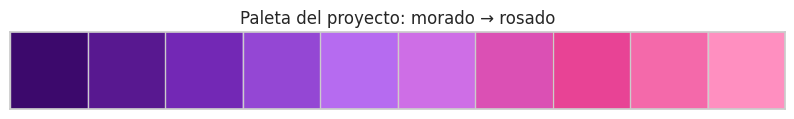

In [1]:
!pip install kagglehub seaborn mlxtend

import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.dpi"] = 100

# ==========================================================
# PALETA DE COLORES DEL PROYECTO: de MORADO a ROSADO
# ==========================================================
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

MORADO, LILA, ROSADO = "#3c096c", "#9d4edd", "#e5398f"
CMAP_MR = LinearSegmentedColormap.from_list(          # secuencial morado -> rosado
    "morado_rosado", ["#3c096c", "#7b2cbf", "#c77dff", "#e5398f", "#ff8fc0"])
CMAP_MR_CLARO = LinearSegmentedColormap.from_list(    # para mapas de calor (claro -> morado)
    "rosado_morado_calor", ["#fff0f6", "#ffb3d9", "#e5398f", "#9d4edd", "#3c096c"])
CMAP_MR_DIV = LinearSegmentedColormap.from_list(      # divergente: morado (-) / blanco (0) / rosado (+)
    "morado_blanco_rosado", ["#3c096c", "#9d4edd", "#f7f2fa", "#ff70a6", "#b5175e"])
for _c in (CMAP_MR, CMAP_MR_CLARO, CMAP_MR_DIV):
    try:
        mpl.colormaps.register(_c)
    except ValueError:
        pass  # ya registrada (si la celda se ejecuta dos veces)

def paleta(n):
    # Devuelve n colores equiespaciados de morado a rosado
    return [mpl.colors.to_hex(CMAP_MR(i / max(n - 1, 1))) for i in range(n)]

sns.set_theme(style="whitegrid")
sns.set_palette(paleta(8))
sns.palplot(paleta(10)); plt.title("Paleta del proyecto: morado → rosado"); plt.show()

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("agewerc/corporate-credit-rating")

print("Path to dataset files:", path)
print("Archivos disponibles:", os.listdir(path))

100%|██████████| 299k/299k [00:00<00:00, 44.8MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/agewerc/corporate-credit-rating/versions/1
Archivos disponibles: ['corporate_rating.csv']


In [3]:
# Se carga el archivo CSV que contiene la base de datos (corporate_rating.csv)
csv_file = glob.glob(os.path.join(path, "*.csv"))[0]
df = pd.read_csv(csv_file)
print("Archivo cargado:", os.path.basename(csv_file))
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

Archivo cargado: corporate_rating.csv
Dimensiones: 2029 filas x 31 columnas


,Rating,Name,Symbol,Rating Agency Name,Date,Sector,currentRatio,quickRatio,cashRatio,daysOfSalesOutstanding,netProfitMargin,pretaxProfitMargin,grossProfitMargin,operatingProfitMargin,returnOnAssets,returnOnCapitalEmployed,returnOnEquity,assetTurnover,fixedAssetTurnover,debtEquityRatio,debtRatio,effectiveTaxRate,freeCashFlowOperatingCashFlowRatio,freeCashFlowPerShare,cashPerShare,companyEquityMultiplier,ebitPerRevenue,enterpriseValueMultiple,operatingCashFlowPerShare,operatingCashFlowSalesRatio,payablesTurnover
0,A,Whirlpool Corporation,WHR,Egan-Jones Ratings Company,11/27/2015,Consumer Durables,0.9459,0.4264,0.0997,44.2032,0.0375,0.0494,0.1766,0.0615,0.0412,0.0915,0.1651,1.0989,5.5355,3.0080,0.7505,0.2027,0.4376,6.8107,9.8094,4.0080,0.0494,7.0571,15.5654,0.0586,3.9067
1,BBB,Whirlpool Corporation,WHR,Egan-Jones Ratings Company,2/13/2014,Consumer Durables,1.0336,0.4982,0.2031,38.9912,0.0441,0.0489,0.1757,0.0665,0.0532,0.1048,0.1680,1.2075,6.1720,2.1568,0.6832,0.0742,0.5420,8.6255,17.4023,3.1568,0.0489,6.4606,15.9142,0.0672,4.0028
2,BBB,Whirlpool Corporation,WHR,Fitch Ratings,3/6/2015,Consumer Durables,0.9637,0.4515,0.1221,50.8414,0.0327,0.0443,0.1708,0.0598,0.0325,0.0760,0.1331,0.9935,4.9917,3.0946,0.7558,0.2145,0.5132,9.6935,13.1034,4.0946,0.0443,10.4920,18.8889,0.0744,3.4835
3,BBB,Whirlpool Corporation,WHR,Fitch Ratings,6/15/2012,Consumer Durables,1.0199,0.5104,0.1761,41.1617,0.0209,-0.0129,0.1381,0.0424,0.0257,-0.0270,0.0933,1.2296,6.0174,2.6309,0.7246,1.8167,-0.1472,-1.0156,14.4401,3.6309,-0.0129,4.0807,6.9010,0.0284,4.5812
4,BBB,Whirlpool Corporation,WHR,Standard & Poor's Ratings Services,10/24/2016,Consumer Durables,0.9578,0.4954,0.1416,47.7611,0.0429,0.0538,0.1777,0.0654,0.0464,0.0969,0.1860,1.0817,5.4378,3.0128,0.7508,0.1670,0.4514,7.1353,14.2576,4.0128,0.0538,8.2935,15.8081,0.0581,3.8578


## 2. Descripción de la base de datos

### 2.1 Dominio del problema
El problema pertenece al dominio de las **finanzas corporativas y la gestión del riesgo de crédito**. Una **calificación crediticia (credit rating)** es una opinión emitida por una agencia calificadora (Standard & Poor's, Moody's, Fitch, Egan‑Jones, etc.) sobre la capacidad y disposición de una empresa para cumplir con sus obligaciones financieras (pagar su deuda). La calificación se expresa en una escala de letras, desde **AAA** (máxima solvencia, riesgo mínimo) hasta **D** (incumplimiento / *default*).

La base de datos contiene **2.029 calificaciones crediticias** emitidas a **593 grandes empresas que cotizan en bolsa en EE. UU.** (NYSE / NASDAQ), principalmente entre **2010 y 2016** (con algunos registros desde 2005), junto con **25 indicadores financieros** de cada empresa calculados a partir de sus estados financieros, más información de identificación (nombre, símbolo bursátil, sector, agencia y fecha de la calificación).

### 2.2 Utilidad
- Las agencias calificadoras analizan cientos de documentos, por lo que su proceso es **costoso y lento**, y muchas empresas pequeñas o no listadas **no tienen calificación**.
- Un modelo que **estime la calificación a partir de los indicadores financieros** permite:
  - Anticipar cambios de calificación (*upgrades / downgrades*).
  - Evaluar el riesgo de empresas sin calificación oficial.
  - Apoyar decisiones de inversión, fijación de tasas de interés de bonos, otorgamiento de préstamos y cumplimiento regulatorio (p. ej. Basilea).
  - Entender qué indicadores (liquidez, rentabilidad, endeudamiento, eficiencia) pesan más en el riesgo de crédito.

### 2.3 Variables
La base tiene **31 columnas**: 6 descriptivas (incluida la variable de salida) y 25 indicadores financieros numéricos.

**a) Variables de identificación / categóricas**

| Variable | Descripción | Tipo |
|---|---|---|
| `Rating` | Calificación crediticia asignada (AAA, AA, A, BBB, BB, B, CCC, CC, C, D) | Categórica **ordinal** – **variable de salida** |
| `Name` | Nombre de la empresa | Categórica nominal (identificador) |
| `Symbol` | Símbolo bursátil (*ticker*) | Categórica nominal (identificador) |
| `Rating Agency Name` | Agencia que emite la calificación | Categórica nominal |
| `Date` | Fecha de emisión de la calificación | Fecha / temporal |
| `Sector` | Sector económico de la empresa | Categórica nominal |

**b) Indicadores financieros (numéricos continuos, escala de razón)**

| Grupo | Variable | Significado |
|---|---|---|
| **Liquidez** | `currentRatio` | Activo corriente / Pasivo corriente |
| | `quickRatio` | (Activo corriente − Inventarios) / Pasivo corriente |
| | `cashRatio` | Efectivo / Pasivo corriente |
| | `daysOfSalesOutstanding` | Días promedio de cobro a clientes |
| **Rentabilidad** | `netProfitMargin` | Utilidad neta / Ventas |
| | `pretaxProfitMargin` | Utilidad antes de impuestos / Ventas |
| | `grossProfitMargin` | Utilidad bruta / Ventas |
| | `operatingProfitMargin` | Utilidad operativa / Ventas |
| | `returnOnAssets` (ROA) | Utilidad neta / Activos totales |
| | `returnOnCapitalEmployed` (ROCE) | EBIT / Capital empleado |
| | `returnOnEquity` (ROE) | Utilidad neta / Patrimonio |
| | `ebitPerRevenue` | EBIT / Ventas |
| **Eficiencia / rotación** | `assetTurnover` | Ventas / Activos totales |
| | `fixedAssetTurnover` | Ventas / Activos fijos |
| | `payablesTurnover` | Rotación de cuentas por pagar |
| **Endeudamiento / apalancamiento** | `debtEquityRatio` | Deuda total / Patrimonio |
| | `debtRatio` | Deuda total / Activos totales |
| | `companyEquityMultiplier` | Activos totales / Patrimonio |
| **Flujo de caja** | `freeCashFlowOperatingCashFlowRatio` | Flujo de caja libre / Flujo de caja operativo |
| | `freeCashFlowPerShare` | Flujo de caja libre por acción |
| | `cashPerShare` | Efectivo por acción |
| | `operatingCashFlowPerShare` | Flujo de caja operativo por acción |
| | `operatingCashFlowSalesRatio` | Flujo de caja operativo / Ventas |
| **Otros** | `effectiveTaxRate` | Tasa efectiva de impuestos |
| | `enterpriseValueMultiple` | Valor empresa / EBITDA (múltiplo de valoración) |

### 2.4 Variable de salida
La variable objetivo es **`Rating`**, que toma 10 valores ordenados de mejor a peor:

`AAA > AA > A > BBB > BB > B > CCC > CC > C > D`

- **AAA a BBB** → *Grado de inversión* (*investment grade*): bajo riesgo de impago.
- **BB a D** → *Grado especulativo* (*high yield* / "bonos basura"): riesgo de impago elevado.

### 2.5 Tipo de problema
- **Aprendizaje supervisado** (cada registro tiene la etiqueta `Rating`).
- **Clasificación multiclase** (10 clases) con naturaleza **ordinal**; también puede plantearse como:
  - clasificación con clases agrupadas (p. ej. AAA‑AA / A / BBB / BB / B / CCC‑D), o
  - **clasificación binaria**: *Grado de inversión* vs. *Grado especulativo*.
- Datos **tabulares**, con predictores numéricos continuos y algunas variables categóricas (`Sector`, `Rating Agency Name`).
- Retos anticipados: **desbalance de clases** y **valores atípicos extremos** en los indicadores financieros (se verifican en el EDA).

## 3. Análisis exploratorio de datos (EDA)
### 3.1 Estructura general, tipos de datos y calidad

In [4]:
print(f"Número de registros: {df.shape[0]}")
print(f"Número de variables: {df.shape[1]}\n")
df.info()

Número de registros: 2029
Número de variables: 31

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2029 entries, 0 to 2028
Data columns (total 31 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Rating                              2029 non-null   object 
 1   Name                                2029 non-null   object 
 2   Symbol                              2029 non-null   object 
 3   Rating Agency Name                  2029 non-null   object 
 4   Date                                2029 non-null   object 
 5   Sector                              2029 non-null   object 
 6   currentRatio                        2029 non-null   float64
 7   quickRatio                          2029 non-null   float64
 8   cashRatio                           2029 non-null   float64
 9   daysOfSalesOutstanding              2029 non-null   float64
 10  netProfitMargin                     2029 non-null   float

In [5]:
# Resumen de tipo de cada variable, valores únicos, nulos y un ejemplo
resumen = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "nulos": df.isnull().sum(),
    "%_nulos": (df.isnull().mean() * 100).round(2),
    "ejemplo": df.iloc[0],
})
resumen

,tipo_pandas,valores_unicos,nulos,%_nulos,ejemplo
Rating,object,10,0,0.0000,A
Name,object,593,0,0.0000,Whirlpool Corporation
Symbol,object,593,0,0.0000,WHR
Rating Agency Name,object,5,0,0.0000,Egan-Jones Ratings Company
Date,object,904,0,0.0000,11/27/2015
Sector,object,12,0,0.0000,Consumer Durables
currentRatio,float64,2029,0,0.0000,0.9459
quickRatio,float64,2029,0,0.0000,0.4264
cashRatio,float64,2025,0,0.0000,0.0997
daysOfSalesOutstanding,float64,1836,0,0.0000,44.2032


In [6]:
print("Total de valores nulos en la base:", int(df.isnull().sum().sum()))
print("Filas duplicadas exactas:", df.duplicated().sum())
print("Empresas distintas (Symbol):", df["Symbol"].nunique())
print("Promedio de calificaciones por empresa:", round(len(df) / df["Symbol"].nunique(), 2))

Total de valores nulos en la base: 0
Filas duplicadas exactas: 0
Empresas distintas (Symbol): 593
Promedio de calificaciones por empresa: 3.42


**Análisis preliminar:**
- Las 6 primeras columnas son de tipo `object` (texto) y los 25 indicadores son `float64`.
- La columna `Date` se lee como texto, por lo que se convertirá a tipo fecha.
- La base **no presenta valores nulos (0)** ni filas duplicadas exactas (0); no es necesario imputar.
- Hay **593 empresas distintas** con **3,42 calificaciones en promedio** cada una: una misma empresa aparece varias veces (distintas agencias o fechas), por lo que **los registros no son totalmente independientes**; esto debe tenerse en cuenta al dividir en entrenamiento/prueba (idealmente agrupar por empresa).
- `Name` y `Symbol` son **identificadores** y no aportan capacidad predictiva generalizable; se excluirán del modelo.

### 3.2 Variable de salida: `Rating`

In [7]:
orden_rating = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC", "CC", "C", "D"]
df["Rating"] = pd.Categorical(df["Rating"], categories=orden_rating, ordered=True)

frec = df["Rating"].value_counts().reindex(orden_rating)
tabla_rating = pd.DataFrame({"frecuencia": frec,
                             "porcentaje": (frec / len(df) * 100).round(2)})
tabla_rating["% acumulado"] = tabla_rating["porcentaje"].cumsum().round(2)
tabla_rating

,frecuencia,porcentaje,% acumulado
Rating,,,
AAA,7,0.3400,0.3400
AA,89,4.3900,4.7300
A,398,19.6200,24.3500
BBB,671,33.0700,57.4200
BB,490,24.1500,81.5700
B,302,14.8800,96.4500
CCC,64,3.1500,99.6000
CC,5,0.2500,99.8500
C,2,0.1000,99.9500


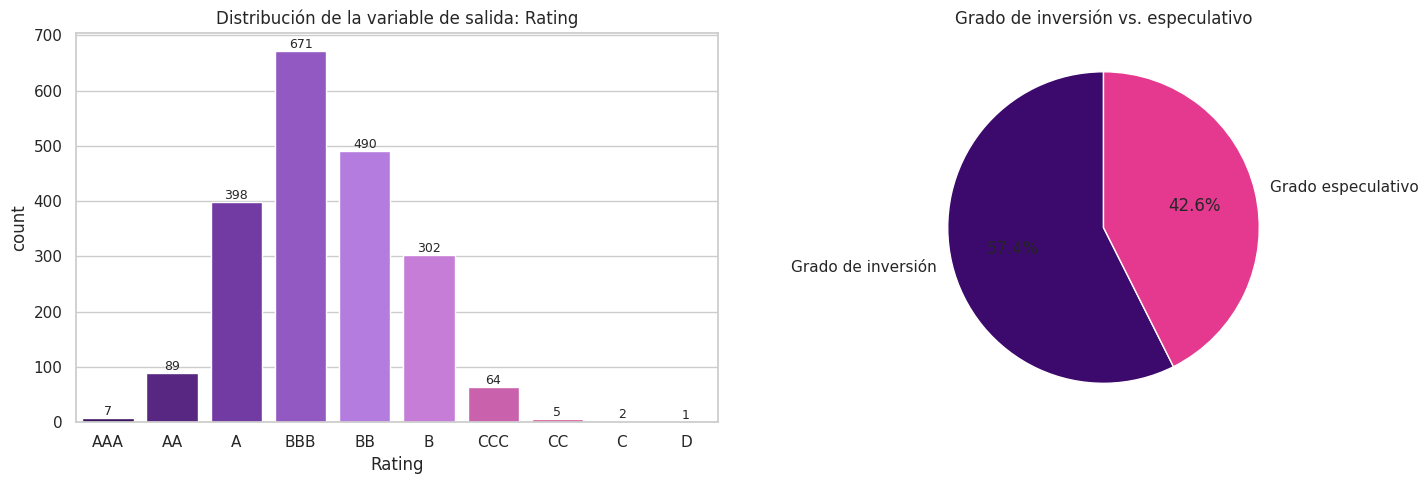

Razón de desbalance (clase más frecuente / menos frecuente): 671.0


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(data=df, x="Rating", order=orden_rating, ax=ax[0], palette=paleta(10))
ax[0].set_title("Distribución de la variable de salida: Rating")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                   ha="center", va="bottom", fontsize=9)

grado = np.where(df["Rating"].isin(["AAA", "AA", "A", "BBB"]),
                 "Grado de inversión", "Grado especulativo")
pd.Series(grado).value_counts().plot.pie(autopct="%1.1f%%", ax=ax[1],
                                         colors=[MORADO, ROSADO], startangle=90)
ax[1].set_ylabel(""); ax[1].set_title("Grado de inversión vs. especulativo")
plt.tight_layout(); plt.show()

print("Razón de desbalance (clase más frecuente / menos frecuente):",
      round(frec.max() / frec[frec > 0].min(), 1))

**Análisis preliminar de `Rating`:**
- **Tipo:** categórica **ordinal** con 10 niveles; escala ordinal (hay orden de riesgo, pero la "distancia" entre niveles no es medible).
- **Desbalance fuerte:** **BBB** (671; 33,1 %), **BB** (490; 24,2 %), **A** (398; 19,6 %) y **B** (302; 14,9 %) concentran el **91,7 %** de los registros, mientras que los extremos casi no tienen muestras: **AAA = 7**, **CC = 5**, **C = 2** y **D = 1**. La razón de desbalance (clase mayor / clase menor) es **671 : 1**.
- Con tan pocos ejemplos, un modelo **no podrá aprender las clases extremas**; se recomienda **agrupar clases** (p. ej. AAA+AA, CCC+CC+C+D) o usar la versión binaria *inversión vs. especulativo*, además de técnicas como `class_weight`, SMOTE o métricas como F1‑macro en lugar de *accuracy*.
- La división binaria es mucho más equilibrada: **grado de inversión = 1.165 (57,4 %)** vs. **grado especulativo = 864 (42,6 %)**, por lo que es una alternativa robusta para el modelado (se compara en la sección 6).

### 3.3 Variables categóricas: `Rating Agency Name`, `Sector`, `Name`, `Symbol`

In [9]:
for col in ["Rating Agency Name", "Sector"]:
    t = df[col].value_counts()
    print(f"\n===== {col}  ({df[col].nunique()} categorías) =====")
    print(pd.DataFrame({"frecuencia": t, "%": (t/len(df)*100).round(2)}))


===== Rating Agency Name  (5 categorías) =====
                                    frecuencia       %
Rating Agency Name                                    
Standard & Poor's Ratings Services         744 36.6700
Egan-Jones Ratings Company                 603 29.7200
Moody's Investors Service                  579 28.5400
Fitch Ratings                              100  4.9300
DBRS                                         3  0.1500

===== Sector  (12 categorías) =====
                       frecuencia       %
Sector                                   
Energy                        294 14.4900
Basic Industries              260 12.8100
Consumer Services             250 12.3200
Technology                    234 11.5300
Capital Goods                 233 11.4800
Public Utilities              211 10.4000
Health Care                   171  8.4300
Consumer Non-Durables         132  6.5100
Consumer Durables              74  3.6500
Transportation                 63  3.1000
Miscellaneous             

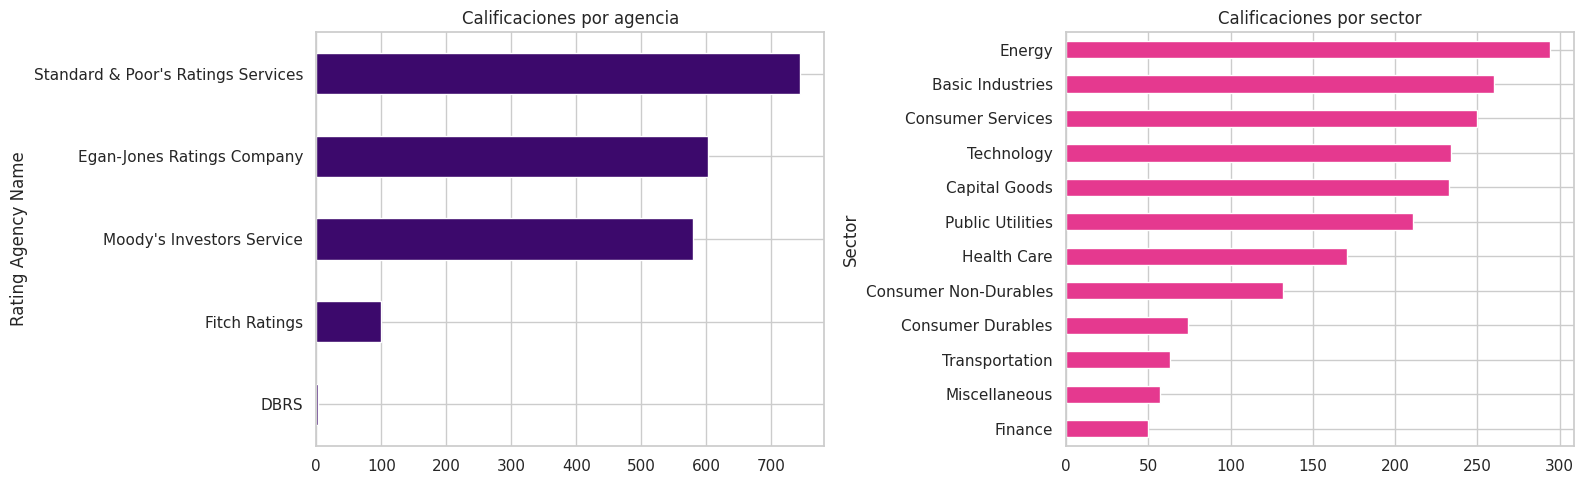

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
df["Rating Agency Name"].value_counts().plot.barh(ax=ax[0], color=MORADO)
ax[0].set_title("Calificaciones por agencia"); ax[0].invert_yaxis()
df["Sector"].value_counts().plot.barh(ax=ax[1], color=ROSADO)
ax[1].set_title("Calificaciones por sector"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

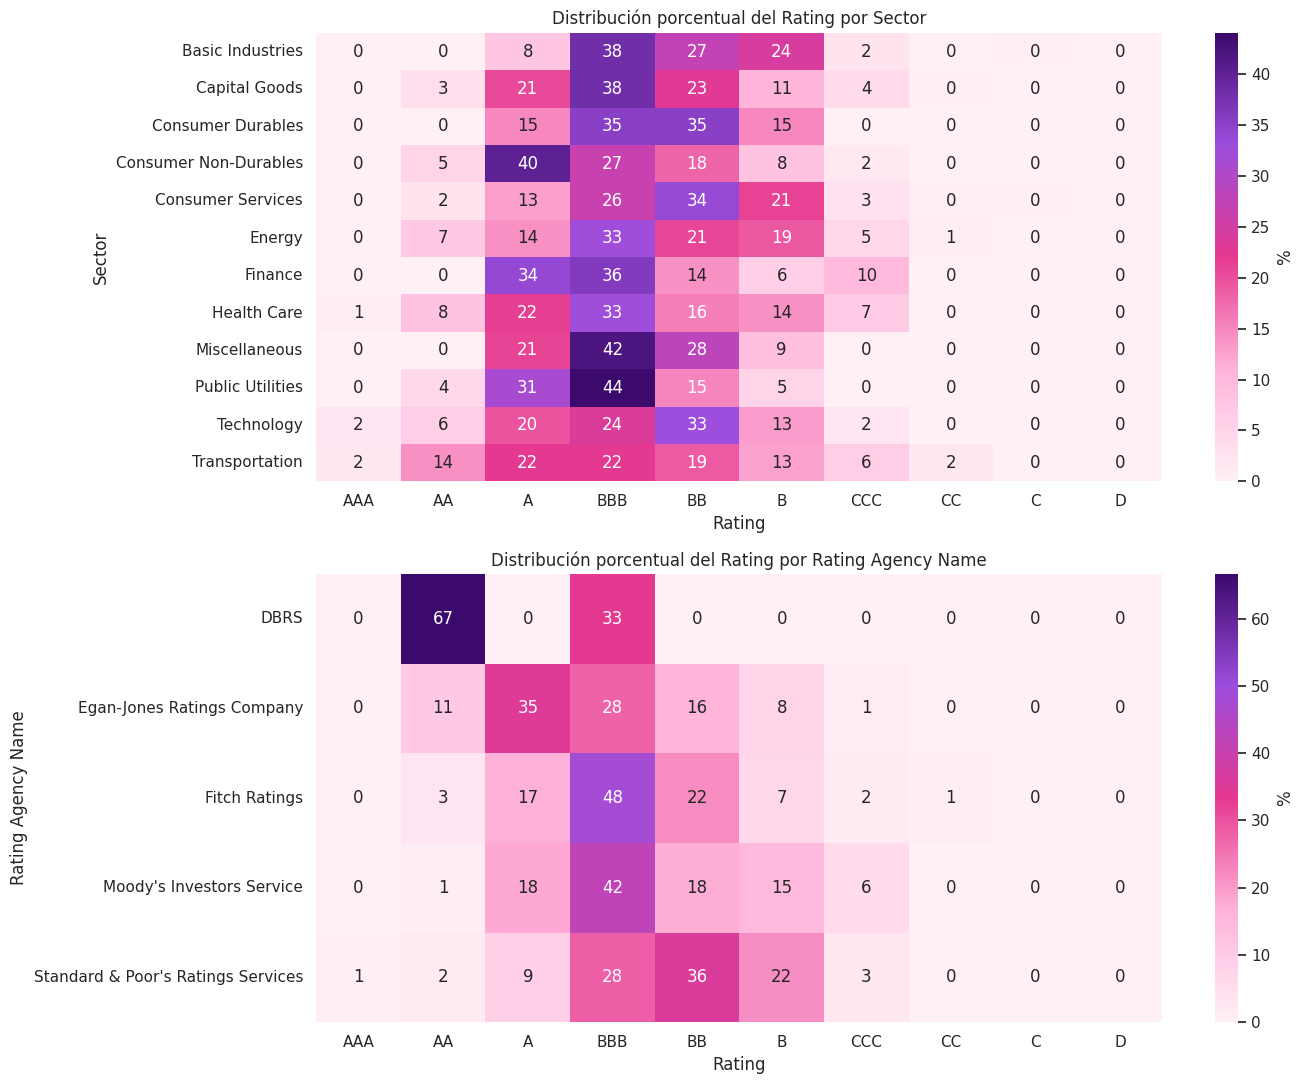

In [11]:
# Composición de Rating dentro de cada Sector y de cada agencia (% por fila)
fig, ax = plt.subplots(2, 1, figsize=(14, 11))
for a, col in zip(ax, ["Sector", "Rating Agency Name"]):
    ct = pd.crosstab(df[col], df["Rating"], normalize="index") * 100
    sns.heatmap(ct, annot=True, fmt=".0f", cmap=CMAP_MR_CLARO, ax=a, cbar_kws={"label": "%"})
    a.set_title(f"Distribución porcentual del Rating por {col}")
plt.tight_layout(); plt.show()

**Análisis preliminar de variables categóricas:**
- **`Rating Agency Name`** – categórica nominal con **5 categorías**: **Standard & Poor's (744; 36,7 %)**, **Egan‑Jones (603; 29,7 %)**, **Moody's (579; 28,5 %)**, **Fitch (100; 4,9 %)** y **DBRS (3; 0,15 %)**. Las tres primeras concentran el 95 % de las calificaciones. Puede influir en el resultado si cada agencia califica con criterios ligeramente distintos.
- **`Sector`** – categórica nominal con **12 sectores**, distribuidos de forma relativamente pareja: *Energy* (294; 14,5 %), *Basic Industries* (260; 12,8 %), *Consumer Services* (250; 12,3 %), *Technology* (234; 11,5 %), *Capital Goods* (233; 11,5 %) y *Public Utilities* (211; 10,4 %) son los mayores; *Transportation* (63), *Miscellaneous* (57) y *Finance* (50; 2,5 %) los menores. El mapa de calor muestra que la **composición del rating varía por sector**, por lo que es una variable potencialmente útil (requiere codificación *one‑hot*).
- **`Name` / `Symbol`** – nominales de alta cardinalidad (**593 valores únicos**); son identificadores y no se usan como predictores, aunque `Symbol` sirve para agrupar la validación por empresa.

### 3.4 Variable temporal: `Date`

Rango de fechas: 2005-08-16 → 2016-12-23


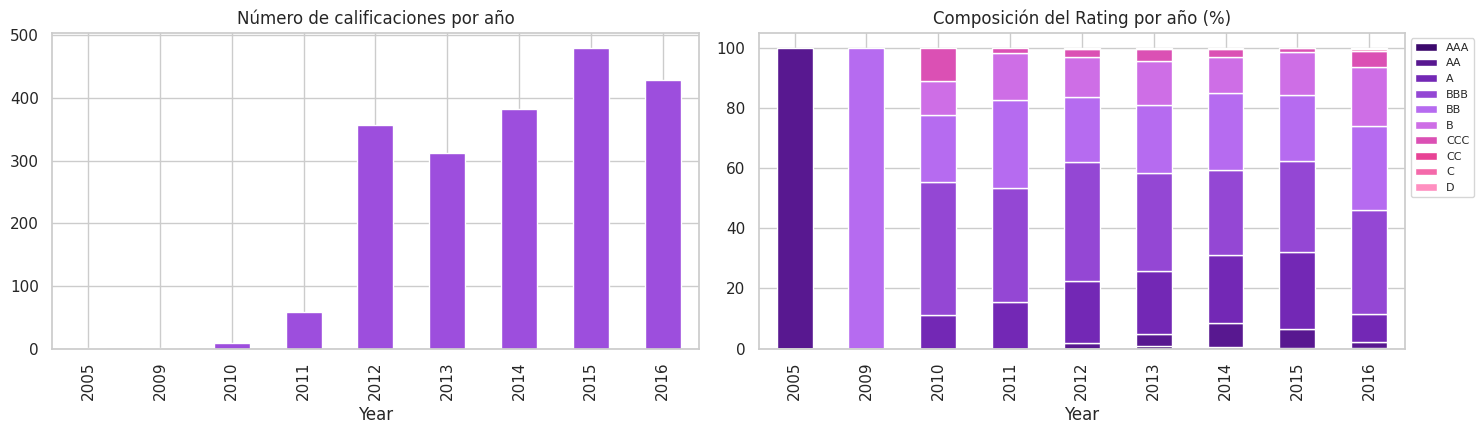

In [12]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Year"] = df["Date"].dt.year
print("Rango de fechas:", df["Date"].min().date(), "→", df["Date"].max().date())

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
df["Year"].value_counts().sort_index().plot.bar(ax=ax[0], color=LILA)
ax[0].set_title("Número de calificaciones por año")
(pd.crosstab(df["Year"], df["Rating"], normalize="index") * 100).plot.bar(
    stacked=True, ax=ax[1], colormap=CMAP_MR, legend=True)
ax[1].set_title("Composición del Rating por año (%)"); ax[1].legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.show()

**Análisis preliminar de `Date`:**
- Variable **temporal** (escala de intervalo) que va desde el **16‑08‑2005** hasta el **23‑12‑2016** (904 fechas distintas). Como se ve en el gráfico, el grueso de las calificaciones se ubica entre 2010 y 2016 y los años anteriores aportan muy pocos registros.
- No se usará directamente como predictor (el modelo debe generalizar a fechas futuras), pero se puede derivar `Year` para revisar si la distribución del riesgo cambia en el tiempo o para hacer una validación temporal.

### 3.5 Variables numéricas: estadística descriptiva, rango, escala y atípicos

In [13]:
num_cols = df.select_dtypes(include="number").columns.drop("Year").tolist()
print(f"{len(num_cols)} variables numéricas:\n", num_cols)
df[num_cols].describe().T

25 variables numéricas:
 ['currentRatio', 'quickRatio', 'cashRatio', 'daysOfSalesOutstanding', 'netProfitMargin', 'pretaxProfitMargin', 'grossProfitMargin', 'operatingProfitMargin', 'returnOnAssets', 'returnOnCapitalEmployed', 'returnOnEquity', 'assetTurnover', 'fixedAssetTurnover', 'debtEquityRatio', 'debtRatio', 'effectiveTaxRate', 'freeCashFlowOperatingCashFlowRatio', 'freeCashFlowPerShare', 'cashPerShare', 'companyEquityMultiplier', 'ebitPerRevenue', 'enterpriseValueMultiple', 'operatingCashFlowPerShare', 'operatingCashFlowSalesRatio', 'payablesTurnover']


,count,mean,std,min,25%,50%,75%,max
currentRatio,"2,029.0000",3.5296,44.0524,-0.9320,1.0719,1.4933,2.1669,"1,725.5050"
quickRatio,"2,029.0000",2.6540,32.9448,-1.8933,0.6028,0.9857,1.4538,"1,139.5417"
cashRatio,"2,029.0000",0.6674,3.5839,-0.1927,0.1306,0.2975,0.6249,125.9174
daysOfSalesOutstanding,"2,029.0000",333.7956,"4,447.8396",-811.8456,22.9051,42.3741,59.3236,"115,961.6374"
netProfitMargin,"2,029.0000",0.2784,6.0641,-101.8458,0.0210,0.0648,0.1148,198.5179
pretaxProfitMargin,"2,029.0000",0.4315,8.9850,-124.3436,0.0256,0.0850,0.1448,309.6949
grossProfitMargin,"2,029.0000",0.4980,0.5253,-14.8008,0.2331,0.4148,0.8497,2.7025
operatingProfitMargin,"2,029.0000",0.5873,11.2246,-124.3436,0.0446,0.1079,0.1762,410.1822
returnOnAssets,"2,029.0000",-37.5179,"1,166.1722","-40,213.1783",0.0192,0.0456,0.0775,0.4878
returnOnCapitalEmployed,"2,029.0000",-73.9742,"2,350.2757","-87,162.1622",0.0281,0.0744,0.1350,2.4395


In [14]:
# Tabla ampliada: rango, asimetría, curtosis, % de ceros/negativos y % de atípicos (regla IQR)
def resumen_numerico(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    atip = ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).mean() * 100
    return pd.Series({
        "min": s.min(), "mediana": s.median(), "media": s.mean(), "max": s.max(),
        "rango": s.max() - s.min(), "IQR": iqr, "desv_std": s.std(),
        "asimetria": s.skew(), "curtosis": s.kurt(),
        "%_negativos": (s < 0).mean() * 100, "%_ceros": (s == 0).mean() * 100,
        "%_atipicos_IQR": atip,
    })

tabla_num = df[num_cols].apply(resumen_numerico).T.sort_values("asimetria", key=abs, ascending=False)
tabla_num

,min,mediana,media,max,rango,IQR,desv_std,asimetria,curtosis,%_negativos,%_ceros,%_atipicos_IQR
currentRatio,-0.9320,1.4933,3.5296,"1,725.5050","1,726.4370",1.0950,44.0524,34.3389,"1,254.6962",0.2464,0.0000,6.5057
cashPerShare,-19.1503,3.6865,"4,227.5486","4,786,803.3780","4,786,822.5283",6.5201,"122,399.9519",34.0259,"1,239.5713",0.6900,0.0000,10.1035
freeCashFlowPerShare,"-4,912.7423",2.1317,"5,094.7186","5,753,379.8110","5,758,292.5533",3.8183,"146,915.6167",33.6772,"1,227.8642",18.3834,0.0000,9.9556
returnOnCapitalEmployed,"-87,162.1622",0.0744,-73.9742,2.4395,"87,164.6017",0.1069,"2,350.2757",-33.3185,"1,139.1826",14.4899,0.0000,7.5407
effectiveTaxRate,-100.6110,0.3005,0.3976,429.9263,530.5373,0.2238,10.5951,32.3087,"1,344.5727",12.5678,1.4293,12.0256
returnOnAssets,"-40,213.1783",0.0456,-37.5179,0.4878,"40,213.6661",0.0583,"1,166.1722",-32.1126,"1,039.1908",15.4756,0.0000,8.2307
returnOnEquity,-63.8148,0.1224,143.4943,"141,350.2110","141,414.0258",0.1514,"4,406.5150",31.7025,"1,006.5564",16.8063,0.0000,15.5249
quickRatio,-1.8933,0.9857,2.6540,"1,139.5417","1,141.4350",0.8510,32.9448,30.9256,991.7292,0.4436,0.0000,8.2799
operatingCashFlowPerShare,"-11,950.4908",4.3526,"6,515.1227","6,439,270.4130","6,451,220.9038",4.9630,"177,529.0146",30.3529,986.8193,3.3021,0.0000,8.3292
cashRatio,-0.1927,0.2975,0.6674,125.9174,126.1102,0.4943,3.5839,27.0988,854.1737,0.1971,0.2464,6.9492


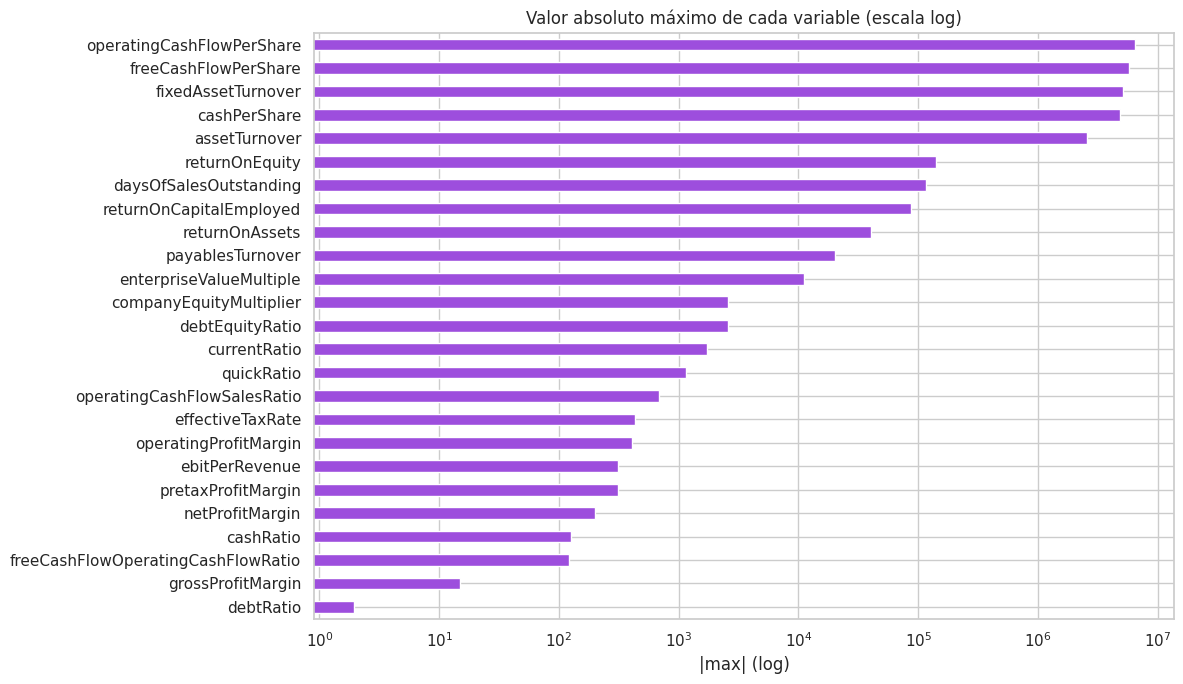

In [15]:
# Escala y orden de magnitud de cada variable (comparación de rangos en escala logarítmica)
mag = df[num_cols].abs().max().sort_values()
plt.figure(figsize=(12, 7))
mag.plot.barh(logx=True, color=LILA)
plt.title("Valor absoluto máximo de cada variable (escala log)")
plt.xlabel("|max| (log)"); plt.tight_layout(); plt.show()

**Análisis preliminar general de las variables numéricas:**
- **Tipo:** las 25 son **cuantitativas continuas**; en su mayoría son **razones financieras** (escala de **razón**, con cero significativo), salvo los indicadores "por acción" (valores monetarios por acción) y `daysOfSalesOutstanding` (días).
- **Escalas muy diferentes:** `debtRatio` va de 0 a 1,93, mientras que `fixedAssetTurnover` llega a **5,16 millones**, `operatingCashFlowPerShare` a **6,44 millones** y `daysOfSalesOutstanding` a **115.962 días**. Las desviaciones estándar van de 0,21 (`debtRatio`) a 188.997 (`fixedAssetTurnover`). Esto obliga a **estandarizar/escalar** antes de usar modelos sensibles a la escala (regresión logística, KNN, SVM, redes neuronales).
- **Asimetría y curtosis extremas:** casi todas las variables tienen |asimetría| > 13 (p. ej. `currentRatio` 34,3; `returnOnCapitalEmployed` −33,3); solo `debtRatio` (1,29) y `debtEquityRatio` (0,27, simétrica pero de colas enormes) son moderadas. Media y mediana difieren muchísimo (p. ej. `assetTurnover`: media 3.678 vs. mediana 0,70) → la **mediana** y el **IQR** describen mejor el valor típico que la media y la desviación estándar.
- **Valores negativos:** entre el 10 % y el 18 % de las empresas tienen márgenes, rentabilidades (ROA 15,5 %, ROE 16,8 %) o flujo libre por acción (18,4 %) negativos, y el 4,8 % tiene `debtEquityRatio` negativo (empresas con pérdidas o patrimonio negativo), lo cual es financieramente válido y **no** debe eliminarse automáticamente.
- **Atípicos:** según la regla IQR entre el 0,4 % (`grossProfitMargin`) y el 15,5 % (`returnOnEquity`) de los registros son atípicos; algunos valores extremos son probablemente errores de cálculo (p. ej. denominadores cercanos a cero). Opciones de tratamiento: *winsorizar* (recortar en percentiles 1‑99), transformaciones (log / Yeo‑Johnson) o usar modelos robustos (árboles, *Random Forest*, *Gradient Boosting*).

### 3.6 Análisis individual de cada indicador financiero

In [16]:
# Histograma (recortado entre p1 y p99 para que sea legible) y boxplot completo por variable
grupos = {
    "Liquidez": ["currentRatio", "quickRatio", "cashRatio", "daysOfSalesOutstanding"],
    "Rentabilidad": ["netProfitMargin", "pretaxProfitMargin", "grossProfitMargin",
                     "operatingProfitMargin", "returnOnAssets", "returnOnCapitalEmployed",
                     "returnOnEquity", "ebitPerRevenue"],
    "Eficiencia": ["assetTurnover", "fixedAssetTurnover", "payablesTurnover"],
    "Endeudamiento": ["debtEquityRatio", "debtRatio", "companyEquityMultiplier"],
    "Flujo de caja": ["freeCashFlowOperatingCashFlowRatio", "freeCashFlowPerShare",
                      "cashPerShare", "operatingCashFlowPerShare", "operatingCashFlowSalesRatio"],
    "Otros": ["effectiveTaxRate", "enterpriseValueMultiple"],
}

def graficar_grupo(nombre, cols):
    cols = [c for c in cols if c in df.columns]
    fig, axes = plt.subplots(len(cols), 2, figsize=(14, 2.8 * len(cols)))
    axes = np.atleast_2d(axes)
    for i, c in enumerate(cols):
        s = df[c]; lo, hi = s.quantile([0.01, 0.99])
        sns.histplot(s.clip(lo, hi), kde=True, ax=axes[i, 0], color=MORADO)
        axes[i, 0].set_title(f"{c} – histograma (p1–p99)  | asim={s.skew():.1f}")
        sns.boxplot(x=s, ax=axes[i, 1], color=ROSADO, fliersize=2)
        axes[i, 1].set_title(f"{c} – boxplot (datos completos)")
    fig.suptitle(f"Indicadores de {nombre}", fontsize=14, y=1.0)
    plt.tight_layout(); plt.show()
    display(tabla_num.loc[cols, ["min", "mediana", "media", "max", "IQR",
                                 "asimetria", "%_negativos", "%_atipicos_IQR"]])

#### 3.6.1 Liquidez

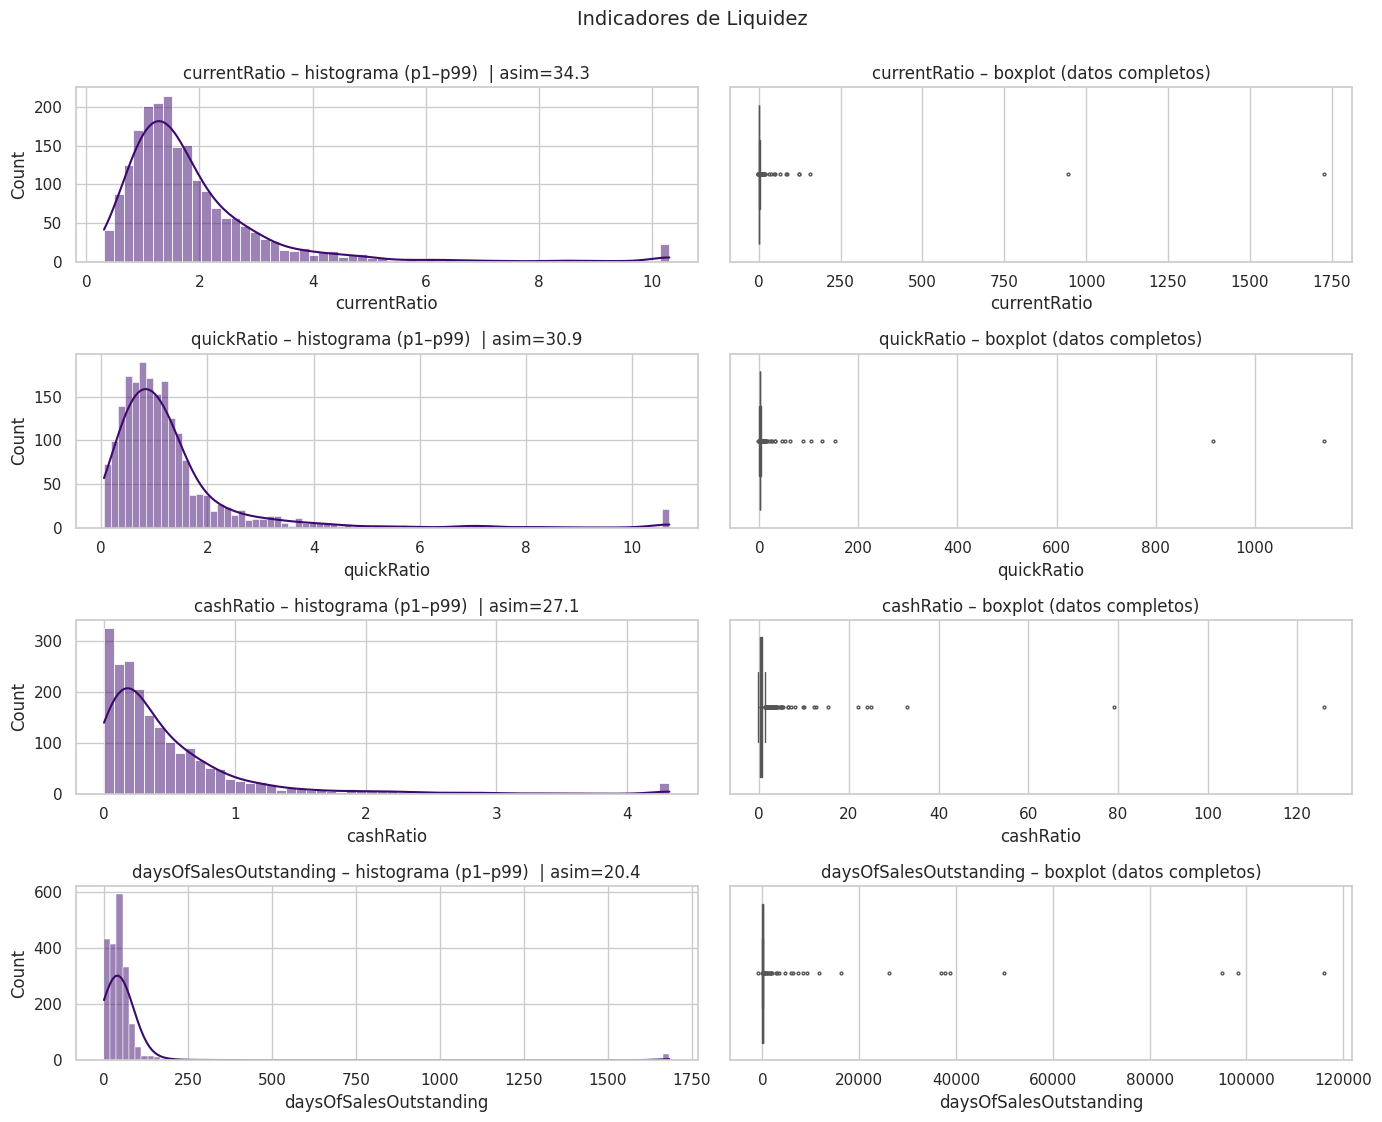

,min,mediana,media,max,IQR,asimetria,%_negativos,%_atipicos_IQR
currentRatio,-0.9320,1.4933,3.5296,"1,725.5050",1.0950,34.3389,0.2464,6.5057
quickRatio,-1.8933,0.9857,2.6540,"1,139.5417",0.8510,30.9256,0.4436,8.2799
cashRatio,-0.1927,0.2975,0.6674,125.9174,0.4943,27.0988,0.1971,6.9492
daysOfSalesOutstanding,-811.8456,42.3741,333.7956,"115,961.6374",36.4185,20.3996,0.0986,4.2878


In [17]:
graficar_grupo("Liquidez", grupos["Liquidez"])

**Indicadores de liquidez** (capacidad de pagar obligaciones de corto plazo):
- `currentRatio`, `quickRatio`, `cashRatio`: razones ≥ 0, escala de razón. Medianas de **1,49**, **0,99** y **0,30** respectivamente, decrecientes como es esperable (cada uno es más estricto que el anterior). Distribución **muy asimétrica a la derecha** (asimetría 27–34) con máximos de 1.725, 1.140 y 126; entre 6,5 % y 8,3 % de atípicos.
- `daysOfSalesOutstanding`: medido en **días**; mediana de **42 días** de cobro, pero con un máximo de **115.962 días** y un mínimo de **−812** (valor imposible), lo que evidencia errores de cálculo en algunos registros.
- Las tres razones de liquidez están relacionadas entre sí (ver matriz de correlación), aunque ninguna supera |rho| = 0,8.

#### 3.6.2 Rentabilidad

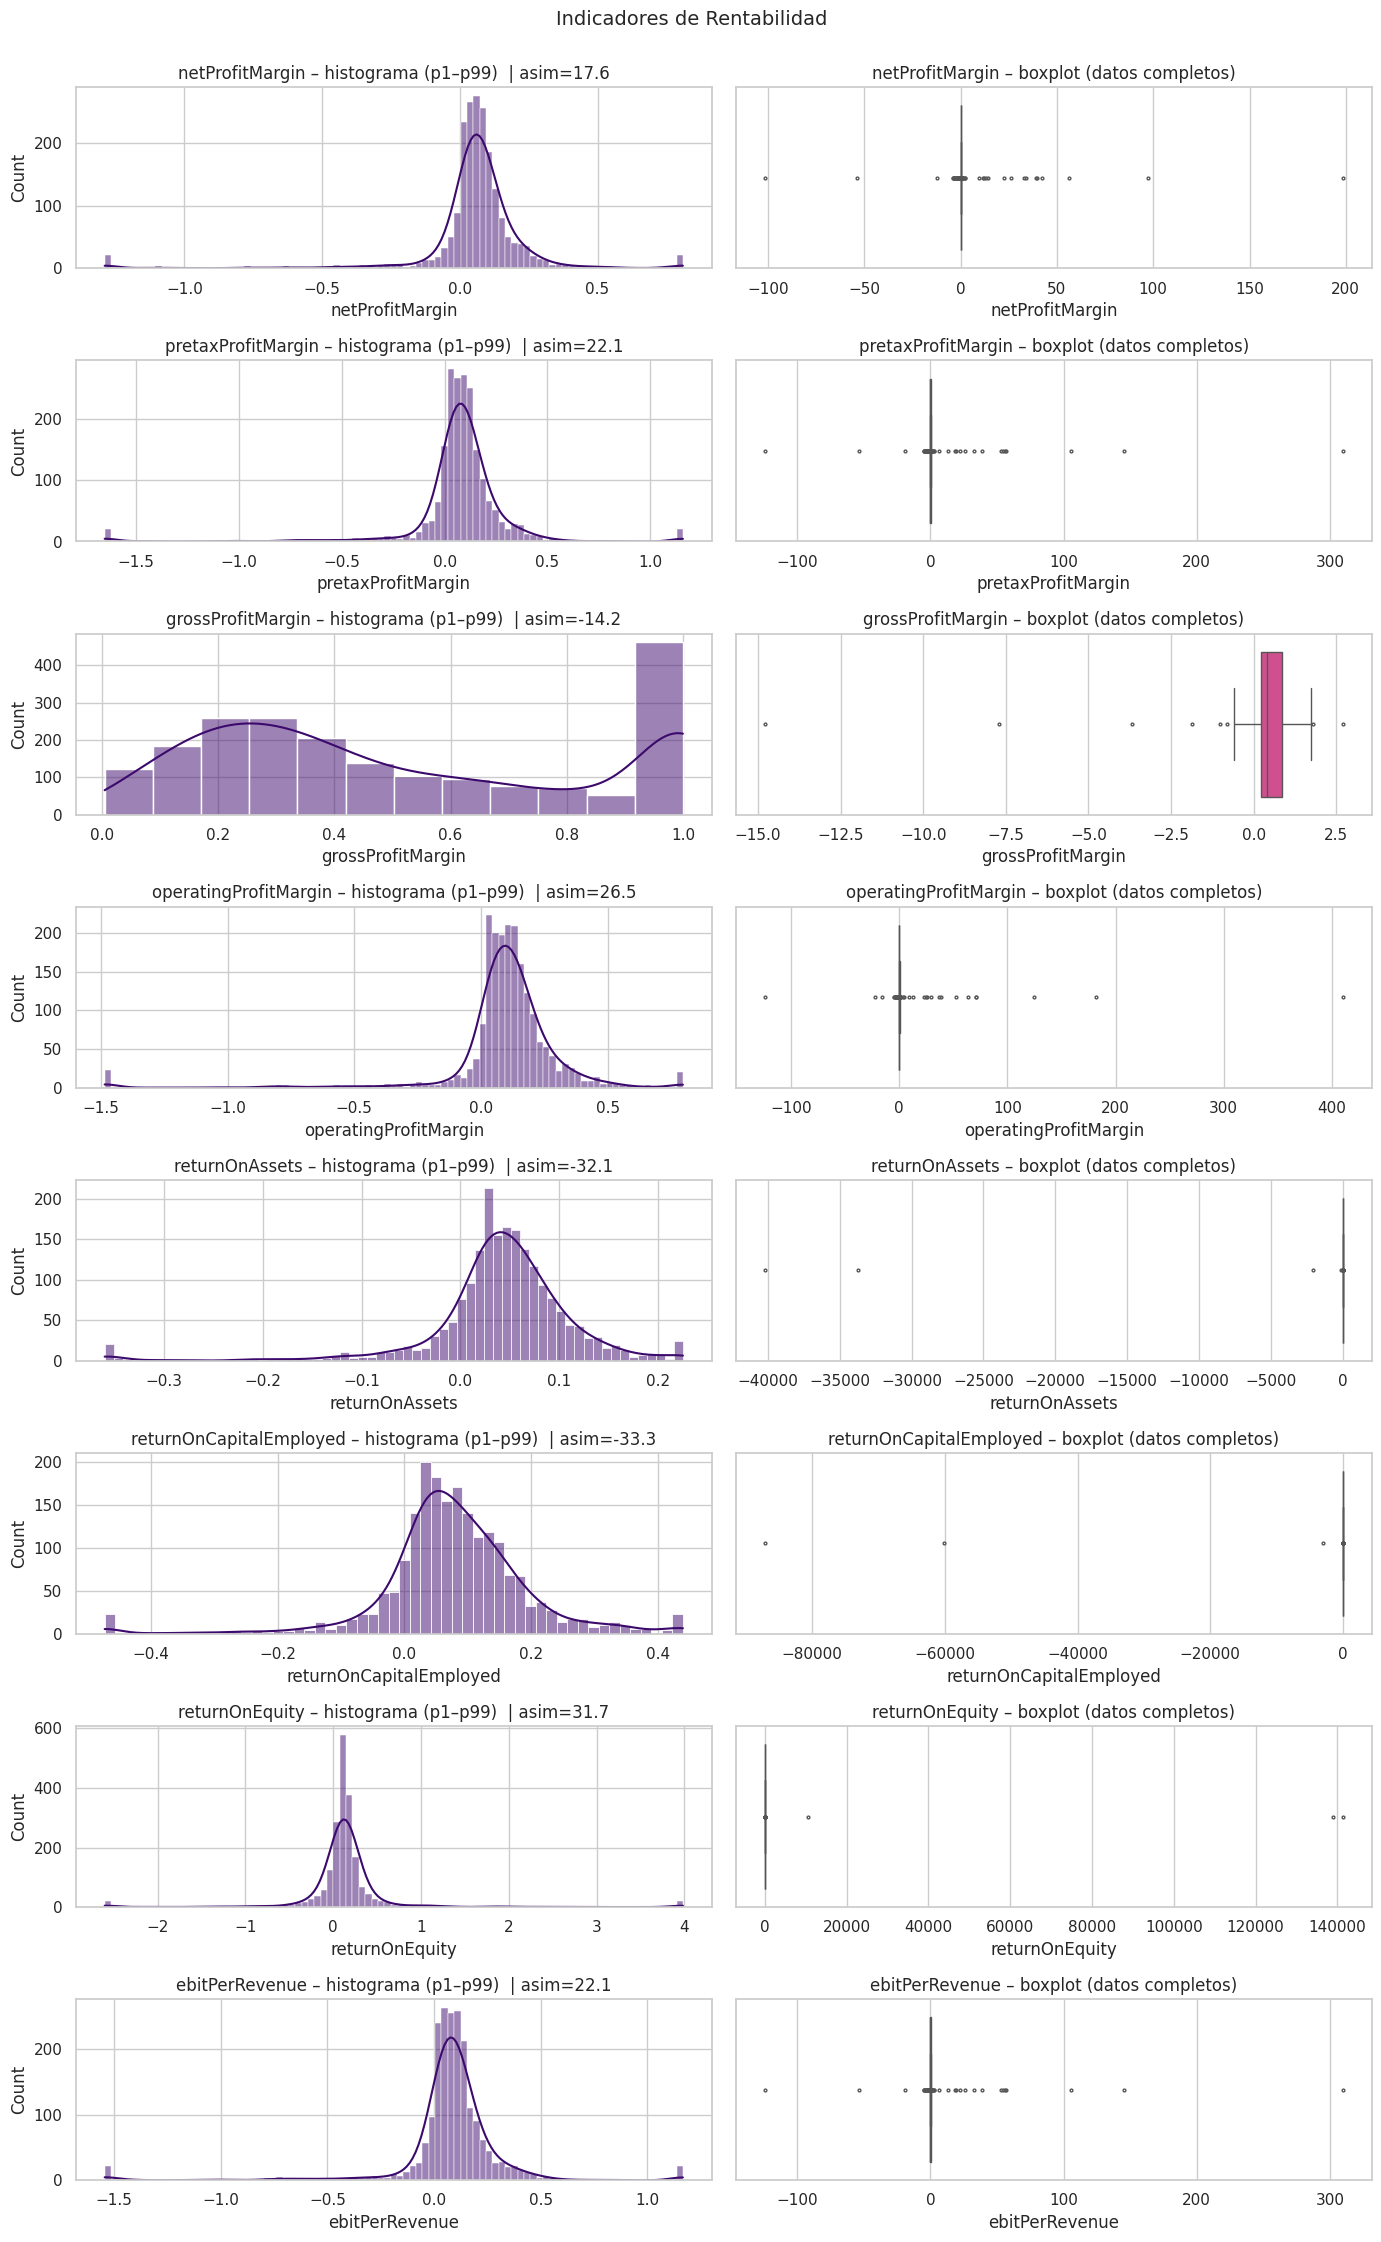

,min,mediana,media,max,IQR,asimetria,%_negativos,%_atipicos_IQR
netProfitMargin,-101.8458,0.0648,0.2784,198.5179,0.0938,17.6199,15.4263,11.4342
pretaxProfitMargin,-124.3436,0.0850,0.4315,309.6949,0.1191,22.0963,14.9335,11.6313
grossProfitMargin,-14.8008,0.4148,0.4980,2.7025,0.6166,-14.2034,0.9857,0.3943
operatingProfitMargin,-124.3436,0.1079,0.5873,410.1822,0.1316,26.4939,10.2514,9.2656
returnOnAssets,"-40,213.1783",0.0456,-37.5179,0.4878,0.0583,-32.1126,15.4756,8.2307
returnOnCapitalEmployed,"-87,162.1622",0.0744,-73.9742,2.4395,0.1069,-33.3185,14.4899,7.5407
returnOnEquity,-63.8148,0.1224,143.4943,"141,350.2110",0.1514,31.7025,16.8063,15.5249
ebitPerRevenue,-124.3436,0.0873,0.4375,309.6949,0.1213,22.0995,14.4406,11.0892


In [18]:
graficar_grupo("Rentabilidad", grupos["Rentabilidad"])

**Indicadores de rentabilidad** (capacidad de generar utilidades):
- Márgenes (`netProfitMargin`, `pretaxProfitMargin`, `grossProfitMargin`, `operatingProfitMargin`, `ebitPerRevenue`): proporciones respecto a las ventas; su rango "natural" es aproximadamente [−1, 1], pero aparecen valores fuera de ese intervalo por empresas con ventas muy bajas.
- Medianas: margen bruto **41,5 %**, operativo **10,8 %**, antes de impuestos **8,5 %** y neto **6,5 %**. `grossProfitMargin` es el más estable (solo 0,4 % de atípicos); los demás márgenes son negativos en 10–15 % de los casos.
- `returnOnAssets`, `returnOnCapitalEmployed`, `returnOnEquity`: medianas de **4,6 %**, **7,4 %** y **12,2 %**. Presentan valores imposibles (ROA mínimo −40.213; ROCE −87.162; ROE máximo 141.350) por denominadores cercanos a cero. **ROE** es el más volátil (15,5 % de atípicos).
- `ebitPerRevenue` es prácticamente igual a `pretaxProfitMargin` (**rho = 0,98**) → alta redundancia, que se tratará en la etapa de **selección de características**.

#### 3.6.3 Eficiencia

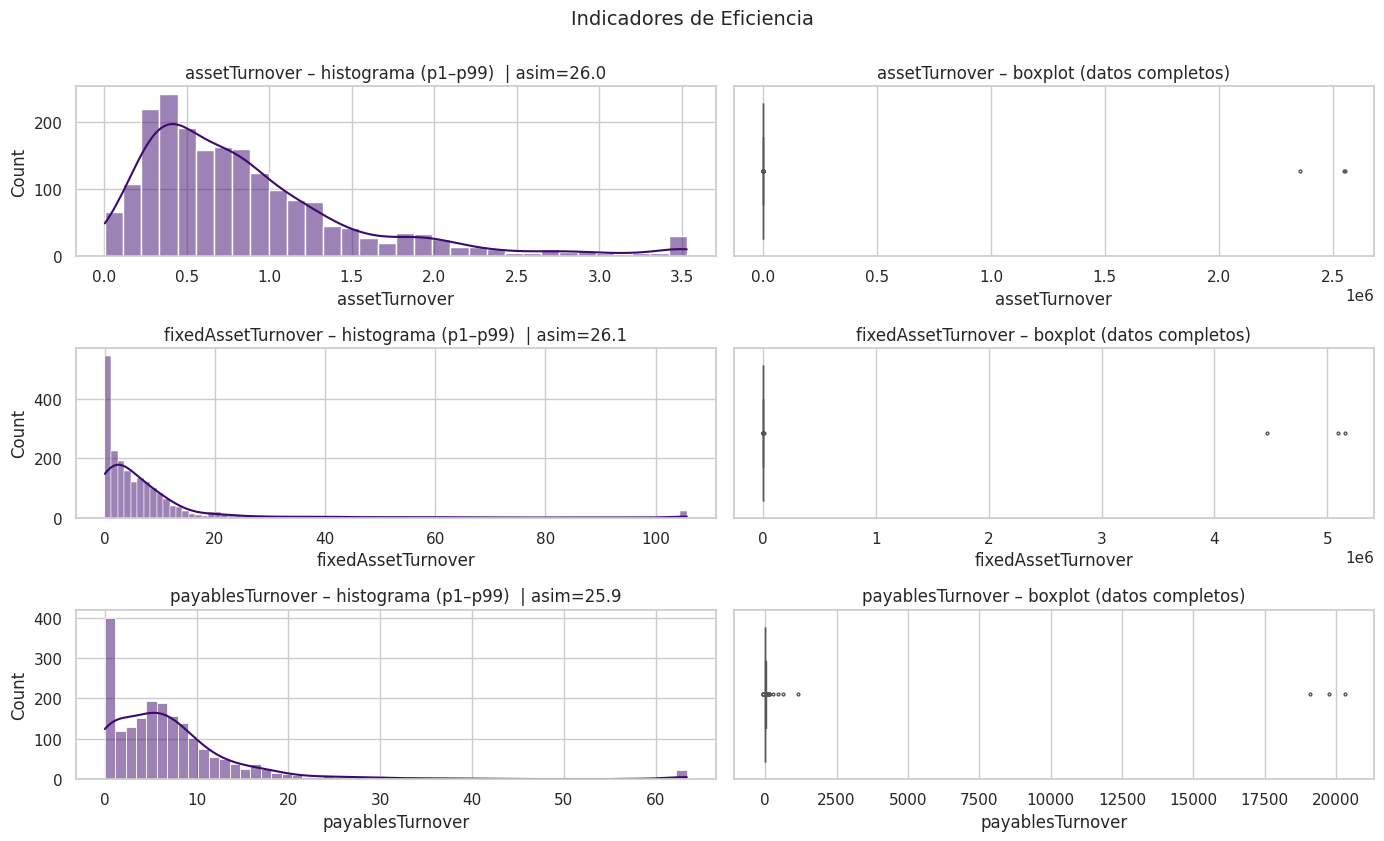

,min,mediana,media,max,IQR,asimetria,%_negativos,%_atipicos_IQR
assetTurnover,-9.1575,0.6983,"3,678.3397","2,553,148.6150",0.7090,26.0203,0.1479,5.3228
fixedAssetTurnover,-26.7978,3.8117,"7,269.4874","5,156,883.6710",7.4986,26.1205,0.1479,7.5899
payablesTurnover,-76.6629,5.7597,38.0027,"20,314.8804",7.2750,25.9196,0.7393,5.7664


In [19]:
graficar_grupo("Eficiencia", grupos["Eficiencia"])

**Indicadores de eficiencia / rotación** (cuántas ventas genera cada unidad de activo o cuántas veces se pagan proveedores):
- Medianas: `assetTurnover` **0,70**, `fixedAssetTurnover` **3,81**, `payablesTurnover` **5,76**.
- Las tres tienen asimetría ≈ 26 y máximos absurdos (2,55 y 5,16 millones para las rotaciones de activos); empresas con pocos activos fijos (servicios, tecnología) o pocas cuentas por pagar generan valores muy grandes. Se recomienda transformación logarítmica.

#### 3.6.4 Endeudamiento

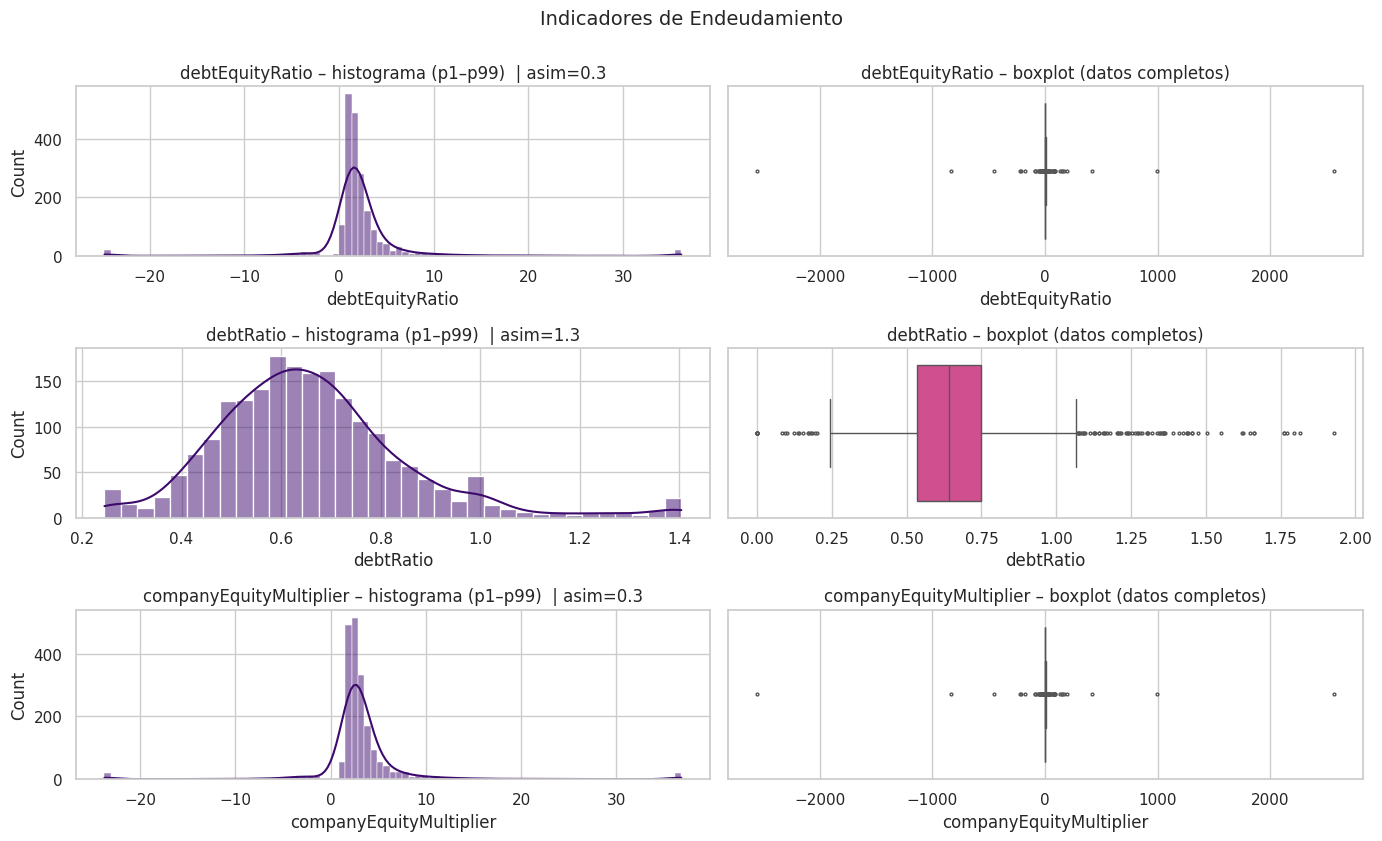

,min,mediana,media,max,IQR,asimetria,%_negativos,%_atipicos_IQR
debtEquityRatio,"-2,556.4196",1.6525,2.3283,"2,561.8718",1.5904,0.2690,4.8300,13.9478
debtRatio,0.0000,0.6409,0.6615,1.9278,0.2143,1.2853,0.0000,4.3371
companyEquityMultiplier,"-2,555.4196",2.6525,3.3236,"2,562.8718",1.6115,0.2691,4.8793,13.6520


In [20]:
graficar_grupo("Endeudamiento", grupos["Endeudamiento"])

**Indicadores de endeudamiento / apalancamiento** (se espera que sean de los más importantes para el rating):
- `debtRatio`: la variable **mejor comportada** de la base: rango [0; 1,93], mediana **0,64**, asimetría 1,29 y solo 4,3 % de atípicos.
- `debtEquityRatio` (mediana 1,65) y `companyEquityMultiplier` (mediana 2,65): rango ±2.560, ≈ 4,8 % negativos (patrimonio negativo) y ≈ 14 % de atípicos. Además `companyEquityMultiplier` = 1 + `debtEquityRatio` (**rho = 0,99**) → alta redundancia, que se tratará en la etapa de **selección de características**.
- Teóricamente, **a mayor endeudamiento, peor calificación** (se verifica en la sección 3.7).

#### 3.6.5 Flujo de caja

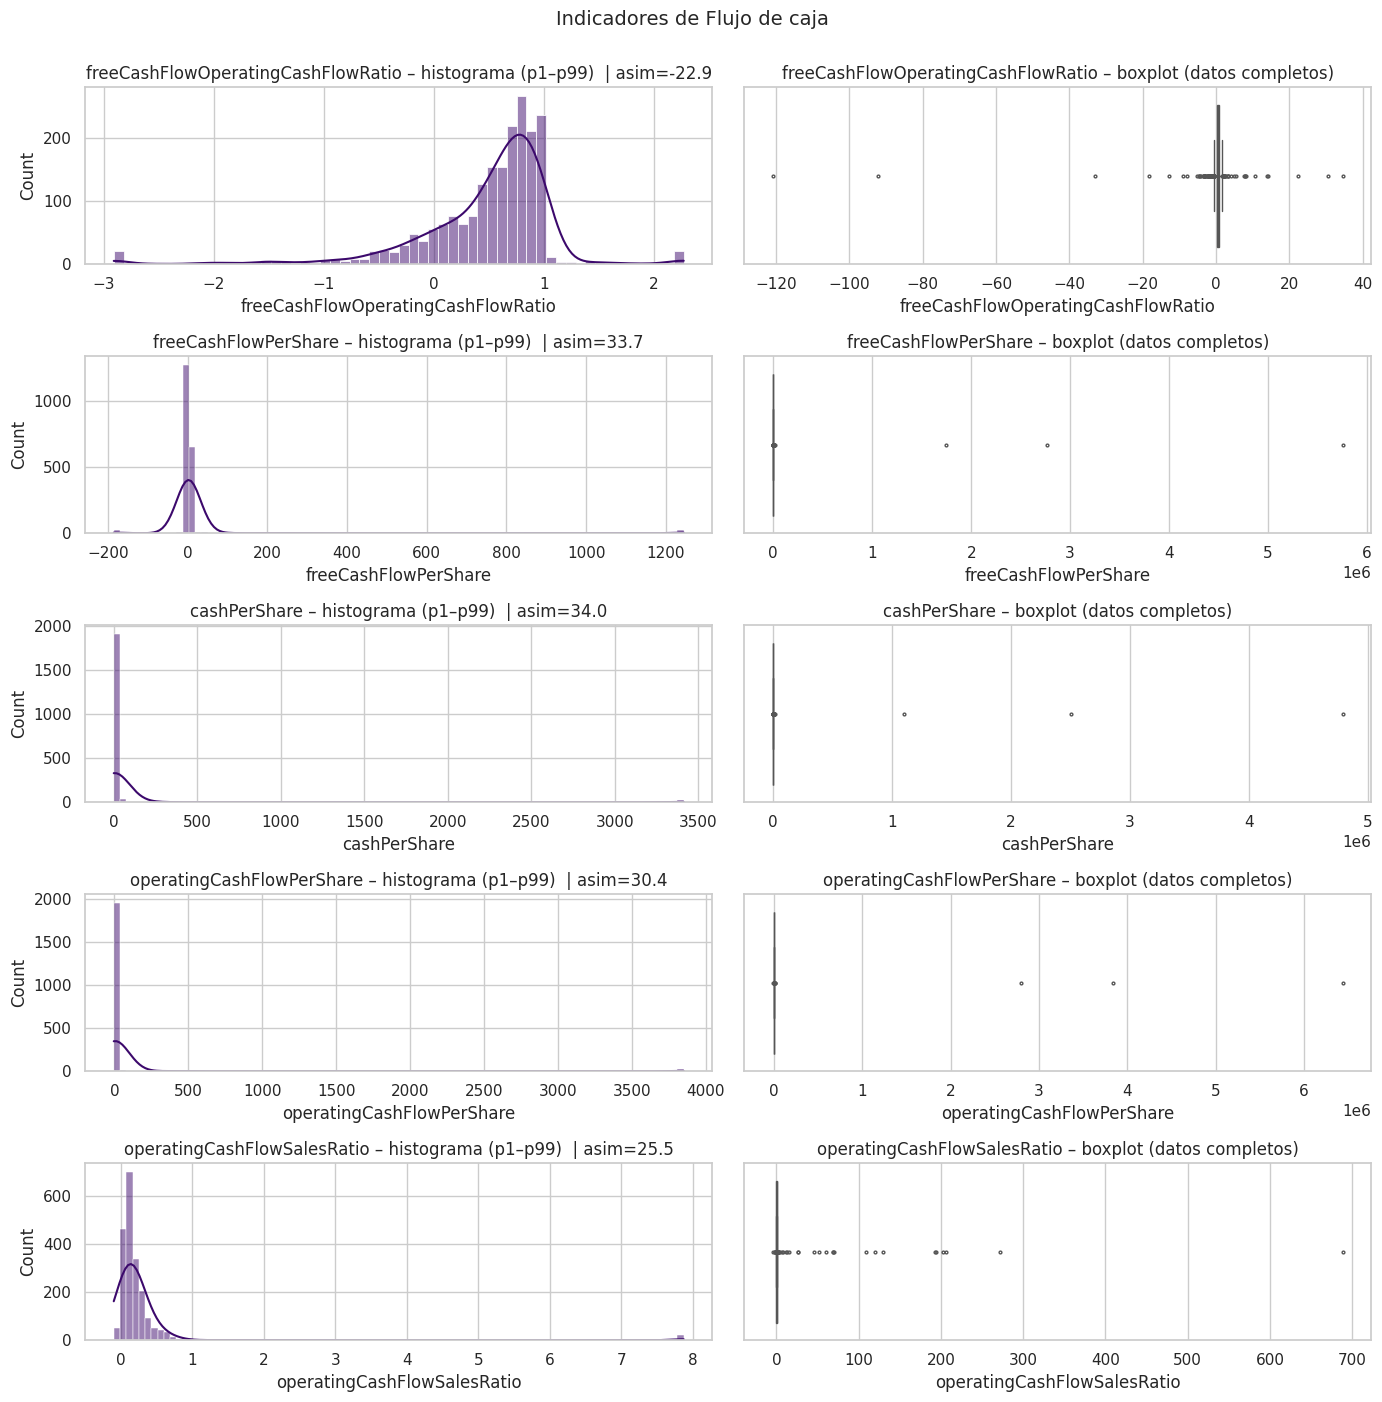

,min,mediana,media,max,IQR,asimetria,%_negativos,%_atipicos_IQR
freeCashFlowOperatingCashFlowRatio,-120.9160,0.6445,0.4095,34.5941,0.5655,-22.9131,15.2785,6.2592
freeCashFlowPerShare,"-4,912.7423",2.1317,"5,094.7186","5,753,379.8110",3.8183,33.6772,18.3834,9.9556
cashPerShare,-19.1503,3.6865,"4,227.5486","4,786,803.3780",6.5201,34.0259,0.6900,10.1035
operatingCashFlowPerShare,"-11,950.4908",4.3526,"6,515.1227","6,439,270.4130",4.9630,30.3529,3.3021,8.3292
operatingCashFlowSalesRatio,-4.4618,0.1330,1.4477,688.5266,0.1670,25.4505,3.2528,7.6885


In [21]:
graficar_grupo("Flujo de caja", grupos["Flujo de caja"])

**Indicadores de flujo de caja:**
- `freeCashFlowOperatingCashFlowRatio` y `operatingCashFlowSalesRatio`: razones adimensionales; valores negativos indican flujo libre o operativo negativo.
- `freeCashFlowPerShare`, `cashPerShare`, `operatingCashFlowPerShare`: expresados en **dólares por acción**, dependen del número de acciones de cada empresa, por lo que son menos comparables. Medianas de 2,13, 3,69 y 4,35 USD/acción, pero con máximos de varios millones (asimetría > 30). El flujo libre por acción es negativo en el **18,4 %** de los casos.

#### 3.6.6 Otros

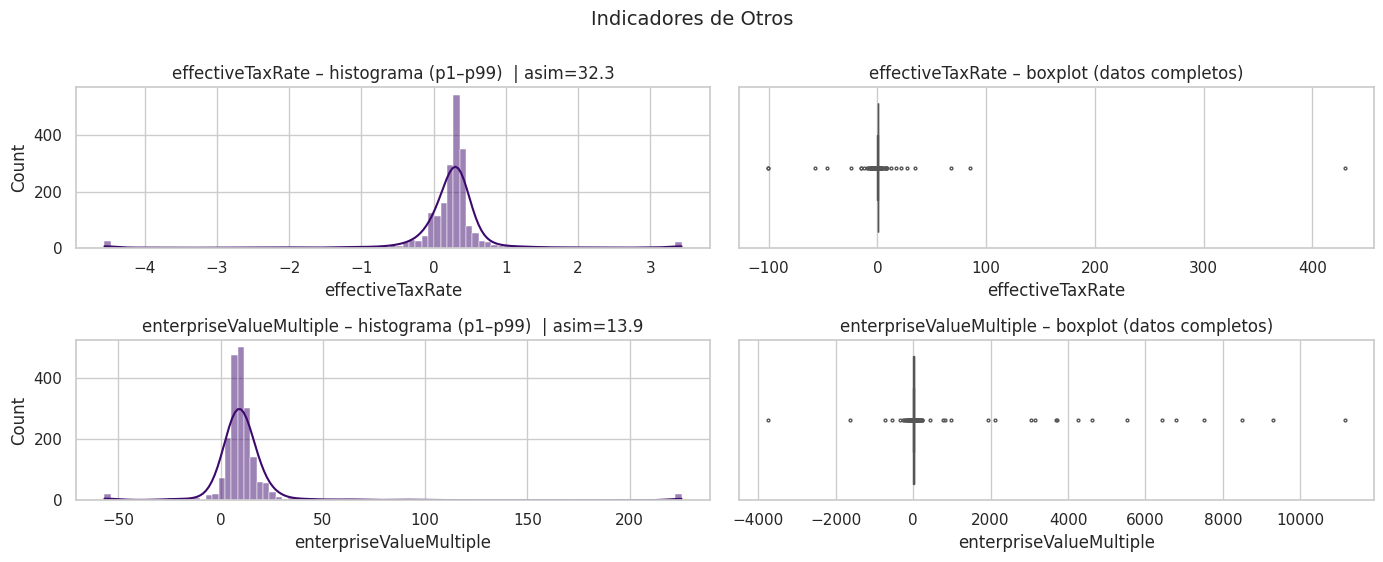

,min,mediana,media,max,IQR,asimetria,%_negativos,%_atipicos_IQR
effectiveTaxRate,-100.6110,0.3005,0.3976,429.9263,0.2238,32.3087,12.5678,12.0256
enterpriseValueMultiple,"-3,749.9213",9.2744,48.2880,"11,153.6071",6.6737,13.9480,5.4214,11.0399


In [22]:
graficar_grupo("Otros", grupos["Otros"])

**Otros indicadores:**
- `effectiveTaxRate`: tasa efectiva de impuestos; mediana **30 %** (coherente con la tasa corporativa de EE. UU. en el periodo), pero con rango [−100; 430] y 12,6 % de valores negativos.
- `enterpriseValueMultiple` (EV/EBITDA): múltiplo de valoración de mercado; mediana **9,27**, pero con rango [−3.750; 11.154] y 11 % de atípicos cuando el EBITDA es cercano a cero o negativo.

### 3.7 Relación entre variables

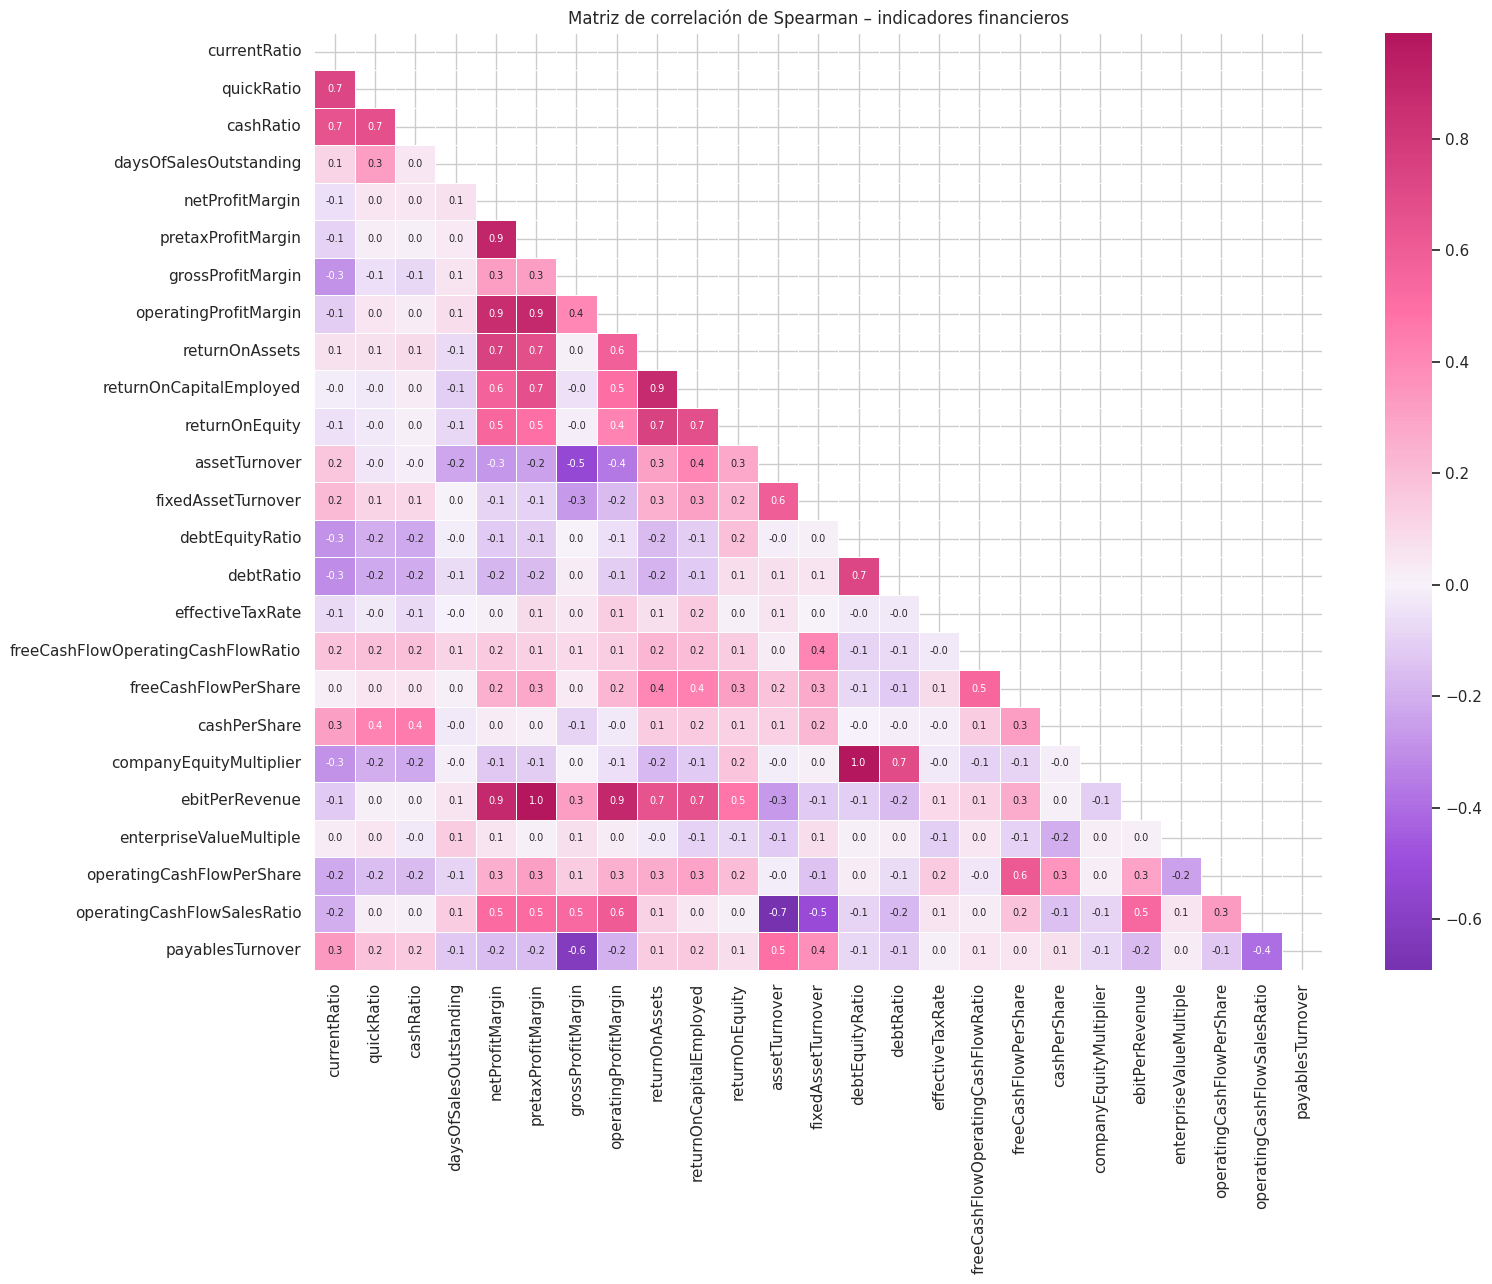

Pares de variables más correlacionadas (|rho| > 0.8):


,level_0,level_1,rho
239,debtEquityRatio,companyEquityMultiplier,0.9904
124,pretaxProfitMargin,ebitPerRevenue,0.9826
90,netProfitMargin,pretaxProfitMargin,0.8958
159,operatingProfitMargin,ebitPerRevenue,0.8892
111,pretaxProfitMargin,operatingProfitMargin,0.8850
105,netProfitMargin,ebitPerRevenue,0.8792
164,returnOnAssets,returnOnCapitalEmployed,0.8755
92,netProfitMargin,operatingProfitMargin,0.8650


In [23]:
# Matriz de correlación de Spearman (robusta a atípicos y relaciones monótonas no lineales)
corr = df[num_cols].corr(method="spearman")
plt.figure(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap=CMAP_MR_DIV, center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, linewidths=.5)
plt.title("Matriz de correlación de Spearman – indicadores financieros")
plt.tight_layout(); plt.show()

pares = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().rename("rho").reset_index())
pares = pares.reindex(pares["rho"].abs().sort_values(ascending=False).index)
print("Pares de variables más correlacionadas (|rho| > 0.8):")
pares[pares["rho"].abs() > 0.8]

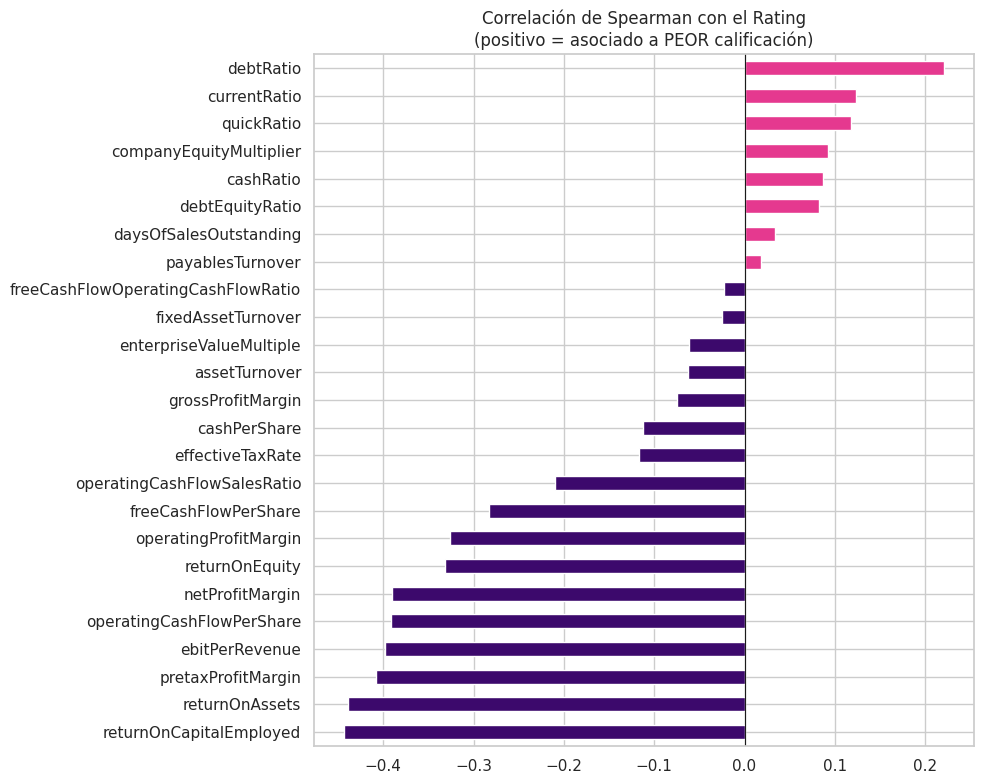

,rho_spearman_vs_rating
returnOnCapitalEmployed,-0.4431
returnOnAssets,-0.4388
pretaxProfitMargin,-0.4082
ebitPerRevenue,-0.3977
operatingCashFlowPerShare,-0.3916
netProfitMargin,-0.3905
returnOnEquity,-0.3322
operatingProfitMargin,-0.3256
freeCashFlowPerShare,-0.2829
operatingCashFlowSalesRatio,-0.2094


In [24]:
# Relación de cada indicador con la variable de salida (Rating codificado ordinalmente: AAA=0 ... D=9)
df["Rating_num"] = df["Rating"].cat.codes
rel = df[num_cols].corrwith(df["Rating_num"], method="spearman").sort_values()
plt.figure(figsize=(10, 8))
rel.plot.barh(color=np.where(rel > 0, ROSADO, MORADO))
plt.title("Correlación de Spearman con el Rating\n(positivo = asociado a PEOR calificación)")
plt.axvline(0, color="k", lw=.8); plt.tight_layout(); plt.show()
rel.to_frame("rho_spearman_vs_rating")

In [25]:
# Mediana de cada indicador por nivel de Rating (perfil financiero de cada calificación)
perfil = df.groupby("Rating", observed=True)[num_cols].median().T
perfil

Rating,AAA,AA,A,BBB,BB,B,CCC,CC,C,D
currentRatio,2.5013,1.4697,1.3388,1.4337,1.6744,1.6224,1.6803,1.3409,1.2861,0.5854
quickRatio,2.2952,0.9719,0.8490,0.9297,1.1403,1.0640,1.1654,0.5734,0.6359,0.3898
cashRatio,0.1900,0.3442,0.2461,0.2779,0.3744,0.2895,0.3652,0.3014,0.5786,0.0165
daysOfSalesOutstanding,78.1262,39.1939,39.9649,42.3735,43.8788,43.9803,41.7225,21.1141,3.6440,54.7382
netProfitMargin,0.1998,0.1082,0.0940,0.0730,0.0461,0.0177,-0.0333,-0.2325,0.4499,0.1803
pretaxProfitMargin,0.0821,0.1512,0.1233,0.0926,0.0578,0.0238,-0.0437,-0.0953,0.7228,0.1299
grossProfitMargin,0.6898,0.5887,0.4887,0.3850,0.3481,0.4129,0.7638,0.9185,0.5159,1.0000
operatingProfitMargin,0.2952,0.1487,0.1410,0.1190,0.0789,0.0591,0.0181,-0.0913,0.0991,-0.1978
returnOnAssets,0.1042,0.0927,0.0669,0.0489,0.0330,0.0162,-0.0152,-0.3307,0.0673,0.0439
returnOnCapitalEmployed,0.0583,0.1732,0.1319,0.0820,0.0528,0.0291,-0.0105,-0.6122,0.3954,0.0357


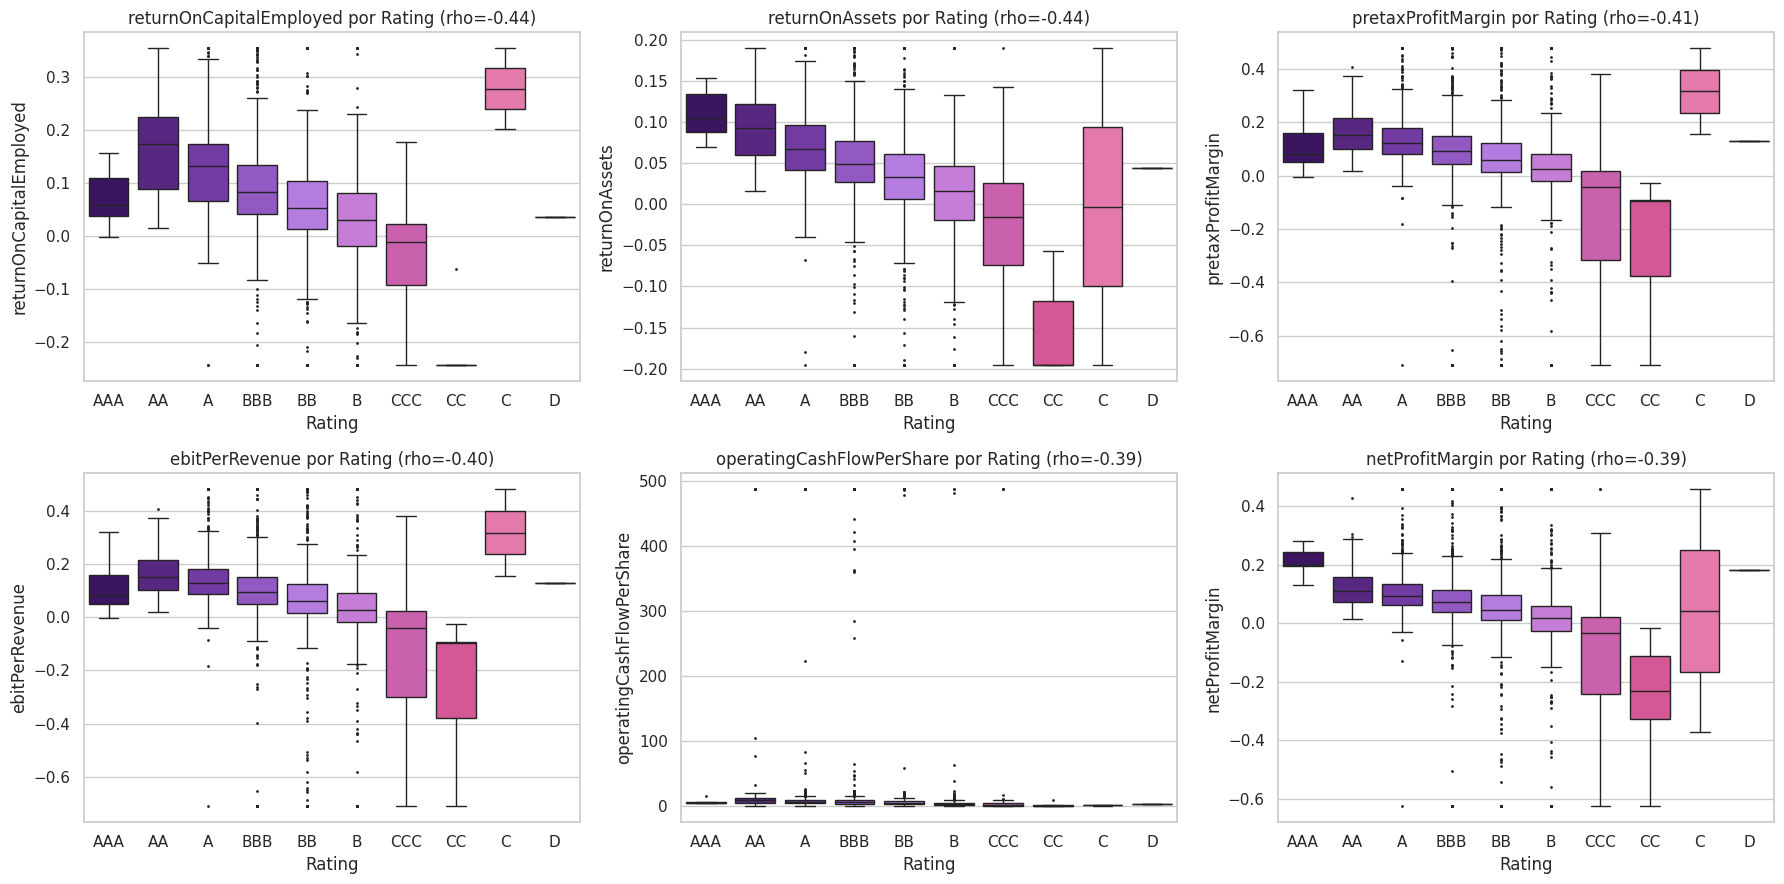

In [26]:
# Boxplots por Rating de los indicadores más asociados con la calificación
top = rel.abs().sort_values(ascending=False).head(6).index
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for a, c in zip(axes.ravel(), top):
    lo, hi = df[c].quantile([0.02, 0.98])
    sns.boxplot(data=df.assign(**{c: df[c].clip(lo, hi)}), x="Rating", y=c,
                order=orden_rating, ax=a, palette=paleta(10), fliersize=1)
    a.set_title(f"{c} por Rating (rho={rel[c]:.2f})")
plt.tight_layout(); plt.show()

**Análisis preliminar de relaciones:**
- **Multicolinealidad:** 8 pares superan |rho| > 0,8:
  - `debtEquityRatio` – `companyEquityMultiplier` (**0,990**)
  - `pretaxProfitMargin` – `ebitPerRevenue` (**0,983**)
  - `netProfitMargin` – `pretaxProfitMargin` (0,896), `operatingProfitMargin` – `ebitPerRevenue` (0,889), `pretaxProfitMargin` – `operatingProfitMargin` (0,885), `netProfitMargin` – `ebitPerRevenue` (0,879), `netProfitMargin` – `operatingProfitMargin` (0,865)
  - `returnOnAssets` – `returnOnCapitalEmployed` (0,876)

  Los dos primeros pares (|rho| > 0,95) son prácticamente la misma variable. **No se eliminan aquí**: la decisión de qué variables conservar se toma en la etapa de **selección de características** (SFS / SBS / SFFS), que evalúa su aporte real al modelo.
- **Relación con el Rating:** las correlaciones son **débiles a moderadas**; la más fuerte es `returnOnCapitalEmployed` (**−0,44**), seguida de `returnOnAssets` (−0,44), `pretaxProfitMargin` (−0,41), `ebitPerRevenue` (−0,40), `operatingCashFlowPerShare` (−0,39) y `netProfitMargin` (−0,39). Ninguna variable por sí sola separa las 10 clases.
- La **rentabilidad** se asocia a **mejores** calificaciones (signo negativo), mientras que `debtRatio` es la variable con mayor correlación **positiva** (más deuda → peor rating), coherente con la teoría financiera. Llama la atención que la **liquidez** (`currentRatio` 0,12; `quickRatio` 0,12) también se asocia levemente a peores calificaciones: las empresas más riesgosas suelen mantener colchones de caja.
- Las medianas por rating muestran un gradiente claro, p. ej. ROA: AA 9,3 % → A 6,7 % → BBB 4,9 % → BB 3,3 %; `debtRatio`: AAA 0,48 → AA 0,58 → BBB 0,63 → BB 0,64.
- Las clases extremas (AAA, CC, C, D) tienen tan pocos casos que sus medianas son poco confiables.

## 4. Conclusiones preliminares del EDA

1. **Base de datos:** 2.029 registros y 31 variables sobre calificaciones crediticias de 593 empresas estadounidenses listadas (2005‑2016, mayoritariamente 2010‑2016), emitidas por 5 agencias; sin valores faltantes ni duplicados, lo que facilita el preprocesamiento.
2. **Tipo de problema:** clasificación supervisada **multiclase ordinal** (10 categorías de `Rating`), que también puede abordarse como clasificación binaria *grado de inversión vs. especulativo*.
3. **Variable de salida desbalanceada:** BBB, BB, A y B suman el 91,7 %; AAA, CC, C y D tienen 7, 5, 2 y 1 registros → agrupar clases y usar técnicas para desbalance y métricas adecuadas (F1‑macro, matriz de confusión, *balanced accuracy*).
4. **Predictores:** 25 razones financieras continuas (escala de razón) con **escalas muy distintas**, **asimetría extrema**, **valores negativos válidos** y **muchos atípicos** → aplicar winsorización o transformaciones (log / Yeo‑Johnson) y escalado robusto (`RobustScaler`), o preferir modelos basados en árboles.
5. **Variables categóricas:** `Sector` se conserva y se codifica con *one‑hot*. Se descartan `Name` y `Symbol` (identificadores; `Symbol` sirve para validación agrupada por empresa), `Date` (solo para análisis temporal) y `Rating Agency Name` (describe a quien califica, no a la empresa).
6. **Multicolinealidad** marcada: `companyEquityMultiplier` y `ebitPerRevenue` son casi redundantes (|rho| > 0,98); se conservan y su permanencia se decidirá en la **selección de características**.


## 5. Eliminación de variables descartadas, codificación y preprocesamiento

A partir del EDA se toman las siguientes decisiones:

| Variable | Decisión | Justificación |
|---|---|---|
| `Name`, `Symbol` | **Eliminar** | Identificadores de la empresa (593 valores únicos); no describen su situación financiera. |
| `Date` (y `Year` derivada) | **Eliminar** | Solo informa cuándo se emitió la calificación; el modelo debe generalizar a fechas futuras. |
| `Sector` | **Conservar y codificar (*one‑hot*)** | El EDA mostró que la composición del rating cambia según el sector (12 categorías). |
| `Rating Agency Name` | **Eliminar** | Describe quién emite la calificación, no una característica de la empresa; además DBRS tiene solo 3 registros. |
| `Rating` | **Separar** | Es la variable de salida: **no** se usa para entrenar los modelos no supervisados, solo para evaluarlos al final. |
| 25 indicadores financieros | **Conservar todos** | Aunque algunos pares están muy correlacionados (p. ej. `debtEquityRatio`–`companyEquityMultiplier`, `pretaxProfitMargin`–`ebitPerRevenue`), **no se elimina ninguna variable con base en la matriz de correlación**: esa decisión le corresponde a la etapa de **selección de características**. |

Entrada de los modelos: **25 indicadores financieros + 12 variables *dummy* de `Sector`** = **37 variables**.

In [27]:
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score, v_measure_score,
                             confusion_matrix)
from scipy.cluster.hierarchy import dendrogram, linkage, set_link_color_palette
from scipy.optimize import linear_sum_assignment
from scipy import stats

# 1) Variables descartadas: identificadoras, fecha y agencia calificadora
descartadas_info = ["Name", "Symbol", "Date", "Year", "Rating Agency Name", "Rating_num"]

# 2) NO se eliminan variables por correlación: se conservan los 25 indicadores financieros
#    (la multicolinealidad se tratará en la etapa de selección de características)
df_modelo = df.drop(columns=[c for c in descartadas_info if c in df.columns])
cat_features = ["Sector"]                                            # categórica a codificar
features = [c for c in df_modelo.columns if c not in cat_features + ["Rating"]]   # 25 numéricas

print(f"\nDimensión original : {df.shape}")
print(f"Dimensión depurada : {df_modelo.shape}")
print(f"  -> {len(features)} indicadores financieros + {len(cat_features)} categóricas + Rating")
print("\nVariables eliminadas:", [c for c in descartadas_info if c in df.columns and c != "Rating_num"])


Dimensión original : (2029, 33)
Dimensión depurada : (2029, 27)
  -> 25 indicadores financieros + 1 categóricas + Rating

Variables eliminadas: ['Name', 'Symbol', 'Date', 'Year', 'Rating Agency Name']


In [28]:
# Variables de salida (solo para evaluación, NUNCA para entrenar)
GRADO_INVERSION = ["AAA", "AA", "A", "BBB"]
y_original = df_modelo["Rating"].cat.codes.values                  # 10 clases (AAA=0 ... D=9)
y_binaria  = np.where(df_modelo["Rating"].isin(GRADO_INVERSION), 0, 1)  # 0 = inversión, 1 = especulativo
nombres_binaria = ["Grado de inversión", "Grado especulativo"]
df_modelo["Grado"] = pd.Categorical(np.array(nombres_binaria)[y_binaria], categories=nombres_binaria)

N_CLASES_ORIGINAL = df_modelo["Rating"].nunique()   # 10
N_CLASES_BINARIA  = 2
print("Clases originales:", N_CLASES_ORIGINAL, "| Clases agrupadas:", N_CLASES_BINARIA)

Clases originales: 10 | Clases agrupadas: 2


### 5.1 Codificación de variables categóricas
`Sector` es una variable **nominal** (12 categorías sin orden), por lo que se codifica con **one‑hot encoding**: cada categoría se convierte en una columna binaria (0/1). Se conservan todas las categorías (sin `drop_first`) para que la distancia entre dos empresas de distinta categoría sea la misma sin importar cuáles sean.

In [29]:
X_cat = pd.get_dummies(df_modelo[cat_features], prefix=["Sector"], dtype=int)
print(f"Columnas dummy creadas: {X_cat.shape[1]}")
print(list(X_cat.columns))
X_cat.sum().sort_values(ascending=False).to_frame("n_empresas")

Columnas dummy creadas: 12
['Sector_Basic Industries', 'Sector_Capital Goods', 'Sector_Consumer Durables', 'Sector_Consumer Non-Durables', 'Sector_Consumer Services', 'Sector_Energy', 'Sector_Finance', 'Sector_Health Care', 'Sector_Miscellaneous', 'Sector_Public Utilities', 'Sector_Technology', 'Sector_Transportation']


,n_empresas
Sector_Energy,294
Sector_Basic Industries,260
Sector_Consumer Services,250
Sector_Technology,234
Sector_Capital Goods,233
Sector_Public Utilities,211
Sector_Health Care,171
Sector_Consumer Non-Durables,132
Sector_Consumer Durables,74
Sector_Transportation,63


### 5.2 Tratamiento de atípicos y escalamiento
El EDA mostró asimetrías extremas y valores imposibles. Si se escalara directamente con `StandardScaler`, unos pocos puntos extremos dominarían las distancias y K‑Means / DBSCAN formarían un "mega‑cluster" con casi todas las empresas. Por eso:

1. **Winsorización** al percentil 1 % – 99 % de cada variable (recorta los valores imposibles sin eliminar filas).
2. **Transformación Yeo‑Johnson** (`PowerTransformer`), que acepta valores negativos, reduce la asimetría y además **estandariza** (media 0, desviación 1), igual que el `StandardScaler` usado en las prácticas.

In [30]:
X_raw = df_modelo[features]
lim_inf, lim_sup = X_raw.quantile(0.01), X_raw.quantile(0.99)
X_wins = X_raw.clip(lim_inf, lim_sup, axis=1)

pt = PowerTransformer(method="yeo-johnson", standardize=True)
X_num_scaled = pd.DataFrame(pt.fit_transform(X_wins), columns=features)

# Matriz final de entrada: numéricas transformadas + dummies (0/1)
X_scaled_df = pd.concat([X_num_scaled, X_cat.reset_index(drop=True)], axis=1)
X_scaled = X_scaled_df.values.astype(float)
features_modelo = X_scaled_df.columns.tolist()
print(f"Matriz de entrada para clustering: {X_scaled.shape[0]} filas x {X_scaled.shape[1]} columnas "
      f"({len(features)} numéricas + {X_cat.shape[1]} dummies)")

comp = pd.DataFrame({
    "asimetria_original": X_raw.skew(),
    "asimetria_winsorizada": X_wins.skew(),
    "asimetria_final": X_num_scaled.skew().values,
}).round(2)
comp

Matriz de entrada para clustering: 2029 filas x 37 columnas (25 numéricas + 12 dummies)


,asimetria_original,asimetria_winsorizada,asimetria_final
currentRatio,34.3400,3.3200,0.0000
quickRatio,30.9300,3.9800,0.0000
cashRatio,27.1000,3.3000,0.2100
daysOfSalesOutstanding,20.4000,8.1500,0.2000
netProfitMargin,17.6200,-2.8300,0.7400
pretaxProfitMargin,22.1000,-2.7000,0.8300
grossProfitMargin,-14.2000,0.3600,0.0500
operatingProfitMargin,26.4900,-3.3500,0.7200
returnOnAssets,-32.1100,-2.0400,0.2700
returnOnCapitalEmployed,-33.3200,-0.8400,0.1700


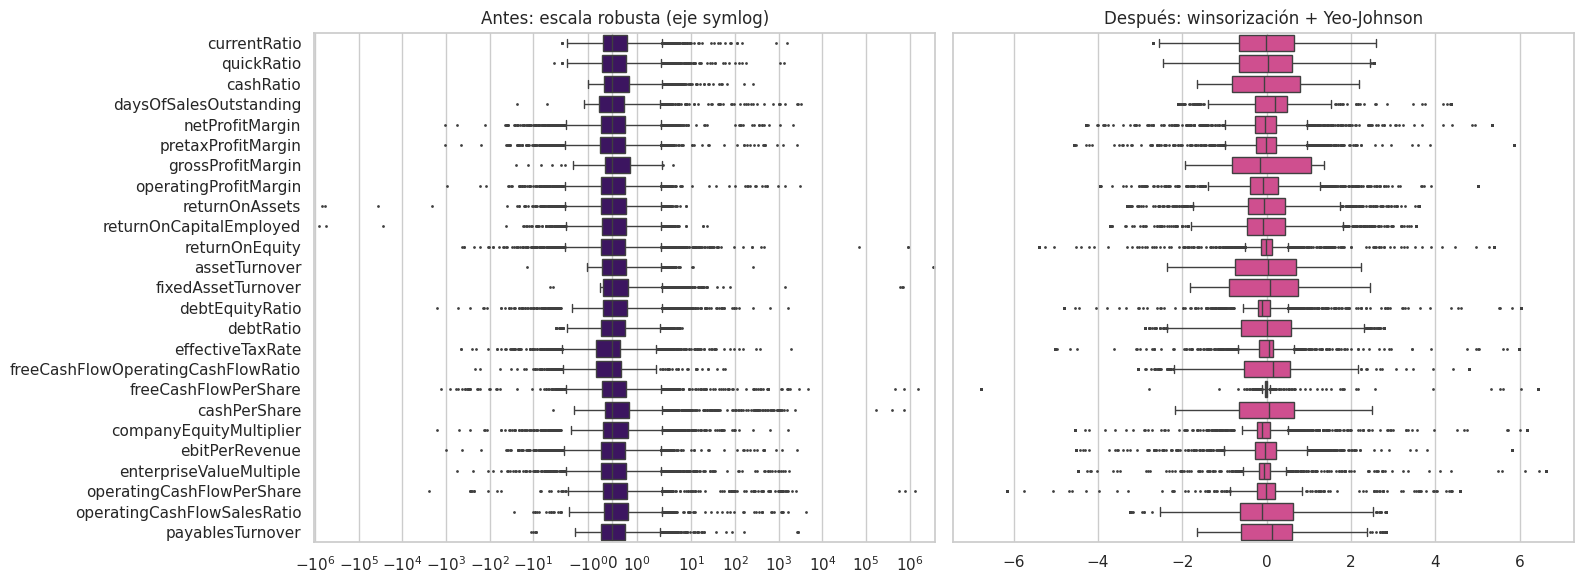

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=(X_raw - X_raw.median()) / (X_raw.quantile(.75) - X_raw.quantile(.25)),
            orient="h", ax=ax[0], color=MORADO, fliersize=1)
ax[0].set_xscale("symlog"); ax[0].set_title("Antes: escala robusta (eje symlog)")
sns.boxplot(data=X_num_scaled, orient="h", ax=ax[1], color=ROSADO, fliersize=1)
ax[1].set_yticklabels([]); ax[1].set_title("Después: winsorización + Yeo‑Johnson")
plt.tight_layout(); plt.show()

**Análisis:** tras el preprocesamiento los 25 indicadores quedan en la misma escala (media 0, desviación 1) y la asimetría se reduce drásticamente (de valores entre 13 y 34 a valores cercanos a 0), lo que permite que todas las variables aporten de forma equilibrada al cálculo de distancias.

Las *dummies* se dejan en 0/1 **sin estandarizar**: si se estandarizaran, un sector poco frecuente como *Finance* (50 empresas, 2,5 %) tomaría valores cercanos a 6 y dominaría las distancias. Con 0/1, dos empresas de distinto sector quedan a una distancia comparable a 1–1,5 desviaciones estándar en un indicador financiero, por lo que las categóricas influyen sin opacar a las financieras.

## 6. Análisis comparativo: base original vs. base agrupada

Se comparan dos versiones del problema:

| | **Escenario A – Base original** | **Escenario B – Base agrupada** |
|---|---|---|
| Variable de salida | `Rating` tal como viene | `Grado` |
| Nº de clases | 10 (AAA, AA, A, BBB, BB, B, CCC, CC, C, D) | 2 (Grado de inversión = AAA…BBB; Grado especulativo = BB…D) |

El objetivo es ver en cuál de los dos escenarios los indicadores financieros **separan mejor** los grupos, antes y después de aplicar clustering.

### 6.1 Distribución de clases en cada escenario

In [32]:
def resumen_clases(serie):
    t = serie.value_counts().reindex(serie.cat.categories)
    return pd.DataFrame({"n": t, "%": (t / t.sum() * 100).round(2)})

res_A, res_B = resumen_clases(df_modelo["Rating"]), resumen_clases(df_modelo["Grado"])
display(res_A.T); display(res_B.T)

def entropia_norm(p):
    p = p[p > 0] / p.sum(); return -(p * np.log(p)).sum() / np.log(len(p))

tabla_balance = pd.DataFrame({
    "Escenario A (10 clases)": [10, res_A["n"].max(), res_A["n"].min(),
                                round(res_A["n"].max() / res_A["n"].min(), 1),
                                round(res_A["n"].max() / len(df_modelo) * 100, 1),
                                round(entropia_norm(res_A["n"].values), 3)],
    "Escenario B (2 clases)":  [2, res_B["n"].max(), res_B["n"].min(),
                                round(res_B["n"].max() / res_B["n"].min(), 2),
                                round(res_B["n"].max() / len(df_modelo) * 100, 1),
                                round(entropia_norm(res_B["n"].values), 3)],
}, index=["Nº de clases", "Clase mayor (n)", "Clase menor (n)", "Razón de desbalance",
          "% clase mayoritaria (línea base)", "Entropía normalizada (1 = balance perfecto)"])
tabla_balance

,AAA,AA,A,BBB,BB,B,CCC,CC,C,D
n,7.0000,89.0000,398.0000,671.0000,490.0000,302.0000,64.0000,5.0000,2.0000,1.0000
%,0.3400,4.3900,19.6200,33.0700,24.1500,14.8800,3.1500,0.2500,0.1000,0.0500


,Grado de inversión,Grado especulativo
n,"1,165.0000",864.0000
%,57.4200,42.5800


,Escenario A (10 clases),Escenario B (2 clases)
Nº de clases,10.0000,2.0000
Clase mayor (n),671.0000,"1,165.0000"
Clase menor (n),1.0000,864.0000
Razón de desbalance,671.0000,1.3500
% clase mayoritaria (línea base),33.1000,57.4000
Entropía normalizada (1 = balance perfecto),0.6960,0.9840


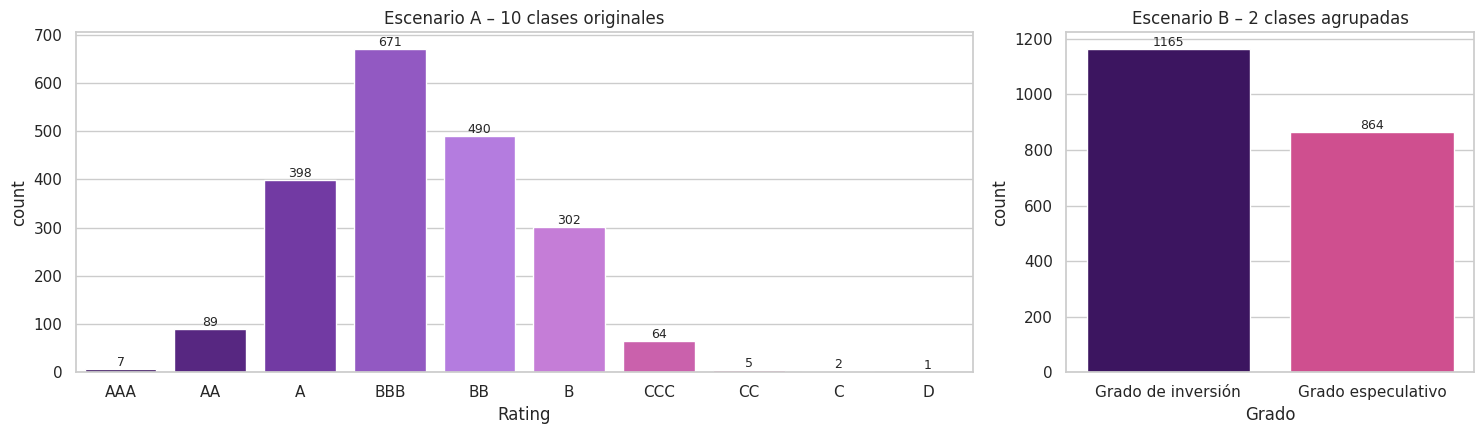

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
sns.countplot(data=df_modelo, x="Rating", ax=ax[0], palette=paleta(10))
ax[0].set_title("Escenario A – 10 clases originales")
sns.countplot(data=df_modelo, x="Grado", ax=ax[1], palette=[MORADO, ROSADO])
ax[1].set_title("Escenario B – 2 clases agrupadas")
for a in ax:
    for p in a.patches:
        a.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                   ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

### 6.2 Poder discriminante de cada variable en ambos escenarios

In [34]:
filas = []
for c in features:
    grupos_A = [g[c].values for _, g in df_modelo.groupby("Rating", observed=True)]
    H, pA = stats.kruskal(*grupos_A)                         # Kruskal‑Wallis (10 grupos)
    g0, g1 = df_modelo.loc[y_binaria == 0, c], df_modelo.loc[y_binaria == 1, c]
    U, pB = stats.mannwhitneyu(g0, g1)                       # Mann‑Whitney (2 grupos)
    rbis = 1 - 2 * U / (len(g0) * len(g1))                   # tamaño del efecto (r biserial)
    filas.append({
        "variable": c,
        "rho_vs_Rating (A)": stats.spearmanr(df_modelo[c], y_original)[0],
        "p_Kruskal (A)": pA,
        "eta2_H (A)": (H - 10 + 1) / (len(df_modelo) - 10),   # tamaño de efecto epsilon²/eta² de H
        "rho_vs_Grado (B)": stats.spearmanr(df_modelo[c], y_binaria)[0],
        "p_MannWhitney (B)": pB,
        "r_biserial (B)": rbis,
        "mediana_inversion": g0.median(), "mediana_especulativo": g1.median(),
    })
discrim = pd.DataFrame(filas).set_index("variable").sort_values("rho_vs_Rating (A)", key=abs, ascending=False)
discrim

,rho_vs_Rating (A),p_Kruskal (A),eta2_H (A),rho_vs_Grado (B),p_MannWhitney (B),r_biserial (B),mediana_inversion,mediana_especulativo
variable,,,,,,,,
returnOnCapitalEmployed,-0.4431,0.0000,0.2065,-0.3801,0.0000,-0.4438,0.0997,0.0397
returnOnAssets,-0.4388,0.0000,0.1946,-0.3759,0.0000,-0.4389,0.0582,0.0255
pretaxProfitMargin,-0.4082,0.0000,0.1754,-0.3514,0.0000,-0.4103,0.1103,0.0386
ebitPerRevenue,-0.3977,0.0000,0.1662,-0.3447,0.0000,-0.4024,0.1134,0.0412
operatingCashFlowPerShare,-0.3916,0.0000,0.1599,-0.3537,0.0000,-0.4130,5.3523,2.7186
netProfitMargin,-0.3905,0.0000,0.1569,-0.3391,0.0000,-0.3959,0.0834,0.0303
returnOnEquity,-0.3322,0.0000,0.1192,-0.3055,0.0000,-0.3567,0.1489,0.0784
operatingProfitMargin,-0.3256,0.0000,0.1084,-0.2834,0.0000,-0.3309,0.1317,0.0698
freeCashFlowPerShare,-0.2829,0.0000,0.0828,-0.2354,0.0000,-0.2749,2.8460,1.2209


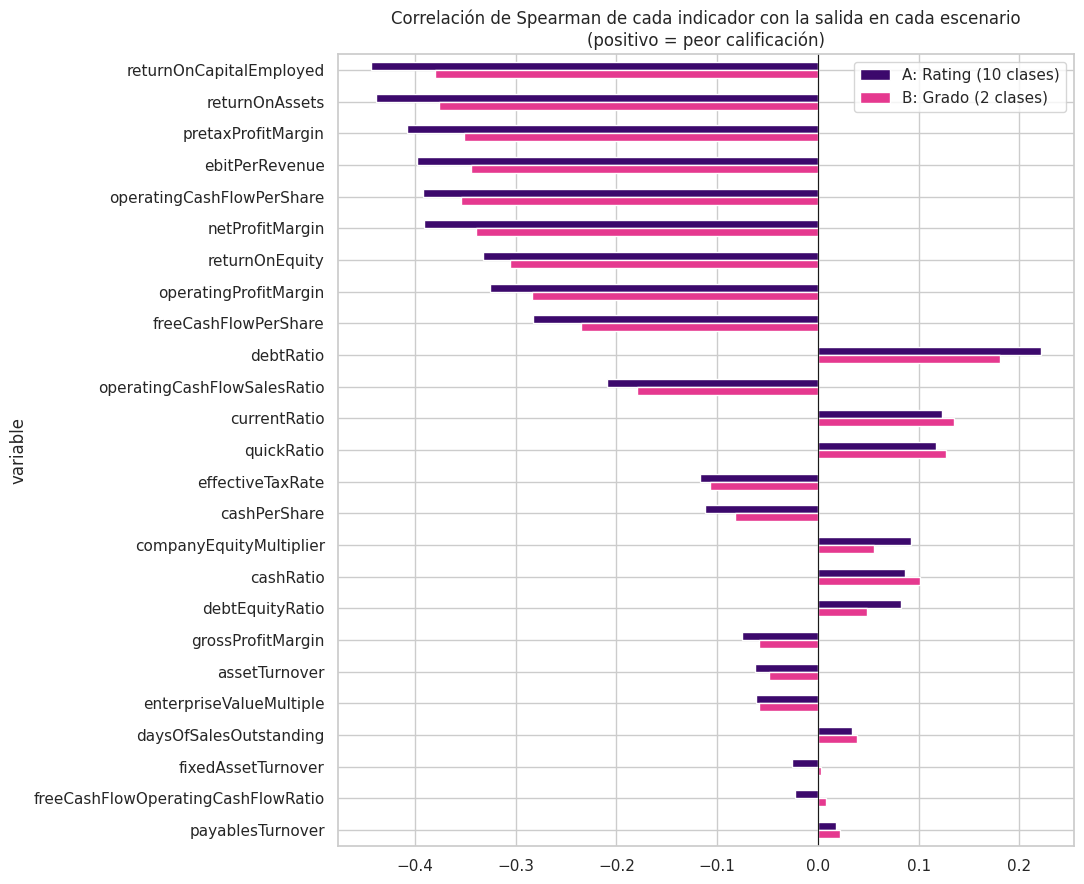

Variables significativas (p < 0.05):
  Escenario A (Kruskal‑Wallis): 24 de 25
  Escenario B (Mann‑Whitney)  : 21 de 25
Media de |rho|  A: 0.195 | B: 0.169


In [35]:
plot_df = discrim[["rho_vs_Rating (A)", "rho_vs_Grado (B)"]].rename(
    columns={"rho_vs_Rating (A)": "A: Rating (10 clases)", "rho_vs_Grado (B)": "B: Grado (2 clases)"})
plot_df.plot.barh(figsize=(11, 9), color=[MORADO, ROSADO])
plt.axvline(0, color="k", lw=.8); plt.gca().invert_yaxis()
plt.title("Correlación de Spearman de cada indicador con la salida en cada escenario\n(positivo = peor calificación)")
plt.tight_layout(); plt.show()

print("Variables significativas (p < 0.05):")
print("  Escenario A (Kruskal‑Wallis):", (discrim["p_Kruskal (A)"] < 0.05).sum(), "de", len(features))
print("  Escenario B (Mann‑Whitney)  :", (discrim["p_MannWhitney (B)"] < 0.05).sum(), "de", len(features))
print("Media de |rho|  A:", discrim["rho_vs_Rating (A)"].abs().mean().round(3),
      "| B:", discrim["rho_vs_Grado (B)"].abs().mean().round(3))

### 6.3 ¿Qué tan separables son las clases reales en el espacio de las variables?

Se calcula el **coeficiente de silueta usando las etiquetas reales** como si fueran clusters. Si las clases formaran grupos compactos y separados, la silueta sería cercana a 1; valores ≈ 0 o negativos indican que las clases se **solapan** y que será difícil que un algoritmo no supervisado las redescubra. También se proyectan los datos en 2D con **PCA**.

Silueta de las clases reales – Escenario A (10 clases): -0.0784
Silueta de las clases reales – Escenario B (2 clases) : 0.0507
Varianza explicada por PC1 + PC2: 32.8 %


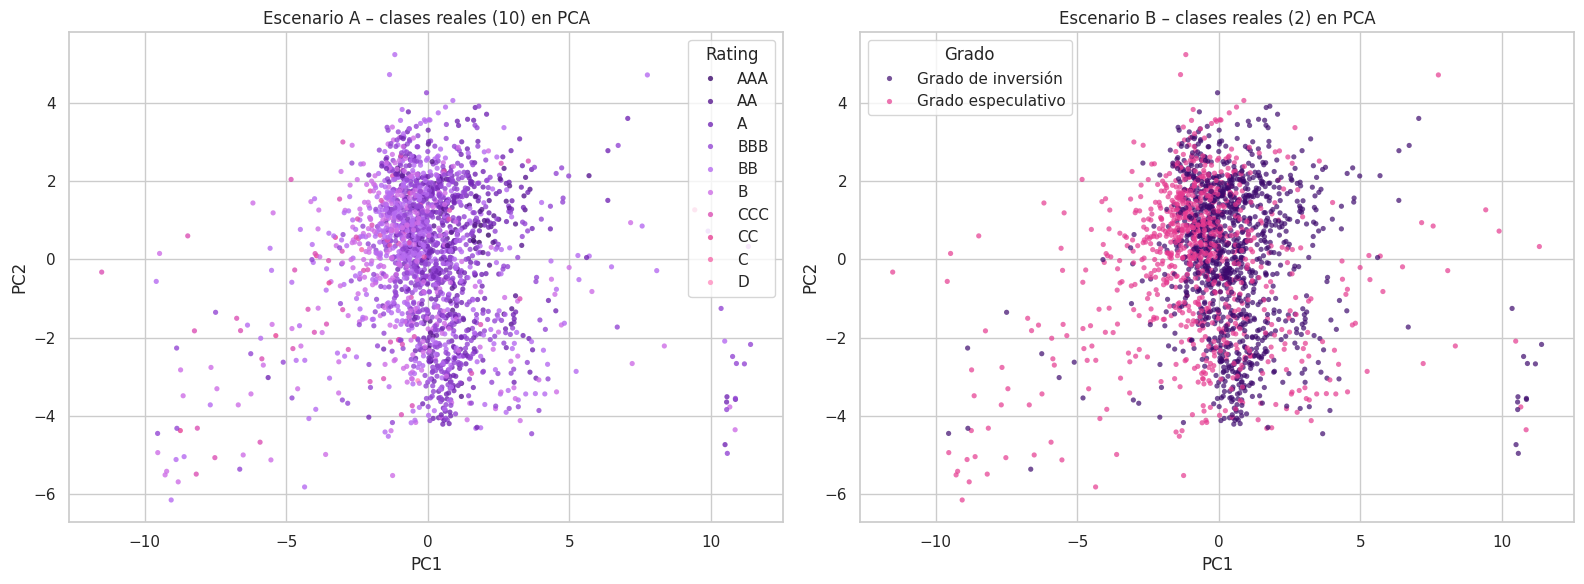

In [36]:
sil_real_A = silhouette_score(X_scaled, y_original)
sil_real_B = silhouette_score(X_scaled, y_binaria)
print(f"Silueta de las clases reales – Escenario A (10 clases): {sil_real_A:.4f}")
print(f"Silueta de las clases reales – Escenario B (2 clases) : {sil_real_B:.4f}")

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"Varianza explicada por PC1 + PC2: {pca.explained_variance_ratio_.sum()*100:.1f} %")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_modelo["Rating"], palette=paleta(10),
                s=14, alpha=.8, ax=ax[0], linewidth=0)
ax[0].set_title("Escenario A – clases reales (10) en PCA")
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_modelo["Grado"], palette=[MORADO, ROSADO],
                s=14, alpha=.7, ax=ax[1], linewidth=0)
ax[1].set_title("Escenario B – clases reales (2) en PCA")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Análisis comparativo (A vs. B):**
- **Balance:** el escenario A tiene una razón de desbalance de **671 : 1** y cuatro clases con menos de 10 registros; el escenario B queda casi balanceado (**57,4 % / 42,6 %**). Un algoritmo de clustering tiende a formar grupos de tamaño comparable, por lo que el escenario B es mucho más compatible con lo que estos métodos pueden descubrir.
- **Poder discriminante:** compare en la tabla y en la gráfica las correlaciones de cada variable con la salida en ambos escenarios. Las variables de rentabilidad y flujo de caja son las más discriminantes en ambos casos, y en el escenario B el tamaño del efecto (*r* biserial) permite ver directamente qué tan distintas son las medianas de las empresas en grado de inversión frente a las especulativas.
- **Separabilidad:** la silueta calculada con las etiquetas reales cuantifica qué tanto se solapan las clases. En el gráfico PCA se observa que las calificaciones forman un **gradiente continuo** y no grupos aislados, especialmente entre clases vecinas (A–BBB–BB), lo que anticipa que el clustering no recreará exactamente las 10 clases.

## 7. Aprendizaje no supervisado

Se aplican los tres métodos vistos en clase **sin usar la variable de salida** (`Rating` / `Grado`); los modelos solo ven la matriz `X_scaled` de 37 variables (25 indicadores + 12 *dummies* de `Sector`).

- **K‑Means**
- **Clustering jerárquico aglomerativo** (enlaces *ward*, *complete* y *average*)
- **DBSCAN**

**Punto 5.1:** se prueba un rango de **k = 2 … 12 clusters**, que incluye **k = 10** (número de clases de la base original) y **k = 2** (número de clases de la base agrupada).

**Métricas utilizadas**

| Tipo | Métrica | Interpretación |
|---|---|---|
| Internas (sin etiquetas) | Silueta | −1 a 1; mayor = clusters más compactos y separados |
| | Davies‑Bouldin | ≥ 0; **menor** es mejor |
| | Calinski‑Harabasz | mayor es mejor |
| | Inercia (K‑Means) | método del codo |
| Externas (comparan con las clases reales, **solo para evaluar**) | **ARI** – Adjusted Rand Index | 0 = azar, 1 = coincidencia perfecta; corrige por azar y por desbalance → **métrica principal** |
| | NMI – Información mutua normalizada | 0 a 1 |
| | Homogeneidad / Completitud / V‑measure | cada cluster tiene una sola clase / cada clase cae en un solo cluster |
| | Pureza | % de muestras que pertenecen a la clase mayoritaria de su cluster |
| | *Accuracy* húngara | *accuracy* asignando a cada cluster una clase distinta (asignación óptima) |

In [37]:
K_RANGE = list(range(2, 13))   # incluye k = 2 (agrupada) y k = 10 (original)

def pureza(y, c):
    ct = pd.crosstab(c, y)
    return ct.max(axis=1).sum() / len(y)

def accuracy_hungara(y, c):
    # Asigna a cada cluster una clase distinta maximizando aciertos (algoritmo húngaro)
    ct = pd.crosstab(c, y).values
    filas, cols = linear_sum_assignment(-ct)
    return ct[filas, cols].sum() / len(y)

def evaluar(labels, X=X_scaled):
    labels = np.asarray(labels)
    no_ruido = labels != -1
    n_cl = len(set(labels[no_ruido]))
    r = {"n_clusters": n_cl, "%_ruido": round((~no_ruido).mean() * 100, 2)}
    if 2 <= n_cl < no_ruido.sum():
        Xi, li = X[no_ruido], labels[no_ruido]
        r.update(silueta=silhouette_score(Xi, li), davies_bouldin=davies_bouldin_score(Xi, li),
                 calinski=calinski_harabasz_score(Xi, li))
    else:
        r.update(silueta=np.nan, davies_bouldin=np.nan, calinski=np.nan)
    for tag, y in (("A", y_original), ("B", y_binaria)):
        r[f"ARI_{tag}"] = adjusted_rand_score(y, labels)
        r[f"NMI_{tag}"] = normalized_mutual_info_score(y, labels)
        r[f"homog_{tag}"] = homogeneity_score(y, labels)
        r[f"complet_{tag}"] = completeness_score(y, labels)
        r[f"V_{tag}"] = v_measure_score(y, labels)
        r[f"pureza_{tag}"] = pureza(y, labels)
        r[f"acc_hung_{tag}"] = accuracy_hungara(y, labels)
    return r

def graficar_metricas(res, titulo, col_grupo=None):
    # Métricas internas y externas vs. número de clusters
    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    paneles = [("silueta", "Silueta (↑)"), ("davies_bouldin", "Davies‑Bouldin (↓)"),
               ("calinski", "Calinski‑Harabasz (↑)"), ("ARI_A", "ARI vs Rating – 10 clases (↑)"),
               ("ARI_B", "ARI vs Grado – 2 clases (↑)"), ("NMI_A", "NMI vs Rating – 10 clases (↑)")]
    grupos_ = [(None, res)] if col_grupo is None else list(res.groupby(col_grupo))
    cols_ = paleta(max(len(grupos_), 2))
    for a, (m, t) in zip(axes.ravel(), paneles):
        for (g, d), colr in zip(grupos_, cols_):
            a.plot(d["k"], d[m], marker="o", color=colr, label=g)
        a.axvline(N_CLASES_ORIGINAL, color=ROSADO, ls="--", lw=1)
        a.axvline(N_CLASES_BINARIA, color=MORADO, ls=":", lw=1)
        a.set_title(t); a.set_xlabel("k"); a.set_xticks(K_RANGE)
        if col_grupo: a.legend(fontsize=8)
    fig.suptitle(titulo + "   (línea rosada: k = 10 | línea morada: k = 2)", fontsize=14)
    plt.tight_layout(); plt.show()

### 7.1 K‑Means

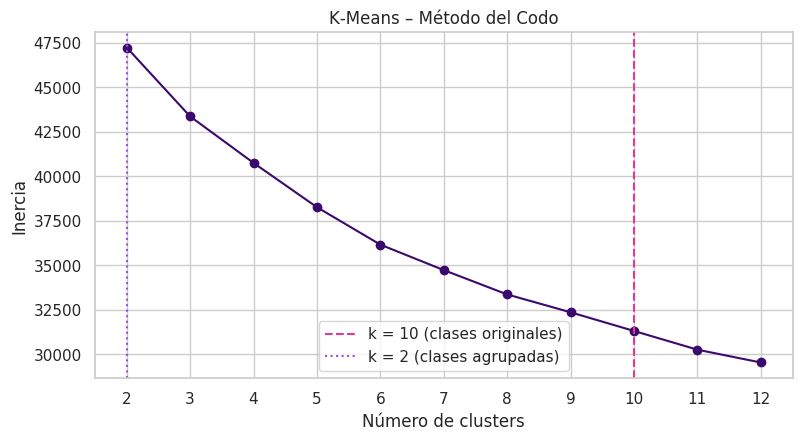

,k,inercia,n_clusters,%_ruido,silueta,davies_bouldin,calinski,ARI_A,NMI_A,homog_A,complet_A,V_A,pureza_A,acc_hung_A,ARI_B,NMI_B,homog_B,complet_B,V_B,pureza_B,acc_hung_B
0,2,"47,234.5025",2,0.0000,0.1279,2.4983,227.7252,0.0097,0.0152,0.0107,0.0266,0.0152,0.3307,0.3075,0.0039,0.0139,0.0135,0.0143,0.0139,0.5742,0.5402
1,3,"43,363.4200",3,0.0000,0.1504,2.0679,214.3982,0.0140,0.0286,0.0213,0.0433,0.0286,0.3376,0.3051,0.0109,0.0277,0.0298,0.0258,0.0277,0.6037,0.4879
2,4,"40,751.4269",4,0.0000,0.1058,2.2262,195.2823,0.0118,0.0318,0.0280,0.0368,0.0318,0.3381,0.2893,0.0120,0.0237,0.0330,0.0185,0.0237,0.6047,0.3775
3,5,"38,263.1448",5,0.0000,0.1136,1.9627,188.8161,0.0126,0.0352,0.0316,0.0397,0.0352,0.3386,0.2844,0.0155,0.0257,0.0369,0.0197,0.0257,0.6067,0.3770
4,6,"36,159.5648",6,0.0000,0.1189,1.7837,183.2981,0.0161,0.0396,0.0363,0.0434,0.0396,0.3381,0.2903,0.0195,0.0276,0.0410,0.0208,0.0276,0.6057,0.3844
5,7,"34,729.1179",7,0.0000,0.1232,1.6722,172.8417,0.0156,0.0391,0.0366,0.0420,0.0391,0.3396,0.2903,0.0200,0.0268,0.0409,0.0200,0.0268,0.6047,0.3815
6,8,"33,362.2486",8,0.0000,0.1169,1.7180,165.9723,0.0270,0.0560,0.0567,0.0552,0.0560,0.3445,0.2829,0.0263,0.0421,0.0719,0.0298,0.0421,0.6230,0.2888
7,9,"32,359.1054",9,0.0000,0.1190,1.7048,157.4813,0.0259,0.0580,0.0598,0.0563,0.0580,0.3509,0.2652,0.0371,0.0422,0.0738,0.0296,0.0422,0.6668,0.3036
8,10,"31,310.2919",10,0.0000,0.1206,1.6284,152.1155,0.0279,0.0591,0.0619,0.0566,0.0591,0.3499,0.2592,0.0354,0.0450,0.0804,0.0312,0.0450,0.6634,0.2987
9,11,"30,258.0025",11,0.0000,0.1269,1.5427,148.6129,0.0304,0.0626,0.0664,0.0593,0.0626,0.3544,0.2725,0.0217,0.0432,0.0784,0.0298,0.0432,0.6195,0.2716


In [38]:
# Método del codo + métricas para cada k
res_km, modelos_km = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    lab = km.fit_predict(X_scaled)
    modelos_km[k] = lab
    res_km.append({"k": k, "inercia": km.inertia_, **evaluar(lab)})
res_km = pd.DataFrame(res_km)

plt.figure(figsize=(9, 4.5))
plt.plot(res_km["k"], res_km["inercia"], marker="o", color=MORADO)
plt.axvline(N_CLASES_ORIGINAL, color=ROSADO, ls="--", label="k = 10 (clases originales)")
plt.axvline(N_CLASES_BINARIA, color=LILA, ls=":", label="k = 2 (clases agrupadas)")
plt.title("K‑Means – Método del Codo"); plt.xlabel("Número de clusters"); plt.ylabel("Inercia")
plt.xticks(K_RANGE); plt.legend(); plt.show()

res_km.round(4)

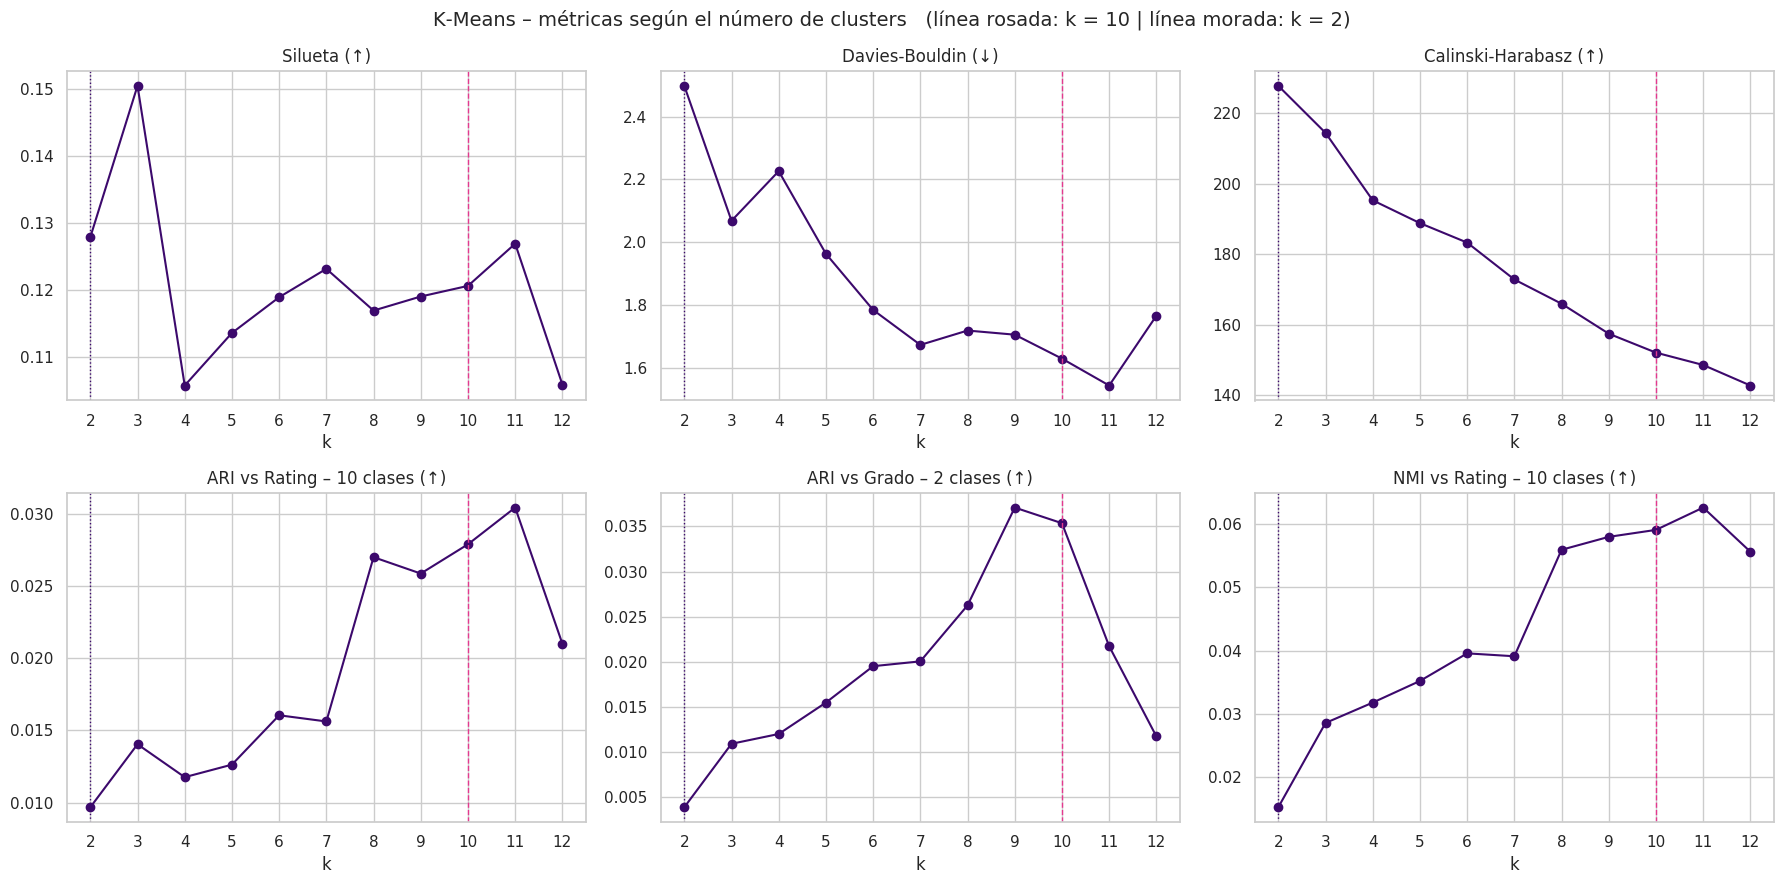

In [39]:
graficar_metricas(res_km, "K‑Means – métricas según el número de clusters")

Silhouette Score KMeans k=10: 0.1206
Silhouette Score KMeans k=2 : 0.1279


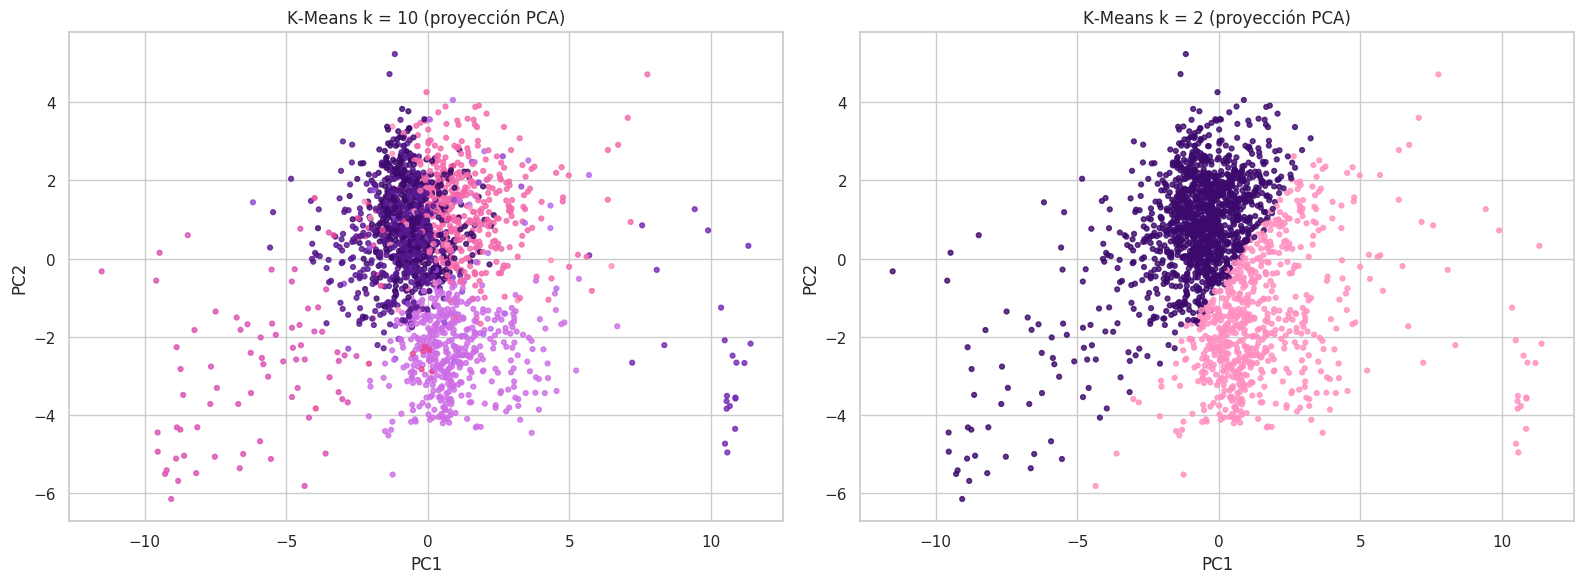

In [40]:
# Modelos finales de K‑Means para los dos escenarios
labels_km10 = modelos_km[N_CLASES_ORIGINAL]
labels_km2  = modelos_km[N_CLASES_BINARIA]
print(f"Silhouette Score KMeans k=10: {silhouette_score(X_scaled, labels_km10):.4f}")
print(f"Silhouette Score KMeans k=2 : {silhouette_score(X_scaled, labels_km2):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, lab, t in zip(ax, [labels_km10, labels_km2], ["K‑Means k = 10", "K‑Means k = 2"]):
    a.scatter(X_pca[:, 0], X_pca[:, 1], c=lab, cmap=CMAP_MR, s=12, alpha=.8)
    a.set_title(t + " (proyección PCA)"); a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Análisis K‑Means:**
- En la curva del codo la inercia disminuye de forma suave, sin un "codo" muy marcado, lo que indica que los datos no tienen grupos naturales muy definidos.
- Revise en la tabla `res_km` qué *k* maximiza la silueta (estructura interna) y qué *k* maximiza el ARI frente a cada escenario: no necesariamente coinciden, porque la estructura natural de los datos financieros no tiene por qué ser la misma que la de las calificaciones.
- K‑Means asume clusters esféricos de tamaño similar, mientras que las clases reales están muy desbalanceadas (escenario A), lo que limita su capacidad para recrear las 10 calificaciones.

### 7.2 Clustering jerárquico aglomerativo

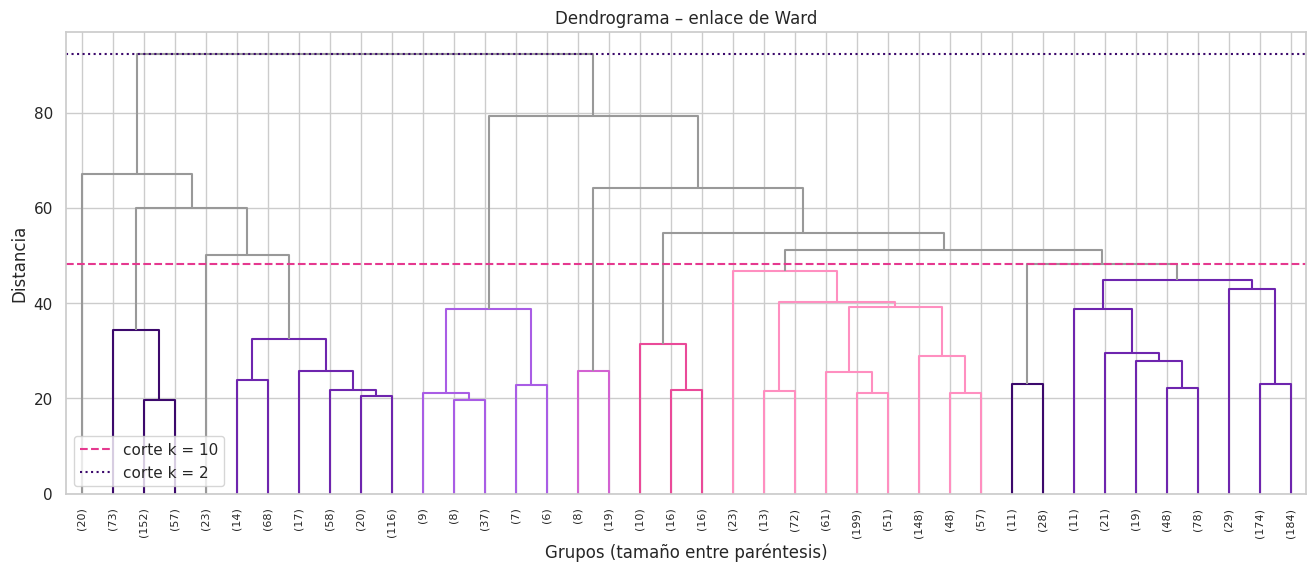

In [41]:
# Dendrograma (enlace de Ward) – se trunca a los últimos 40 grupos fusionados para que sea legible
set_link_color_palette(paleta(6))
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(16, 6))
dendrogram(linked, truncate_mode="lastp", p=40, leaf_rotation=90,
           color_threshold=linked[-(N_CLASES_ORIGINAL - 1), 2], above_threshold_color="#999999")
plt.axhline(linked[-(N_CLASES_ORIGINAL - 1), 2], color=ROSADO, ls="--", label="corte k = 10")
plt.axhline(linked[-(N_CLASES_BINARIA - 1), 2], color=MORADO, ls=":", label="corte k = 2")
plt.title("Dendrograma – enlace de Ward"); plt.xlabel("Grupos (tamaño entre paréntesis)")
plt.ylabel("Distancia"); plt.legend(); plt.show()

In [42]:
LINKAGES = ["ward", "complete", "average"]
res_agg, modelos_agg = [], {}
for link in LINKAGES:
    for k in K_RANGE:
        agg = AgglomerativeClustering(n_clusters=k, linkage=link)
        lab = agg.fit_predict(X_scaled)
        modelos_agg[(link, k)] = lab
        res_agg.append({"linkage": link, "k": k, **evaluar(lab)})
res_agg = pd.DataFrame(res_agg)
res_agg.round(4)

,linkage,k,n_clusters,%_ruido,silueta,davies_bouldin,calinski,ARI_A,NMI_A,homog_A,complet_A,V_A,pureza_A,acc_hung_A,ARI_B,NMI_B,homog_B,complet_B,V_B,pureza_B,acc_hung_B
0,ward,2,2,0.0000,0.1017,2.7223,178.9826,0.0025,0.0116,0.0080,0.0209,0.0116,0.3307,0.3041,-0.0014,0.0108,0.0102,0.0114,0.0108,0.5742,0.5244
1,ward,3,3,0.0000,0.1167,2.2801,166.0427,0.0110,0.0256,0.0187,0.0402,0.0256,0.3371,0.3105,0.0069,0.0241,0.0253,0.0231,0.0241,0.5964,0.4968
2,ward,4,4,0.0000,0.1074,1.9575,151.8147,0.0105,0.0260,0.0194,0.0393,0.0260,0.3371,0.3110,0.0064,0.0235,0.0254,0.0219,0.0235,0.5964,0.4909
3,ward,5,5,0.0000,0.1179,1.7511,144.9787,0.0112,0.0280,0.0215,0.0402,0.0280,0.3371,0.3075,0.0070,0.0226,0.0255,0.0203,0.0226,0.5964,0.4845
4,ward,6,6,0.0000,0.0946,1.8070,139.9281,0.0104,0.0295,0.0245,0.0371,0.0295,0.3371,0.3011,-0.0000,0.0205,0.0262,0.0169,0.0205,0.5964,0.4110
5,ward,7,7,0.0000,0.1049,1.8340,134.6596,0.0198,0.0409,0.0351,0.0489,0.0409,0.3420,0.3026,0.0062,0.0281,0.0377,0.0223,0.0281,0.6111,0.4081
6,ward,8,8,0.0000,0.0735,2.1753,129.9451,0.0227,0.0473,0.0470,0.0475,0.0473,0.3420,0.2711,0.0193,0.0308,0.0512,0.0220,0.0308,0.6235,0.3696
7,ward,9,9,0.0000,0.0770,2.0308,126.7761,0.0232,0.0481,0.0484,0.0477,0.0481,0.3435,0.2711,0.0193,0.0309,0.0523,0.0219,0.0309,0.6235,0.3696
8,ward,10,10,0.0000,0.0812,1.9314,124.1775,0.0234,0.0488,0.0502,0.0474,0.0488,0.3480,0.2632,0.0197,0.0318,0.0555,0.0223,0.0318,0.6235,0.3553
9,ward,11,11,0.0000,0.0857,1.8519,122.1467,0.0266,0.0546,0.0570,0.0523,0.0546,0.3524,0.2622,0.0240,0.0379,0.0675,0.0263,0.0379,0.6328,0.3544


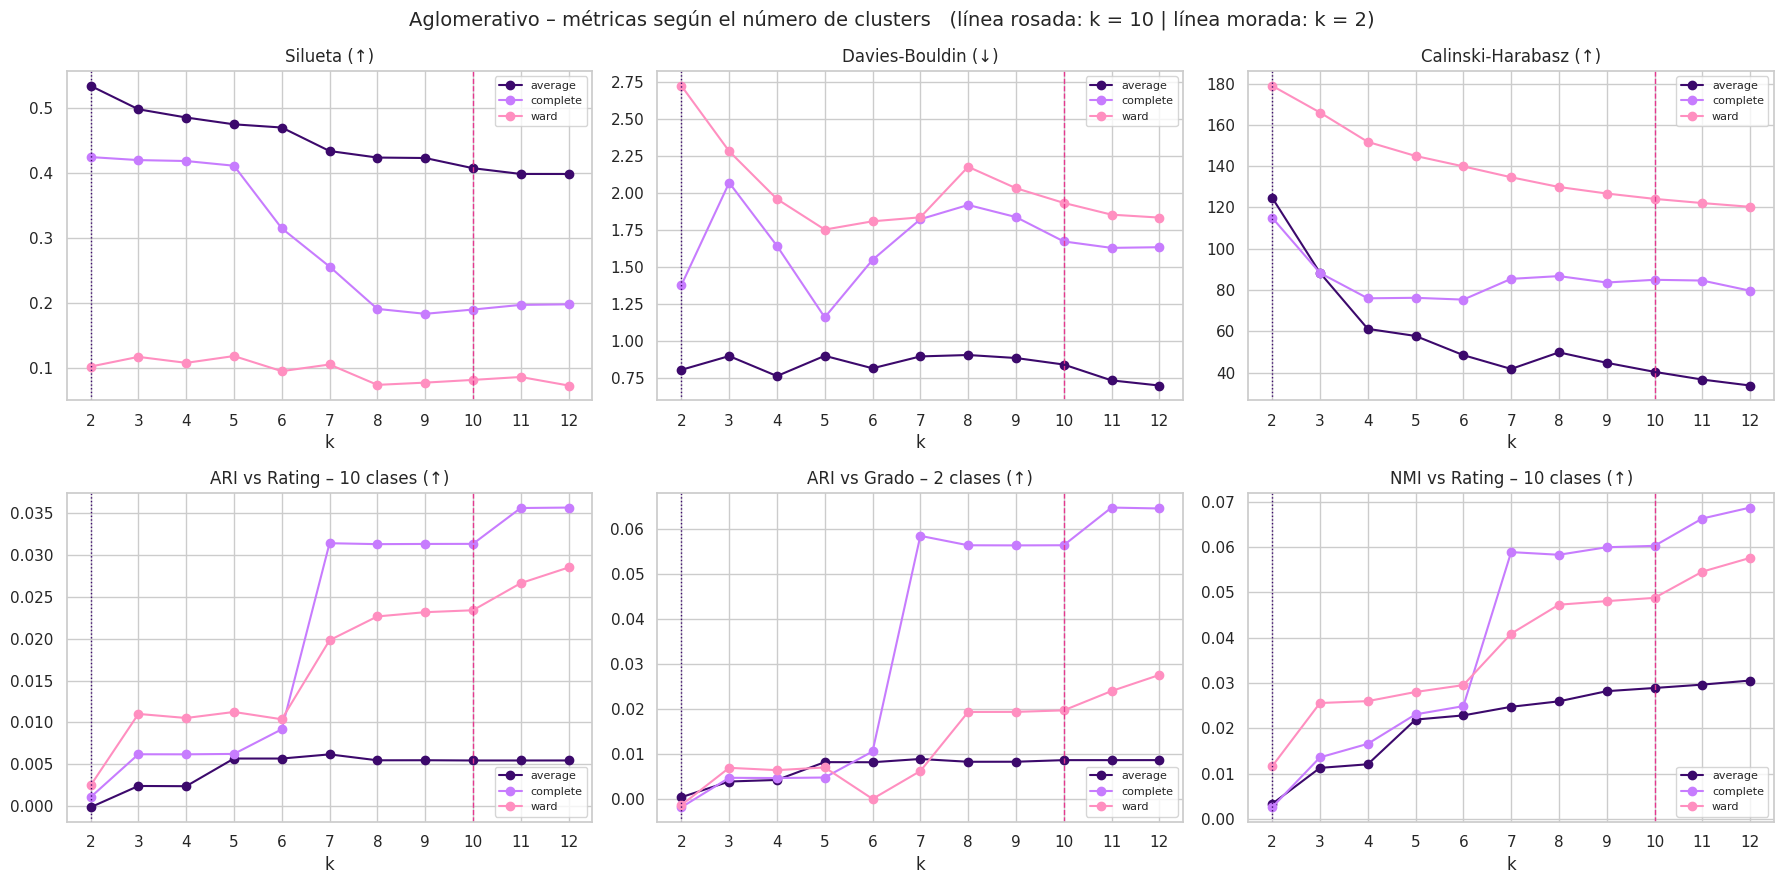

% de muestras en el cluster más grande (k = 10):
  ward     : 33.1 %
  complete : 83.6 %
  average  : 96.6 %


In [43]:
graficar_metricas(res_agg, "Aglomerativo – métricas según el número de clusters", col_grupo="linkage")

# Tamaño del cluster más grande (detecta si el método forma un "mega‑cluster")
tam = {(l, k): np.bincount(lab).max() / len(lab) * 100 for (l, k), lab in modelos_agg.items()}
print("% de muestras en el cluster más grande (k = 10):")
for l in LINKAGES: print(f"  {l:9s}: {tam[(l, N_CLASES_ORIGINAL)]:.1f} %")

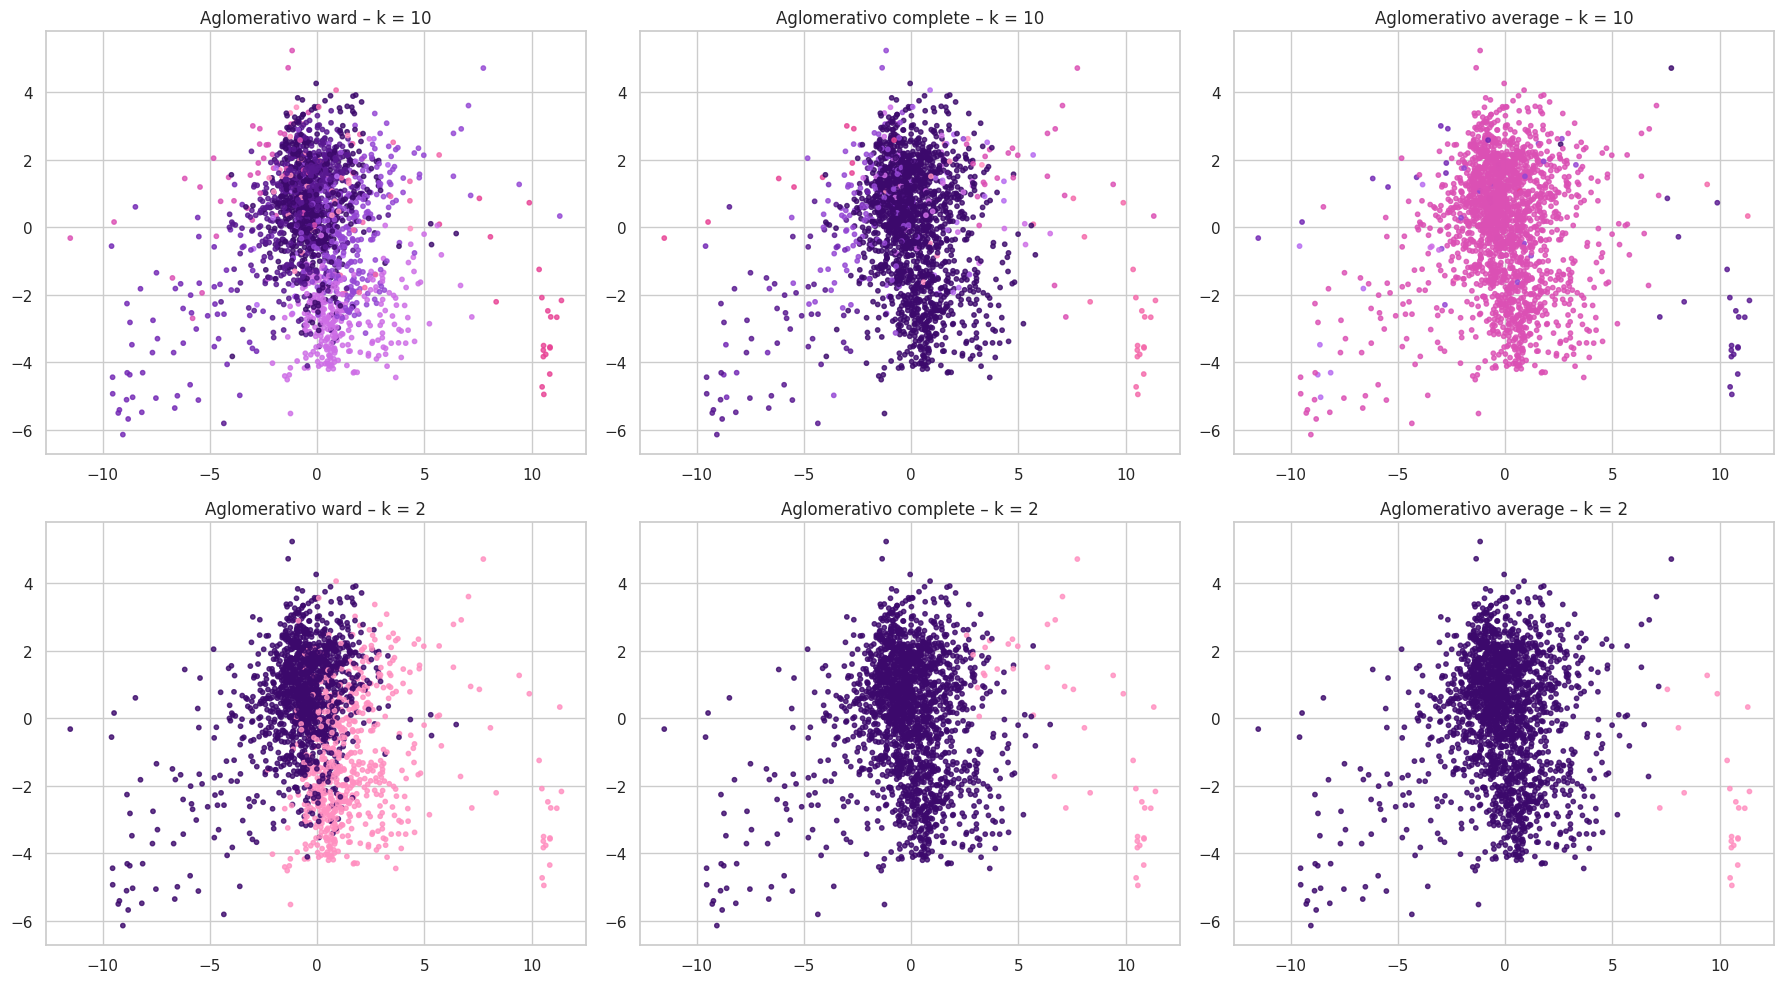

In [44]:
fig, ax = plt.subplots(2, 3, figsize=(18, 10))
for j, link in enumerate(LINKAGES):
    for i, k in enumerate([N_CLASES_ORIGINAL, N_CLASES_BINARIA]):
        lab = modelos_agg[(link, k)]
        ax[i, j].scatter(X_pca[:, 0], X_pca[:, 1], c=lab, cmap=CMAP_MR, s=10, alpha=.8)
        ax[i, j].set_title(f"Aglomerativo {link} – k = {k}")
plt.tight_layout(); plt.show()

**Análisis aglomerativo:**
- El enlace **ward** minimiza la varianza intra‑cluster (igual criterio que K‑Means) y produce grupos de tamaños comparables.
- Los enlaces **complete** y sobre todo **average** son sensibles a los puntos alejados: suelen formar un cluster gigante con casi todas las empresas y varios clusters de muy pocos puntos (vea el porcentaje del cluster más grande). Esto puede dar siluetas altas, pero no corresponde a una segmentación útil.
- El dendrograma permite ver a qué distancia se fusionan los grupos; los cortes a *k* = 10 y *k* = 2 están marcados con las líneas punteadas.

### 7.3 DBSCAN
DBSCAN **no recibe el número de clusters**: este depende de `eps` (radio del vecindario) y `min_samples` (puntos mínimos para formar un núcleo). Para cumplir el punto 5.1 se hace una **búsqueda en malla** de ambos parámetros y se registra cuántos clusters encuentra cada combinación, buscando configuraciones que generen **10** y **2** clusters.

Primero se usa el **gráfico de k‑distancias** para elegir un rango razonable de `eps`.

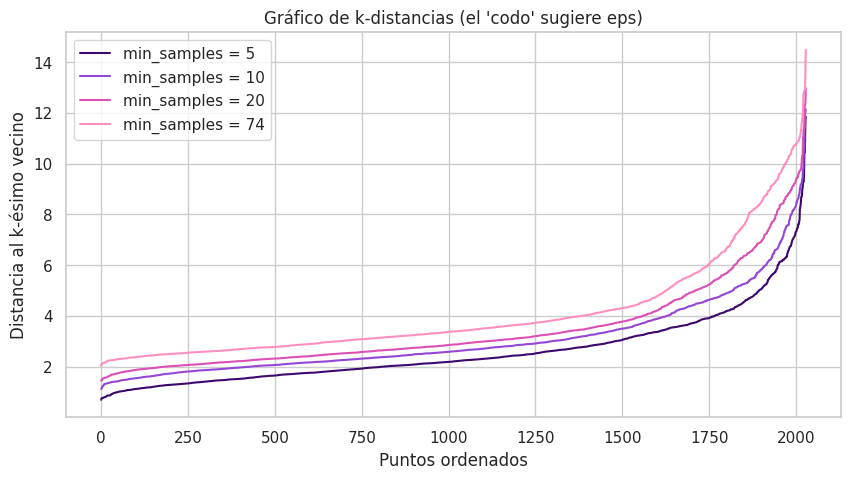

Rango de eps evaluado: 1.406 → 8.023 (30 valores)


In [45]:
MIN_SAMPLES = [5, 10, 20, 2 * X_scaled.shape[1]]   # 2·dimensión es una regla habitual
plt.figure(figsize=(10, 5))
for ms, colr in zip(MIN_SAMPLES, paleta(len(MIN_SAMPLES))):
    dist, _ = NearestNeighbors(n_neighbors=ms).fit(X_scaled).kneighbors(X_scaled)
    plt.plot(np.sort(dist[:, -1]), color=colr, label=f"min_samples = {ms}")
plt.title("Gráfico de k‑distancias (el 'codo' sugiere eps)")
plt.xlabel("Puntos ordenados"); plt.ylabel("Distancia al k‑ésimo vecino"); plt.legend(); plt.show()

dist10, _ = NearestNeighbors(n_neighbors=10).fit(X_scaled).kneighbors(X_scaled)
EPS_GRID = np.round(np.unique(np.quantile(dist10[:, -1], np.linspace(0.02, 0.98, 30))), 3)
print("Rango de eps evaluado:", EPS_GRID.min(), "→", EPS_GRID.max(), f"({len(EPS_GRID)} valores)")

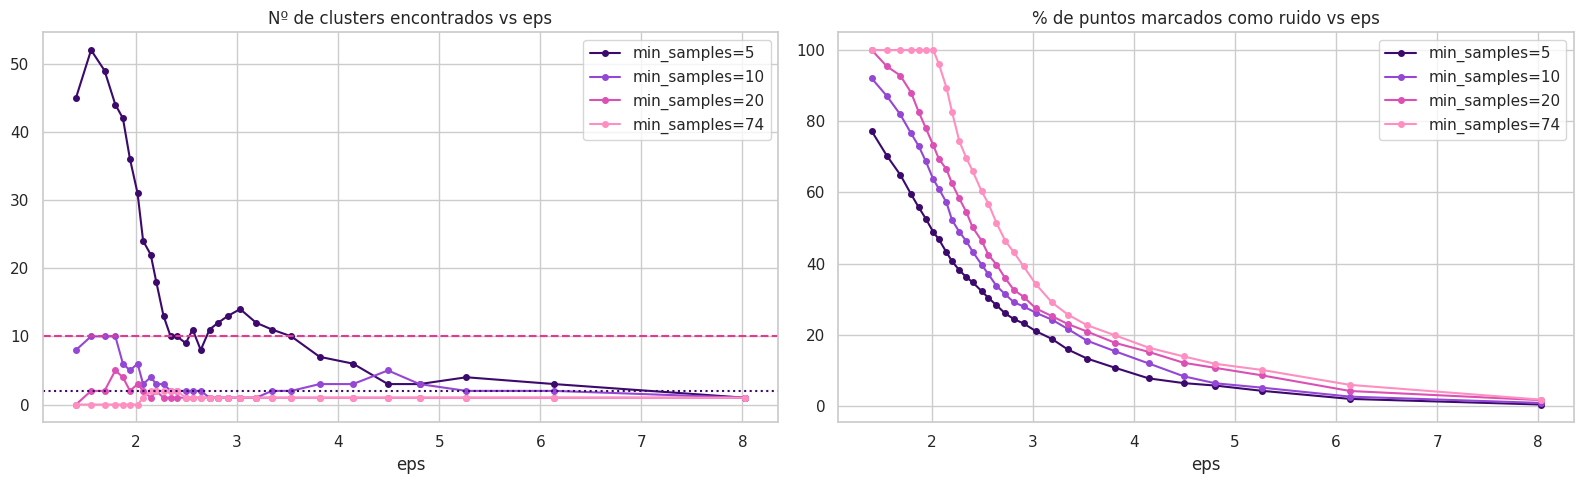

Número de clusters que DBSCAN logró encontrar: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(18), np.int64(22), np.int64(24), np.int64(31), np.int64(36), np.int64(42), np.int64(44), np.int64(45), np.int64(49), np.int64(52)]


,eps,min_samples,n_clusters,%_ruido,silueta,davies_bouldin,calinski,ARI_A,NMI_A,homog_A,complet_A,V_A,pureza_A,acc_hung_A,ARI_B,NMI_B,homog_B,complet_B,V_B,pureza_B,acc_hung_B
61,1.5550,20,2,95.4200,0.6522,0.5149,312.6302,-0.0033,0.0190,0.0108,0.0798,0.0190,0.3307,0.3253,-0.0142,0.0287,0.0189,0.0594,0.0287,0.5742,0.5352
52,3.5360,10,2,18.3300,0.6170,0.4617,115.9550,0.0434,0.0546,0.0359,0.1136,0.0546,0.3519,0.3519,0.0818,0.0641,0.0558,0.0752,0.0641,0.6520,0.6481
62,1.6880,20,2,92.8500,0.5940,0.6162,351.1782,-0.0055,0.0242,0.0144,0.0753,0.0242,0.3307,0.3204,-0.0177,0.0370,0.0268,0.0596,0.0370,0.5742,0.5165
57,5.2680,10,2,5.1300,0.5646,0.5447,112.5521,0.0200,0.0426,0.0245,0.1618,0.0426,0.3470,0.3450,0.0322,0.0588,0.0399,0.1119,0.0588,0.6146,0.6087
58,6.1380,10,2,2.6100,0.5513,0.6040,115.4966,0.0116,0.0318,0.0175,0.1685,0.0318,0.3396,0.3376,0.0172,0.0440,0.0274,0.1120,0.0440,0.5983,0.5924
98,2.1450,74,2,89.4500,0.5448,0.6942,368.4461,-0.0084,0.0289,0.0181,0.0717,0.0289,0.3307,0.3115,-0.0190,0.0401,0.0320,0.0539,0.0401,0.5742,0.5002
28,6.1380,5,3,1.9700,0.4793,0.7462,76.2823,0.0103,0.0295,0.0163,0.1552,0.0295,0.3391,0.3361,0.0148,0.0380,0.0237,0.0960,0.0380,0.5954,0.5860
99,2.2000,74,2,82.6500,0.4646,0.8243,363.6124,-0.0136,0.0320,0.0217,0.0616,0.0320,0.3307,0.3026,-0.0163,0.0366,0.0334,0.0404,0.0366,0.5742,0.4786
54,4.1460,10,3,11.9300,0.4413,0.6788,84.0563,0.0305,0.0470,0.0298,0.1109,0.0470,0.3465,0.3455,0.0525,0.0492,0.0401,0.0634,0.0492,0.6304,0.6225
25,4.4920,5,3,6.4100,0.4333,0.5354,69.4931,0.0225,0.0492,0.0291,0.1578,0.0492,0.3509,0.3484,0.0416,0.0705,0.0505,0.1165,0.0705,0.6244,0.6166


In [46]:
res_db, modelos_db = [], {}
for ms in MIN_SAMPLES:
    for eps in EPS_GRID:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        modelos_db[(eps, ms)] = lab
        res_db.append({"eps": eps, "min_samples": ms, **evaluar(lab)})
res_db = pd.DataFrame(res_db)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for ms, colr in zip(MIN_SAMPLES, paleta(len(MIN_SAMPLES))):
    d = res_db[res_db["min_samples"] == ms]
    ax[0].plot(d["eps"], d["n_clusters"], marker="o", ms=4, color=colr, label=f"min_samples={ms}")
    ax[1].plot(d["eps"], d["%_ruido"], marker="o", ms=4, color=colr, label=f"min_samples={ms}")
ax[0].axhline(N_CLASES_ORIGINAL, color=ROSADO, ls="--"); ax[0].axhline(N_CLASES_BINARIA, color=MORADO, ls=":")
ax[0].set_title("Nº de clusters encontrados vs eps"); ax[1].set_title("% de puntos marcados como ruido vs eps")
for a in ax: a.set_xlabel("eps"); a.legend()
plt.tight_layout(); plt.show()

print("Número de clusters que DBSCAN logró encontrar:", sorted(res_db["n_clusters"].unique()))
res_db.sort_values("silueta", ascending=False).head(10).round(4)

DBSCAN objetivo 10: eps=3.536, min_samples=5 -> 10 clusters, 13.3% ruido, silueta=0.2441
DBSCAN objetivo 2: eps=3.536, min_samples=10 -> 2 clusters, 18.3% ruido, silueta=0.6170


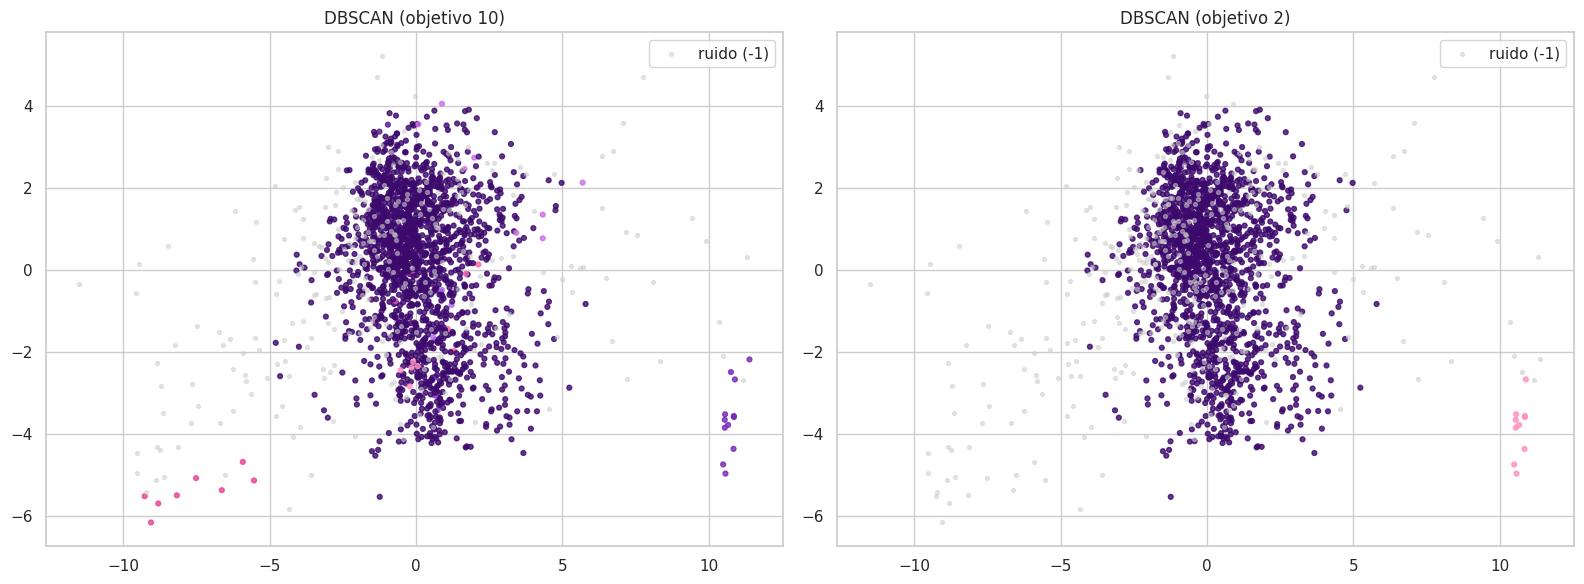

In [47]:
def elegir_dbscan(objetivo, max_ruido=50):
    # Elige la configuración con nº de clusters más cercano al objetivo (ruido <= max_ruido %);
    # el desempate se hace con la silueta (métrica interna, NO usa las etiquetas reales)
    cand = res_db[(res_db["n_clusters"] >= 2) & (res_db["%_ruido"] <= max_ruido)].copy()
    if cand.empty:
        cand = res_db[res_db["n_clusters"] >= 1].copy()
    cand["dist_obj"] = (cand["n_clusters"] - objetivo).abs()
    best = cand.sort_values(["dist_obj", "silueta"], ascending=[True, False]).iloc[0]
    return (best["eps"], int(best["min_samples"])), best

cfg_db10, fila_db10 = elegir_dbscan(N_CLASES_ORIGINAL)
cfg_db2,  fila_db2  = elegir_dbscan(N_CLASES_BINARIA)
labels_db10, labels_db2 = modelos_db[cfg_db10], modelos_db[cfg_db2]

for nombre, cfg, fila in [("objetivo 10", cfg_db10, fila_db10), ("objetivo 2", cfg_db2, fila_db2)]:
    print(f"DBSCAN {nombre}: eps={cfg[0]}, min_samples={cfg[1]} -> "
          f"{int(fila['n_clusters'])} clusters, {fila['%_ruido']:.1f}% ruido, silueta={fila['silueta']:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, lab, t in zip(ax, [labels_db10, labels_db2], ["DBSCAN (objetivo 10)", "DBSCAN (objetivo 2)"]):
    ruido = lab == -1
    a.scatter(X_pca[~ruido, 0], X_pca[~ruido, 1], c=lab[~ruido], cmap=CMAP_MR, s=12, alpha=.8)
    a.scatter(X_pca[ruido, 0], X_pca[ruido, 1], c="#cccccc", s=8, alpha=.5, label="ruido (-1)")
    a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

**Análisis DBSCAN:**
- Con 37 dimensiones las distancias entre puntos se vuelven parecidas (*maldición de la dimensionalidad*), y los datos financieros forman una **nube densa continua** sin huecos de baja densidad.
- Por eso DBSCAN tiende a encontrar **un cluster grande + ruido**, o muchos micro‑clusters cuando `eps` es pequeño. Es difícil (o imposible) obtener exactamente 10 grupos de tamaño razonable; se toma la configuración que más se acerca.
- Su ventaja es que identifica las empresas atípicas como **ruido** (-1), lo cual es útil para detectar estados financieros anómalos, pero no para recrear las calificaciones.

## 8. Comparación de modelos y selección del mejor (Punto 6 del proyecto)

Siguiendo el esquema de las prácticas, se construye una tabla de resultados con **los modelos entrenados para el número de clases de cada escenario** y se elige el que mejor **recrea los grupos de la base de datos**. El criterio principal es el **ARI** (corrige por azar y no se infla por el desbalance); como apoyo se reportan NMI, V‑measure, pureza y *accuracy* húngara.

> La pureza y la *accuracy* deben compararse con la **línea base** de asignar todo a la clase mayoritaria: **33,1 %** en el escenario A (BBB) y **57,4 %** en el escenario B (grado de inversión).

In [48]:
def tabla_resultados(escenario):
    k = N_CLASES_ORIGINAL if escenario == "A" else N_CLASES_BINARIA
    lab_db = labels_db10 if escenario == "A" else labels_db2
    candidatos = {"K‑Means": modelos_km[k],
                  "Aglomerativo ward": modelos_agg[("ward", k)],
                  "Aglomerativo complete": modelos_agg[("complete", k)],
                  "Aglomerativo average": modelos_agg[("average", k)],
                  "DBSCAN": lab_db}
    filas = []
    for nombre, lab in candidatos.items():
        r = evaluar(lab)
        filas.append({"Método": nombre, "Clusters": r["n_clusters"], "% ruido": r["%_ruido"],
                      "Silueta": r["silueta"], "ARI": r[f"ARI_{escenario}"], "NMI": r[f"NMI_{escenario}"],
                      "V-measure": r[f"V_{escenario}"], "Pureza": r[f"pureza_{escenario}"],
                      "Accuracy húngara": r[f"acc_hung_{escenario}"]})
    return pd.DataFrame(filas).sort_values("ARI", ascending=False).reset_index(drop=True), candidatos

results_A, cand_A = tabla_resultados("A")
results_B, cand_B = tabla_resultados("B")
print("ESCENARIO A – Base original (k = 10, comparado con Rating)")
display(results_A.round(4))
print("ESCENARIO B – Base agrupada (k = 2, comparado con Grado de inversión / especulativo)")
display(results_B.round(4))

ESCENARIO A – Base original (k = 10, comparado con Rating)


,Método,Clusters,% ruido,Silueta,ARI,NMI,V-measure,Pureza,Accuracy húngara
0,DBSCAN,10,13.3100,0.2441,0.0393,0.0670,0.0670,0.3578,0.3460
1,Aglomerativo complete,10,0.0000,0.1895,0.0313,0.0603,0.0603,0.3558,0.3337
2,K‑Means,10,0.0000,0.1206,0.0279,0.0591,0.0591,0.3499,0.2592
3,Aglomerativo ward,10,0.0000,0.0812,0.0234,0.0488,0.0488,0.3480,0.2632
4,Aglomerativo average,10,0.0000,0.4073,0.0054,0.0289,0.0289,0.3386,0.3302


ESCENARIO B – Base agrupada (k = 2, comparado con Grado de inversión / especulativo)


,Método,Clusters,% ruido,Silueta,ARI,NMI,V-measure,Pureza,Accuracy húngara
0,DBSCAN,2,18.3300,0.6170,0.0818,0.0641,0.0641,0.6520,0.6481
1,K‑Means,2,0.0000,0.1279,0.0039,0.0139,0.0139,0.5742,0.5402
2,Aglomerativo average,2,0.0000,0.5342,0.0003,0.0000,0.0000,0.5742,0.5732
3,Aglomerativo ward,2,0.0000,0.1017,-0.0014,0.0108,0.0108,0.5742,0.5244
4,Aglomerativo complete,2,0.0000,0.4245,-0.0019,0.0007,0.0007,0.5742,0.5678


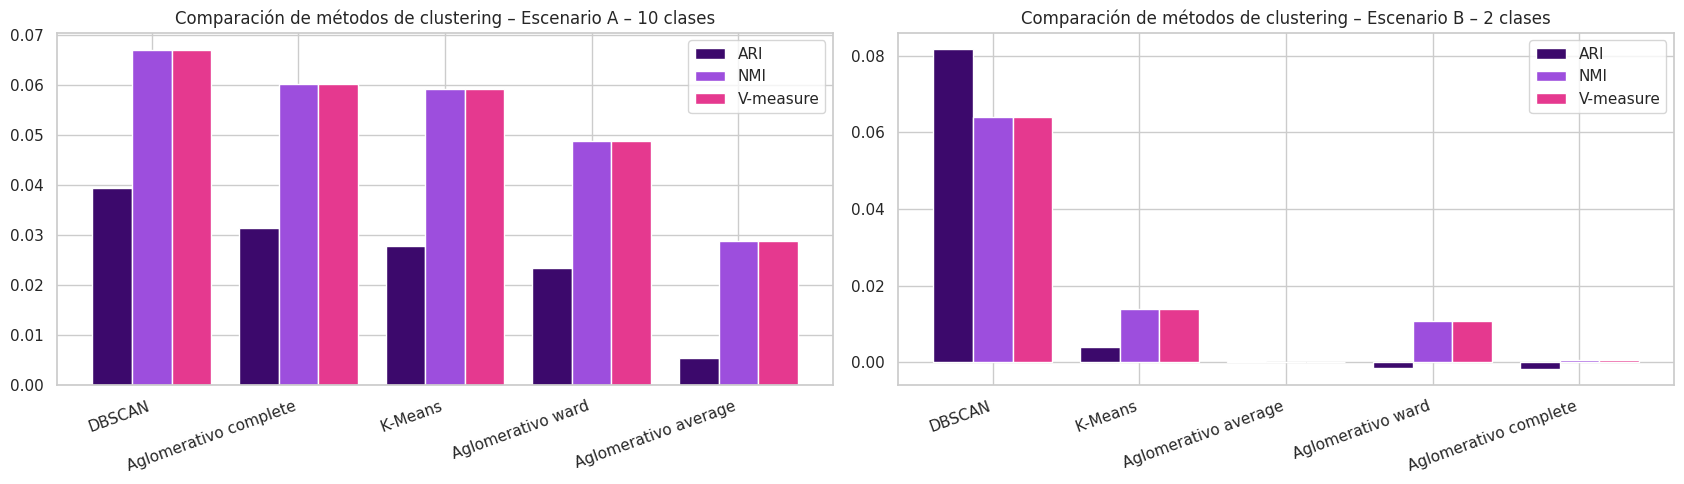

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
for a, res, t in zip(ax, [results_A, results_B], ["Escenario A – 10 clases", "Escenario B – 2 clases"]):
    x = np.arange(len(res)); w = 0.27
    a.bar(x - w, res["ARI"], w, label="ARI", color=MORADO)
    a.bar(x, res["NMI"], w, label="NMI", color=LILA)
    a.bar(x + w, res["V-measure"], w, label="V-measure", color=ROSADO)
    a.set_xticks(x); a.set_xticklabels(res["Método"], rotation=20, ha="right")
    a.set_title(f"Comparación de métodos de clustering – {t}"); a.legend()
plt.tight_layout(); plt.show()

In [50]:
best_method_A = results_A.iloc[0]["Método"]
best_method_B = results_B.iloc[0]["Método"]
print("Mejor método – Escenario A (10 clases):", best_method_A, f"| ARI = {results_A.iloc[0]['ARI']:.4f}")
print("Mejor método – Escenario B (2 clases) :", best_method_B, f"| ARI = {results_B.iloc[0]['ARI']:.4f}")

Mejor método – Escenario A (10 clases): DBSCAN | ARI = 0.0393
Mejor método – Escenario B (2 clases) : DBSCAN | ARI = 0.0818


### 8.1 Matriz de confusión (clusters vs. clases reales) del mejor modelo

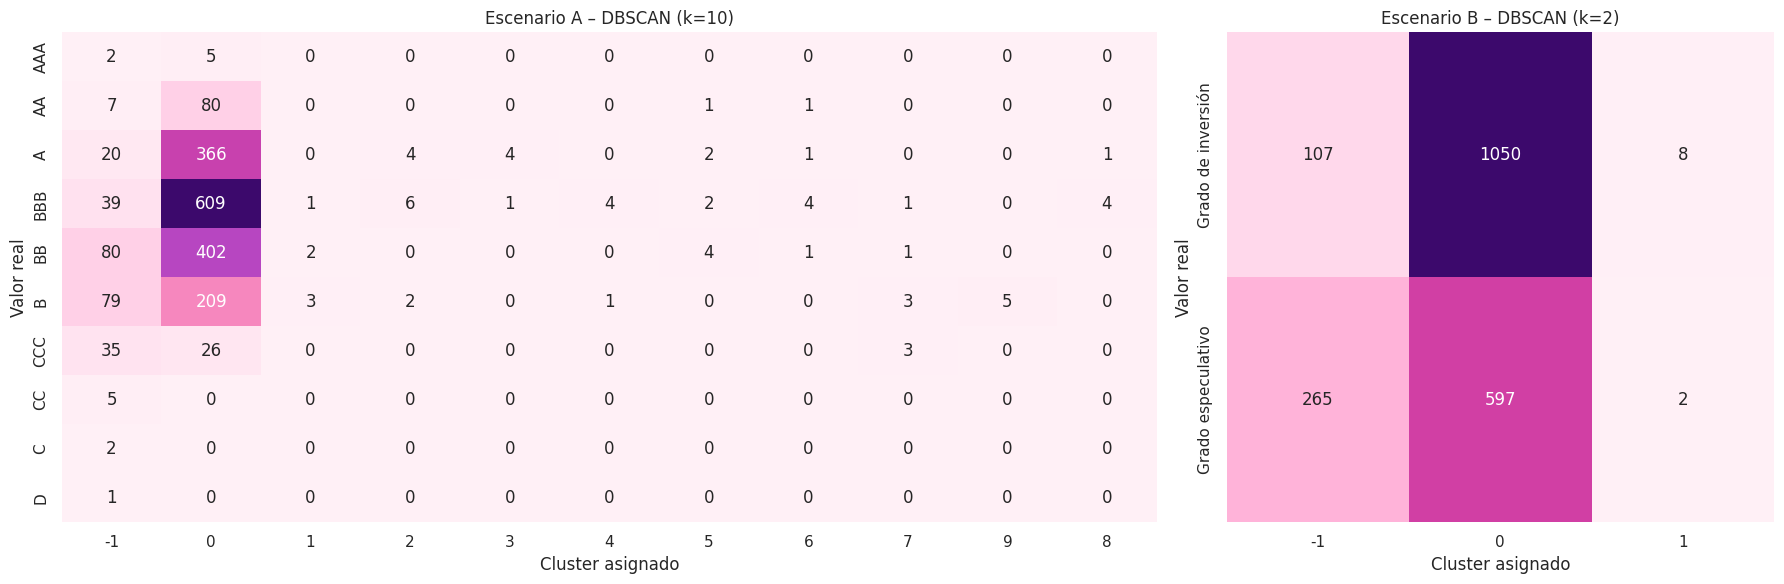

In [51]:
def matriz_clusters(y_real, labels, nombres_clases, titulo, ax):
    # Reordena los clusters con la asignación húngara para que la diagonal = coincidencias
    ct = pd.crosstab(pd.Series(labels, name="Cluster"), pd.Series(y_real, name="Clase real"))
    f, c = linear_sum_assignment(-ct.values)
    orden = list(ct.index[f]) + [i for i in ct.index if i not in ct.index[f]]
    ct = ct.loc[orden].T
    ct.index = [nombres_clases[i] for i in ct.index]
    sns.heatmap(ct, annot=True, fmt="d", cmap=CMAP_MR_CLARO, ax=ax, cbar=False)
    ax.set_xlabel("Cluster asignado"); ax.set_ylabel("Valor real"); ax.set_title(titulo)

fig, ax = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [2, 1]})
matriz_clusters(y_original, cand_A[best_method_A], orden_rating, f"Escenario A – {best_method_A} (k=10)", ax[0])
matriz_clusters(y_binaria, cand_B[best_method_B], nombres_binaria, f"Escenario B – {best_method_B} (k=2)", ax[1])
plt.tight_layout(); plt.show()

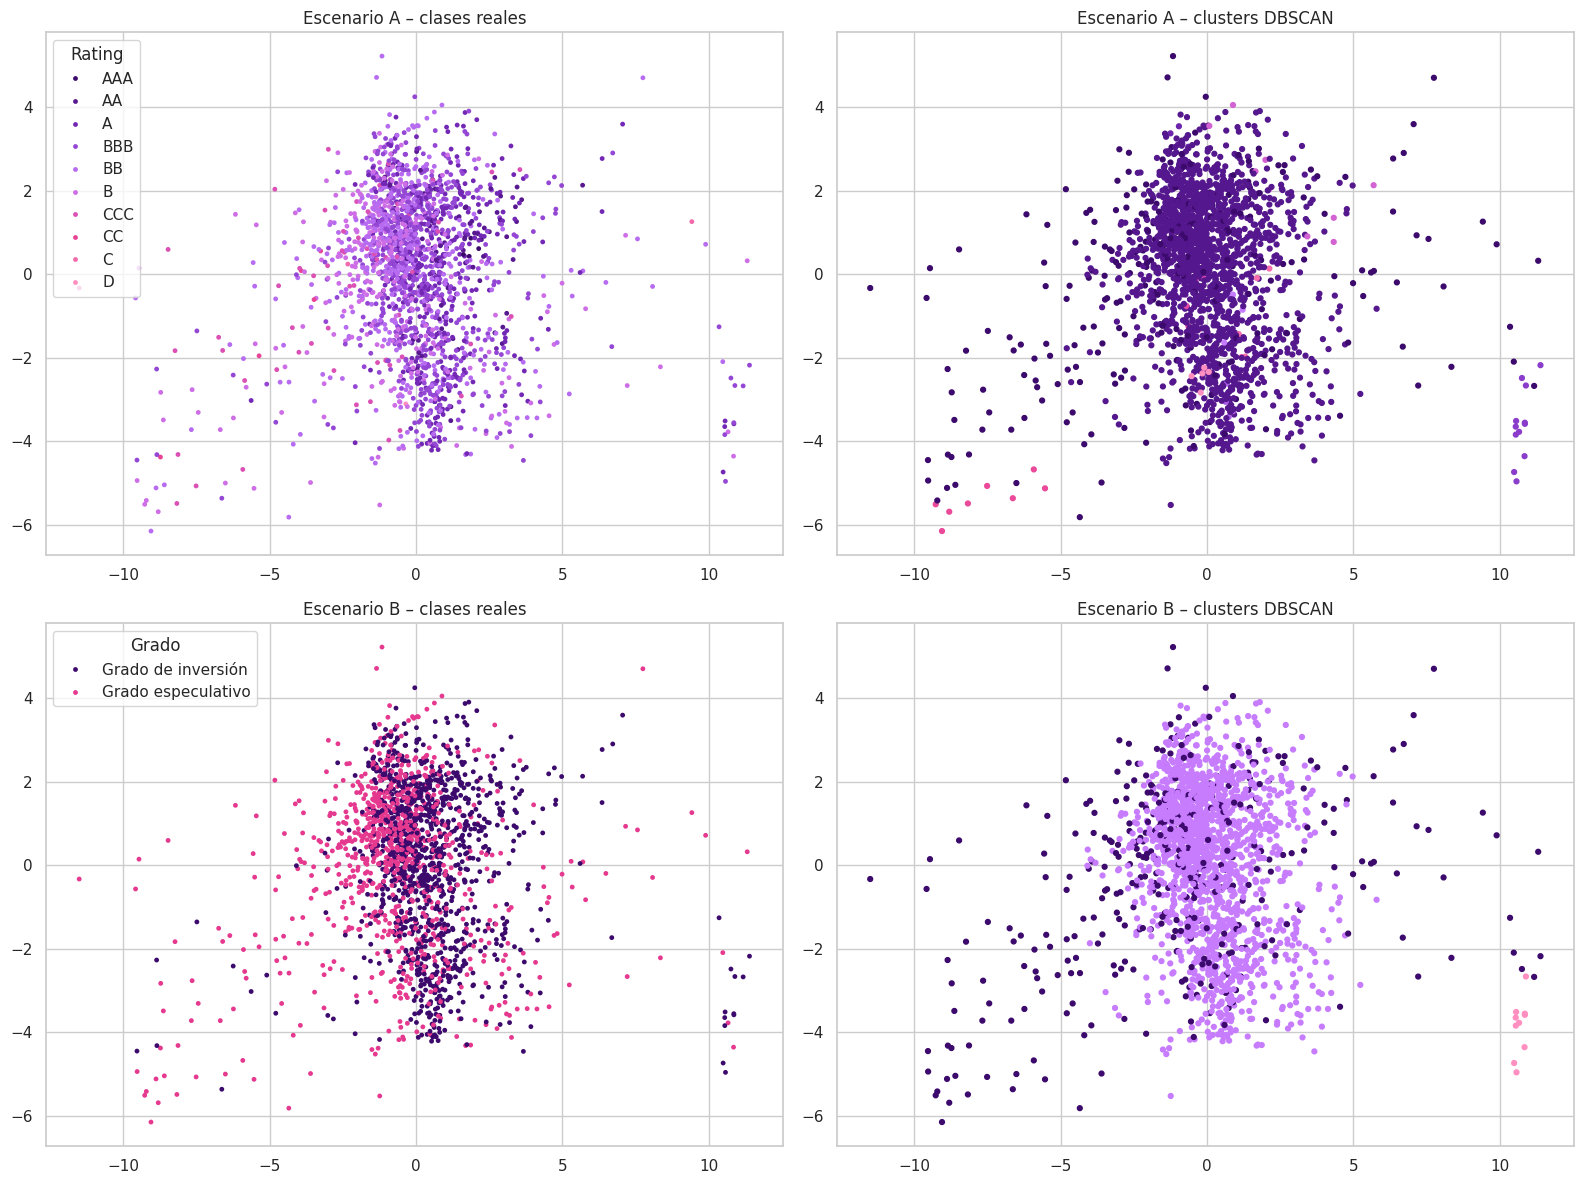

In [52]:
# Visualización: clases reales vs clusters del mejor modelo (PCA)
fig, ax = plt.subplots(2, 2, figsize=(16, 12))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_modelo["Rating"], palette=paleta(10), s=12, ax=ax[0, 0], linewidth=0)
ax[0, 0].set_title("Escenario A – clases reales")
ax[0, 1].scatter(X_pca[:, 0], X_pca[:, 1], c=cand_A[best_method_A], cmap=CMAP_MR, s=12)
ax[0, 1].set_title(f"Escenario A – clusters {best_method_A}")
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df_modelo["Grado"], palette=[MORADO, ROSADO], s=12, ax=ax[1, 0], linewidth=0)
ax[1, 0].set_title("Escenario B – clases reales")
ax[1, 1].scatter(X_pca[:, 0], X_pca[:, 1], c=cand_B[best_method_B], cmap=CMAP_MR, s=12)
ax[1, 1].set_title(f"Escenario B – clusters {best_method_B}")
plt.tight_layout(); plt.show()

In [53]:
# Perfil financiero (medianas en escala original) de los clusters del mejor modelo – escenario B
perfil_B = df_modelo[features].assign(Cluster=cand_B[best_method_B]).groupby("Cluster").median().T
pct = pd.crosstab(cand_B[best_method_B], y_binaria, normalize="index")[1] * 100
print("% de empresas en grado especulativo dentro de cada cluster:\n", pct.round(1))
perfil_B

% de empresas en grado especulativo dentro de cada cluster:
 row_0
-1   71.2000
 0   36.2000
 1   20.0000
Name: 1, dtype: float64


Cluster,-1,0,1
currentRatio,1.5049,1.4928,1.2042
quickRatio,1.0483,0.9777,0.7236
cashRatio,0.3226,0.2932,0.0985
daysOfSalesOutstanding,40.2191,42.4213,"5,536.0272"
netProfitMargin,0.0152,0.0691,29.4515
pretaxProfitMargin,0.0097,0.0916,42.7184
grossProfitMargin,0.5275,0.4006,1.0000
operatingProfitMargin,0.0540,0.1156,45.0063
returnOnAssets,0.0113,0.0493,0.0354
returnOnCapitalEmployed,0.0117,0.0835,0.0523


### 8.2 Mejor configuración de todo el barrido de k (no solo k = número de clases)

In [54]:
todo = pd.concat([res_km.assign(Método="K‑Means"),
                  res_agg.assign(Método="Aglomerativo " + res_agg["linkage"]),
                  res_db.assign(Método="DBSCAN", k=res_db["n_clusters"])], ignore_index=True)
cols_show = ["Método", "k", "eps", "min_samples", "n_clusters", "%_ruido", "silueta"]
print("Top 5 por ARI frente al Rating (10 clases):")
display(todo.sort_values("ARI_A", ascending=False)[cols_show + ["ARI_A", "NMI_A"]].head(5).round(4))
print("Top 5 por ARI frente al Grado (2 clases):")
display(todo.sort_values("ARI_B", ascending=False)[cols_show + ["ARI_B", "NMI_B"]].head(5).round(4))
print("Top 5 por silueta (estructura natural de los datos, sin etiquetas):")
display(todo[todo["n_clusters"] >= 2].sort_values("silueta", ascending=False)[cols_show].head(5).round(4))

Top 5 por ARI frente al Rating (10 clases):


,Método,k,eps,min_samples,n_clusters,%_ruido,silueta,ARI_A,NMI_A
61,DBSCAN,12,2.8120,5.0000,12,24.4000,0.0359,0.0457,0.0741
59,DBSCAN,8,2.6400,5.0000,8,28.2900,0.0741,0.0454,0.0662
62,DBSCAN,13,2.9090,5.0000,13,23.1600,0.0352,0.0452,0.0748
65,DBSCAN,11,3.3450,5.0000,11,15.8700,0.0996,0.0450,0.0742
63,DBSCAN,14,3.0300,5.0000,14,21.0000,0.0322,0.0442,0.0762


Top 5 por ARI frente al Grado (2 clases):


,Método,k,eps,min_samples,n_clusters,%_ruido,silueta,ARI_B,NMI_B
59,DBSCAN,8,2.6400,5.0000,8,28.2900,0.0741,0.0961,0.0726
58,DBSCAN,11,2.5600,5.0000,11,30.3600,-0.0214,0.0954,0.0697
61,DBSCAN,12,2.8120,5.0000,12,24.4000,0.0359,0.0946,0.0775
120,DBSCAN,1,2.7270,20.0000,1,35.8800,NaN,0.0941,0.0600
121,DBSCAN,1,2.8120,20.0000,1,32.5800,NaN,0.0939,0.0596


Top 5 por silueta (estructura natural de los datos, sin etiquetas):


,Método,k,eps,min_samples,n_clusters,%_ruido,silueta
105,DBSCAN,2,1.5550,20.0000,2,95.4200,0.6522
96,DBSCAN,2,3.5360,10.0000,2,18.3300,0.6170
106,DBSCAN,2,1.6880,20.0000,2,92.8500,0.5940
101,DBSCAN,2,5.2680,10.0000,2,5.1300,0.5646
102,DBSCAN,2,6.1380,10.0000,2,2.6100,0.5513


In [55]:
# Conclusión automática con los resultados obtenidos
bA, bB = results_A.iloc[0], results_B.iloc[0]
print("=" * 90)
print(f"ESCENARIO A (10 clases): el modelo que mejor recrea las calificaciones es {bA['Método']}")
print(f"   ARI = {bA['ARI']:.4f} | NMI = {bA['NMI']:.4f} | Pureza = {bA['Pureza']:.3f} (línea base 0.331) "
      f"| Accuracy húngara = {bA['Accuracy húngara']:.3f}")
print(f"ESCENARIO B (2 clases) : el modelo que mejor recrea los grados es {bB['Método']}")
print(f"   ARI = {bB['ARI']:.4f} | NMI = {bB['NMI']:.4f} | Pureza = {bB['Pureza']:.3f} (línea base 0.574) "
      f"| Accuracy húngara = {bB['Accuracy húngara']:.3f}")
mejor_esc = "B (agrupada)" if bB["ARI"] > bA["ARI"] else "A (original)"
print(f"\nEl escenario en el que el clustering se acerca más a la estructura real es: {mejor_esc}")
print("=" * 90)

ESCENARIO A (10 clases): el modelo que mejor recrea las calificaciones es DBSCAN
   ARI = 0.0393 | NMI = 0.0670 | Pureza = 0.358 (línea base 0.331) | Accuracy húngara = 0.346
ESCENARIO B (2 clases) : el modelo que mejor recrea los grados es DBSCAN
   ARI = 0.0818 | NMI = 0.0641 | Pureza = 0.652 (línea base 0.574) | Accuracy húngara = 0.648

El escenario en el que el clustering se acerca más a la estructura real es: B (agrupada)


## 9. Conclusiones finales

### Lo realizado
- Se **eliminaron las variables identificadoras (`Name`, `Symbol`), la fecha (`Date`/`Year`) y la agencia (`Rating Agency Name`)**. `Sector` se **conservó y codificó con one‑hot** (12 *dummies*), y se mantuvieron **los 25 indicadores financieros**, incluso los muy correlacionados, porque la reducción de variables corresponde a la etapa de selección de características. Los indicadores se winsorizaron y transformaron con Yeo‑Johnson.
- Se comparó la **base original (10 clases)** con la **base agrupada (grado de inversión vs. especulativo)** en balance, poder discriminante y separabilidad.
- Se aplicaron **K‑Means**, **Aglomerativo** (ward, complete, average) y **DBSCAN** sin usar la variable de salida, probando **k = 2 … 12** (incluye k = 10 y k = 2) y una malla de `eps` × `min_samples` para DBSCAN.
- Se compararon los modelos con métricas internas (silueta, Davies‑Bouldin, Calinski‑Harabasz) y externas (ARI, NMI, V‑measure, pureza, *accuracy* húngara), y se eligió el mejor para cada escenario (ver la salida de la celda anterior).

### Interpretación
- **Ningún método no supervisado recrea fielmente las 10 calificaciones:** las clases están extremadamente desbalanceadas (4 clases con menos de 10 empresas) y forman un gradiente continuo en el espacio financiero, mientras que los algoritmos buscan grupos compactos de tamaño similar. Un ARI cercano a 0 en el escenario A significa que la partición es poco mejor que el azar.
- **La agrupación en grado de inversión / especulativo es más compatible con el clustering:** el escenario B está balanceado y sus diferencias en rentabilidad, flujo de caja y endeudamiento son más claras, por lo que los métodos que forman grupos equilibrados (K‑Means y Aglomerativo ward) suelen obtener allí su mejor ARI y una pureza por encima de la línea base.
- **K‑Means y Aglomerativo ward** se comportan de forma parecida (mismo criterio de varianza) y son los candidatos más estables. **Complete / average** tienden a crear un mega‑cluster y **DBSCAN** no encuentra estructura de densidad útil en 37 dimensiones, aunque sirve para detectar empresas atípicas.
- La calificación crediticia depende también de información que no está en estas razones (tamaño de la empresa, calidad de la gerencia, entorno del sector, criterio de cada agencia), por lo que este problema se resuelve mejor con **aprendizaje supervisado**; el clustering aporta una segmentación de riesgo financiero útil como variable adicional o para análisis exploratorio.

---
# PARTE 2 – Reducción de dimensión y clasificación con Redes Neuronales Artificiales

En esta parte se resuelve el **problema de clasificación supervisada** (predecir la calificación crediticia) usando **Redes Neuronales Artificiales (RNA)** tipo *feed‑forward* / perceptrón multicapa (MLP) con Keras, y se comparan tres estrategias de reducción de dimensión:

| Punto | Estrategia | Herramienta |
|---|---|---|
| 1 | Selección de características *wrapper* con **SFFS** (Sequential Forward Floating Selection) | `mlxtend.feature_selection.SequentialFeatureSelector` |
| 2 | Interpretación de las variables más discriminantes | resultados del SFFS |
| 3 | Extracción de características con **PCA** | `mlxtend.feature_extraction.PrincipalComponentAnalysis` |
| 4 | Extracción de características con **LDA** | `mlxtend.feature_extraction.LinearDiscriminantAnalysis` |

**Metodología de validación:** como es un modelo predictivo, todos los resultados se obtienen con **validación cruzada estratificada** (`StratifiedKFold`, 5 *folds*), que conserva en cada *fold* la proporción de cada clase. Esto es importante por el fuerte desbalance de la base. La **métrica de validación es el F1‑macro**, que da el mismo peso a todas las clases; la *accuracy* se reporta solo como referencia.

**Ambos casos:** todo se ejecuta para los dos escenarios definidos en la Parte 1:
- **Escenario A – base original:** `Rating` con **10 clases** (AAA … D).
- **Escenario B – base agrupada:** `Grado` con **2 clases** (grado de inversión vs. grado especulativo).

**Entrada:** las 37 variables preprocesadas de la sección 5 (25 indicadores financieros winsorizados + Yeo‑Johnson y 12 *dummies* de `Sector`). Ese preprocesamiento no usa la variable de salida, por lo que puede hacerse antes de la validación cruzada. En cambio, todo lo que sí usa la salida o se "aprende" (PCA, LDA y la RNA) se ajusta **dentro de cada *fold*** solo con los datos de entrenamiento.

## 10. Configuración común: librerías, escenarios y función de evaluación de la RNA

In [56]:
# !pip install mlxtend      # (Colab ya trae tensorflow/keras; mlxtend se instala en la primera celda)
import time
import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.callbacks import EarlyStopping
from keras.utils import to_categorical

from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
from mlxtend.feature_extraction import PrincipalComponentAnalysis

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore")   # p. ej. aviso de StratifiedKFold por la clase D con 1 sola muestra
os.environ["PYTHONWARNINGS"] = "ignore"   # también en los procesos paralelos del SFFS

N_FOLDS = 5
SEED = 42
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# Matriz de entrada (37 variables) como DataFrame para conservar los nombres
X_df = X_scaled_df.copy()
X_all = X_df.values.astype("float32")

ESCENARIOS = {
    "A": {"nombre": "A – Base original (10 clases)", "y": y_original, "n_clases": N_CLASES_ORIGINAL,
          "etiquetas": orden_rating},
    "B": {"nombre": "B – Base agrupada (2 clases)", "y": y_binaria, "n_clases": N_CLASES_BINARIA,
          "etiquetas": nombres_binaria},
}
for k, e in ESCENARIOS.items():
    print(f"{e['nombre']}: {X_all.shape[0]} muestras, {X_all.shape[1]} variables, "
          f"línea base (clase mayoritaria): accuracy = {np.bincount(e['y']).max() / len(e['y']):.3f}, "
          f"F1-macro = {f1_score(e['y'], np.full_like(e['y'], np.bincount(e['y']).argmax()), average='macro'):.3f}")

A – Base original (10 clases): 2029 muestras, 37 variables, línea base (clase mayoritaria): accuracy = 0.331, F1-macro = 0.050
B – Base agrupada (2 clases): 2029 muestras, 37 variables, línea base (clase mayoritaria): accuracy = 0.574, F1-macro = 0.365


### 10.1 Arquitectura de la RNA y validación cruzada estratificada

Se sigue la estructura de la práctica de redes neuronales:
- Red **secuencial** (`Sequential`) con capas ocultas `Dense` y activación **ReLU** (más `Dropout` para reducir el sobreajuste).
- **Capa de salida:**
  - Escenario A (10 clases): 10 neuronas con **softmax** y pérdida `categorical_crossentropy`. La salida se codifica con **one‑hot** y la clase asignada es la de mayor probabilidad (*argmax*).
  - Escenario B (2 clases): 1 neurona con **sigmoide** y pérdida `binary_crossentropy` (umbral 0,5).
- Optimizador **Adam** y `EarlyStopping`, que detiene el entrenamiento cuando la pérdida de validación deja de mejorar.
- En cada *fold* se crea un **modelo nuevo** (pesos reiniciados). La reducción de dimensión (PCA / LDA) y la estandarización se ajustan **solo con el *fold* de entrenamiento**.

**Métrica de validación: F1‑macro** (media ± desviación sobre los 5 *folds*).
- Para cada clase se calcula el F1, que es la media armónica entre precisión y *recall*: $F1 = 2\cdot\frac{P\cdot R}{P+R}$. Luego se promedia dando el **mismo peso a todas las clases**.
- Es la métrica con la que se elige el mejor modelo y la dimensión óptima, y también la función objetivo del SFFS.
- Se usa porque la base está desbalanceada: un modelo que solo prediga las clases grandes tiene *accuracy* alta pero F1‑macro bajo.
- La *accuracy* y la *balanced accuracy* se reportan solo como complemento.

In [57]:
EPOCAS = 100          # máximo de épocas (EarlyStopping suele detener antes)
BATCH = 64
CAPAS_BASE = (32, 16) # arquitectura base: 2 capas ocultas

def crear_rna(input_dim, n_clases, capas=CAPAS_BASE, dropout=0.2, lr=1e-3):
    model = Sequential()
    model.add(Input(shape=(input_dim,)))
    for n in capas:
        model.add(Dense(n, activation="relu"))
        if dropout:
            model.add(Dropout(dropout))
    if n_clases == 2:
        model.add(Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    else:
        model.add(Dense(n_clases, activation="softmax"))
        loss = "categorical_crossentropy"
    model.compile(loss=loss, optimizer=keras.optimizers.Adam(learning_rate=lr), metrics=["accuracy"])
    return model

def evaluar_rna(X, y, n_clases, capas=CAPAS_BASE, reductor=None, epocas=EPOCAS, dropout=0.2):
    # Validación cruzada estratificada de la RNA.
    # reductor: función (X_train, y_train) -> objeto ajustado con método .transform (PCA, LDA, ...)
    tiempo_i = time.time()
    X = np.asarray(X, dtype="float32")
    acc, bacc, f1 = [], [], []
    y_oof = np.zeros(len(y), dtype=int)          # predicciones fuera de fold (para la matriz de confusión)
    for fold, (tr, te) in enumerate(skf.split(X, y)):
        Xtr, Xte, ytr, yte = X[tr], X[te], y[tr], y[te]
        if reductor is not None:                 # PCA / LDA ajustado SOLO con entrenamiento
            red = reductor(Xtr, ytr)
            Xtr, Xte = red.transform(Xtr), red.transform(Xte)
        sc = StandardScaler().fit(Xtr)           # escala de la entrada a la red
        Xtr, Xte = sc.transform(Xtr).astype("float32"), sc.transform(Xte).astype("float32")

        keras.utils.set_random_seed(SEED + fold)
        model = crear_rna(Xtr.shape[1], n_clases, capas, dropout)
        Ytr = ytr if n_clases == 2 else to_categorical(ytr, n_clases)
        model.fit(Xtr, Ytr, epochs=epocas, batch_size=BATCH, verbose=0, validation_split=0.1,
                  callbacks=[EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)])
        proba = model.predict(Xte, verbose=0)
        pred = (proba.ravel() >= 0.5).astype(int) if n_clases == 2 else np.argmax(proba, axis=1)
        y_oof[te] = pred
        acc.append(accuracy_score(yte, pred))
        bacc.append(balanced_accuracy_score(yte, pred))
        f1.append(f1_score(yte, pred, average="macro"))
        keras.backend.clear_session()
    return {"acc": np.mean(acc), "acc_std": np.std(acc), "bacc": np.mean(bacc), "bacc_std": np.std(bacc),
            "f1": np.mean(f1), "f1_std": np.std(f1), "tiempo_s": time.time() - tiempo_i, "y_oof": y_oof}

def fmt(r):
    # Métrica principal: F1-macro (media +/- desviación entre folds)
    return f"{r['f1']:.4f} +/- {r['f1_std']:.4f}"

def f1_linea_base(y):
    # F1-macro de un clasificador trivial que siempre predice la clase mayoritaria
    return f1_score(y, np.full_like(y, np.bincount(y).argmax()), average="macro")

In [58]:
# Línea base: RNA con TODAS las 37 variables (sin reducción de dimensión)
base = {}
for k, e in ESCENARIOS.items():
    base[k] = evaluar_rna(X_all, e["y"], e["n_clases"])
    print(f"{e['nombre']:32s} | F1-macro: {fmt(base[k])} | Accuracy: {base[k]['acc']:.4f} "
          f"| Bal. acc: {base[k]['bacc']:.4f} | Tiempo: {base[k]['tiempo_s']:.1f} s")

A – Base original (10 clases)    | F1-macro: 0.1953 +/- 0.0217 | Accuracy: 0.4194 | Bal. acc: 0.1971 | Tiempo: 37.8 s
B – Base agrupada (2 clases)     | F1-macro: 0.7379 +/- 0.0246 | Accuracy: 0.7516 | Bal. acc: 0.7340 | Tiempo: 28.0 s


## 11. Punto 1 – Selección de características con SFFS (wrapper) + RNA

**SFFS (Sequential Forward Floating Selection):** parte de un conjunto vacío y, en cada paso:
1. Agrega la variable que más mejora el desempeño del modelo *wrapper* (paso *forward*).
2. Luego intenta **quitar** alguna de las variables ya elegidas si eso mejora el desempeño (paso *floating*). Así corrige elecciones tempranas que dejaron de ser útiles, algo que el SFS simple no puede hacer.

Es un método **wrapper** porque la calidad de cada subconjunto se mide con el desempeño (**F1‑macro** en validación cruzada estratificada de 5 *folds*) de un modelo de clasificación.



In [59]:
K_MAX = 15

WRAPPERS = {
    "Árbol de decisión":   DecisionTreeClassifier(max_depth=6, random_state=SEED),
    "KNN":                 KNeighborsClassifier(n_neighbors=15),
    "Regresión logística": LogisticRegression(max_iter=3000),
    "Random Forest":       RandomForestClassifier(n_estimators=50, max_depth=10, random_state=SEED, n_jobs=1),
}

sffs_res = {}      # (escenario, wrapper) -> objeto SFS ajustado
for k, e in ESCENARIOS.items():
    for nombre_w, wrapper in WRAPPERS.items():
        t0 = time.time()
        sffs = SFS(wrapper,
                   k_features=(1, K_MAX),   # mlxtend elige el mejor tamaño en este rango
                   forward=True,
                   floating=True,           # <- SFFS
                   scoring="f1_macro",       # métrica de validación: F1-macro
                   cv=skf,                  # validación cruzada estratificada
                   n_jobs=-1,
                   verbose=0)
        sffs.fit(X_df, e["y"])
        sffs_res[(k, nombre_w)] = sffs
        print(f"[{k}] {nombre_w:20s} -> {len(sffs.k_feature_names_):2d} variables | "
              f"F1-macro wrapper = {sffs.k_score_:.4f} | {time.time() - t0:.0f} s")

[A] Árbol de decisión    ->  9 variables | F1-macro wrapper = 0.2836 | 36 s
[A] KNN                  -> 13 variables | F1-macro wrapper = 0.3459 | 95 s
[A] Regresión logística  -> 14 variables | F1-macro wrapper = 0.2862 | 135 s
[A] Random Forest        -> 12 variables | F1-macro wrapper = 0.3888 | 755 s
[B] Árbol de decisión    -> 12 variables | F1-macro wrapper = 0.7587 | 37 s
[B] KNN                  -> 13 variables | F1-macro wrapper = 0.7683 | 43 s
[B] Regresión logística  -> 11 variables | F1-macro wrapper = 0.7449 | 27 s
[B] Random Forest        -> 15 variables | F1-macro wrapper = 0.8089 | 621 s


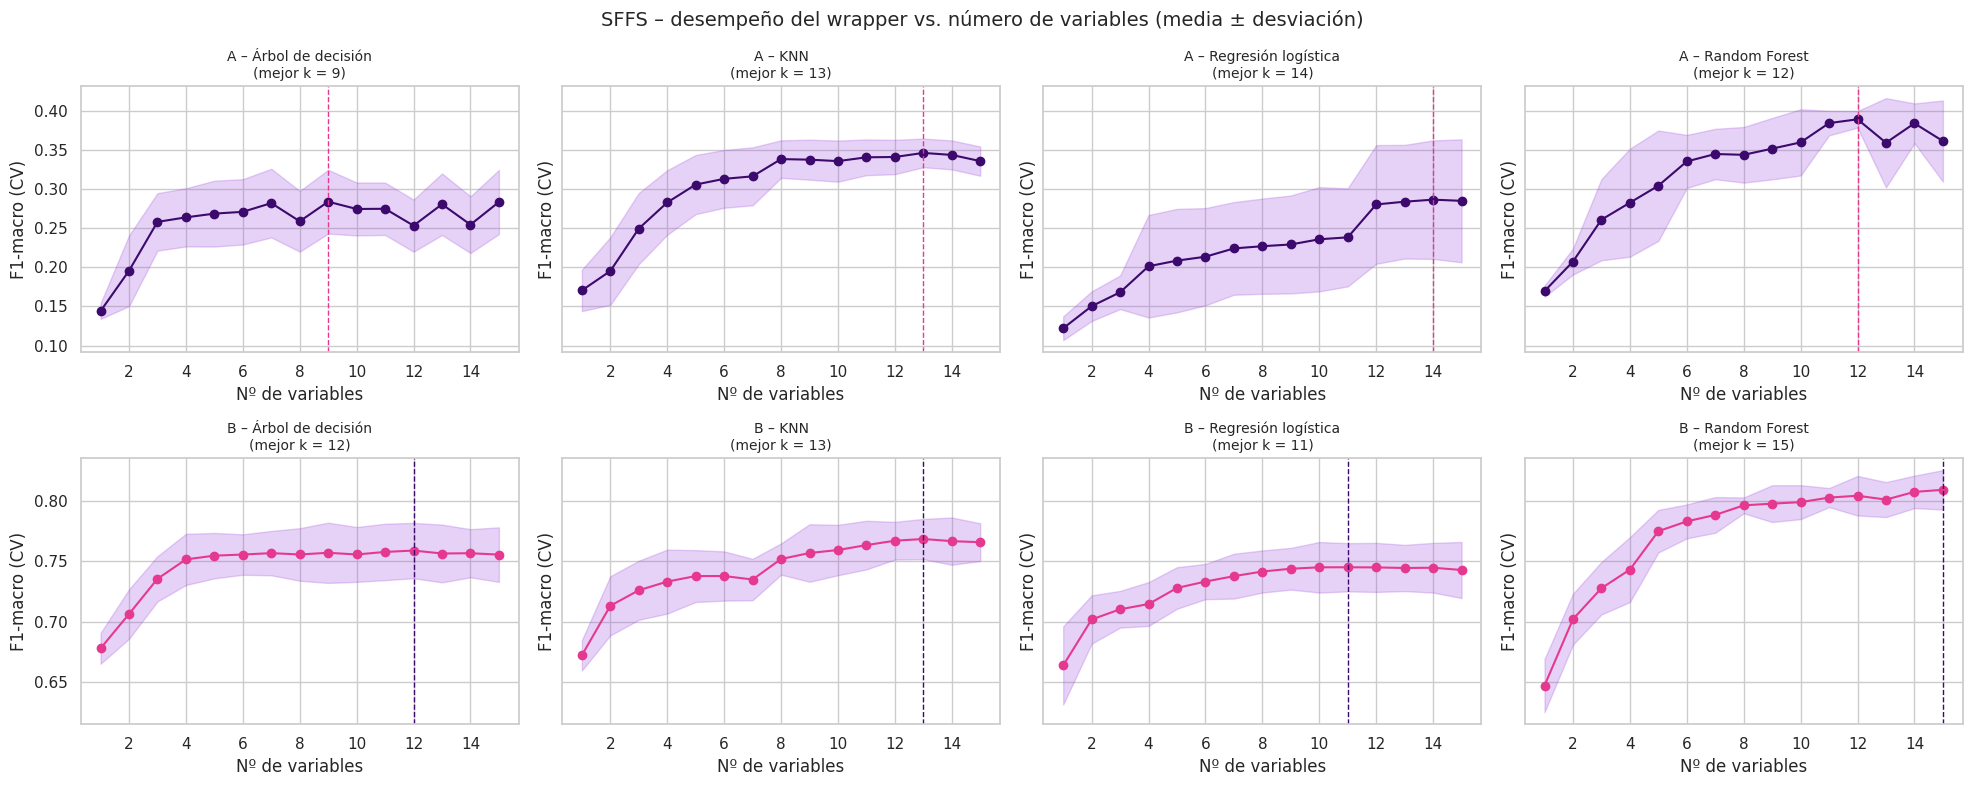

In [60]:
# Curvas del SFFS: desempeño del wrapper según el número de variables
fig, axes = plt.subplots(2, len(WRAPPERS), figsize=(5 * len(WRAPPERS), 8), sharey="row")
for i, k in enumerate(ESCENARIOS):
    for j, nombre_w in enumerate(WRAPPERS):
        md_ = sffs_res[(k, nombre_w)].get_metric_dict()
        ks = sorted(md_)
        media = np.array([md_[n]["avg_score"] for n in ks]); sd = np.array([md_[n]["std_dev"] for n in ks])
        a = axes[i, j]
        a.plot(ks, media, marker="o", color=MORADO if k == "A" else ROSADO)
        a.fill_between(ks, media - sd, media + sd, color=LILA, alpha=.25)
        kbest = len(sffs_res[(k, nombre_w)].k_feature_idx_)
        a.axvline(kbest, color=ROSADO if k == "A" else MORADO, ls="--", lw=1)
        a.set_title(f"{k} – {nombre_w}\n(mejor k = {kbest})", fontsize=10)
        a.set_xlabel("Nº de variables"); a.set_ylabel("F1-macro (CV)")
fig.suptitle("SFFS – desempeño del wrapper vs. número de variables (media ± desviación)", fontsize=14)
plt.tight_layout(); plt.show()

In [61]:
# Variables seleccionadas por cada combinación escenario–wrapper
tabla_sel = pd.DataFrame(
    [{"Escenario": k, "Wrapper": w, "Nº variables": len(s.k_feature_names_),
      "F1-macro wrapper (CV)": round(s.k_score_, 4), "Variables seleccionadas": ", ".join(s.k_feature_names_)}
     for (k, w), s in sffs_res.items()])
pd.set_option("display.max_colwidth", None)
tabla_sel

,Escenario,Wrapper,Nº variables,F1-macro wrapper (CV),Variables seleccionadas
0,A,Árbol de decisión,9,0.2836,"currentRatio, returnOnCapitalEmployed, freeCashFlowOperatingCashFlowRatio, freeCashFlowPerShare, cashPerShare, companyEquityMultiplier, Sector_Health Care, Sector_Miscellaneous, Sector_Technology"
1,A,KNN,13,0.3459,"daysOfSalesOutstanding, freeCashFlowPerShare, companyEquityMultiplier, ebitPerRevenue, enterpriseValueMultiple, operatingCashFlowSalesRatio, payablesTurnover, Sector_Basic Industries, Sector_Consumer Durables, Sector_Consumer Services, Sector_Energy, Sector_Miscellaneous, Sector_Transportation"
2,A,Regresión logística,14,0.2862,"quickRatio, cashRatio, pretaxProfitMargin, grossProfitMargin, returnOnAssets, returnOnCapitalEmployed, debtRatio, ebitPerRevenue, operatingCashFlowPerShare, operatingCashFlowSalesRatio, Sector_Consumer Non-Durables, Sector_Energy, Sector_Finance, Sector_Technology"
3,A,Random Forest,12,0.3888,"quickRatio, cashRatio, daysOfSalesOutstanding, grossProfitMargin, returnOnCapitalEmployed, operatingCashFlowPerShare, operatingCashFlowSalesRatio, payablesTurnover, Sector_Energy, Sector_Finance, Sector_Technology, Sector_Transportation"
4,B,Árbol de decisión,12,0.7587,"cashRatio, netProfitMargin, operatingCashFlowPerShare, operatingCashFlowSalesRatio, payablesTurnover, Sector_Consumer Durables, Sector_Consumer Non-Durables, Sector_Finance, Sector_Health Care, Sector_Public Utilities, Sector_Technology, Sector_Transportation"
5,B,KNN,13,0.7683,"daysOfSalesOutstanding, pretaxProfitMargin, returnOnAssets, enterpriseValueMultiple, operatingCashFlowPerShare, operatingCashFlowSalesRatio, Sector_Consumer Non-Durables, Sector_Consumer Services, Sector_Energy, Sector_Finance, Sector_Health Care, Sector_Public Utilities, Sector_Transportation"
6,B,Regresión logística,11,0.7449,"quickRatio, cashRatio, netProfitMargin, returnOnCapitalEmployed, returnOnEquity, debtRatio, freeCashFlowPerShare, operatingCashFlowPerShare, Sector_Finance, Sector_Public Utilities, Sector_Transportation"
7,B,Random Forest,15,0.8089,"quickRatio, cashRatio, daysOfSalesOutstanding, returnOnAssets, assetTurnover, fixedAssetTurnover, debtEquityRatio, freeCashFlowOperatingCashFlowRatio, enterpriseValueMultiple, operatingCashFlowPerShare, operatingCashFlowSalesRatio, payablesTurnover, Sector_Consumer Non-Durables, Sector_Consumer Services, Sector_Miscellaneous"


### 11.1 Entrenamiento de la RNA con las variables seleccionadas por cada wrapper

Para cada combinación se entrena la RNA (arquitectura base 32‑16) **solo con las variables elegidas por el SFFS** y se compara con la RNA que usa las 37 variables.

In [62]:
filas = []
rna_sffs = {}
for k, e in ESCENARIOS.items():
    filas.append({"Escenario": k, "Alternativa": "Sin selección (37 variables)", "Nº variables": X_all.shape[1],
                  "F1-macro ± desv": fmt(base[k]), "Accuracy": base[k]["acc"], "Bal. accuracy": base[k]["bacc"],
                  "F1-macro": base[k]["f1"], "Tiempo RNA (s)": base[k]["tiempo_s"]})
    for nombre_w in WRAPPERS:
        cols = list(sffs_res[(k, nombre_w)].k_feature_names_)
        r = evaluar_rna(X_df[cols].values, e["y"], e["n_clases"])
        rna_sffs[(k, nombre_w)] = r
        filas.append({"Escenario": k, "Alternativa": f"SFFS + {nombre_w}", "Nº variables": len(cols),
                      "F1-macro ± desv": fmt(r), "Accuracy": r["acc"], "Bal. accuracy": r["bacc"],
                      "F1-macro": r["f1"], "Tiempo RNA (s)": r["tiempo_s"]})
results_sffs = pd.DataFrame(filas)
for k, e in ESCENARIOS.items():
    print(e["nombre"])
    display(results_sffs[results_sffs["Escenario"] == k].sort_values("F1-macro", ascending=False).round(4))

A – Base original (10 clases)


,Escenario,Alternativa,Nº variables,F1-macro ± desv,Accuracy,Bal. accuracy,F1-macro,Tiempo RNA (s)
0,A,Sin selección (37 variables),37,0.1953 +/- 0.0217,0.4194,0.1971,0.1953,37.8274
3,A,SFFS + Regresión logística,14,0.1773 +/- 0.0170,0.4022,0.1825,0.1773,35.0980
4,A,SFFS + Random Forest,12,0.1743 +/- 0.0308,0.3933,0.1778,0.1743,39.7240
1,A,SFFS + Árbol de decisión,9,0.1659 +/- 0.0151,0.3790,0.1718,0.1659,48.6978
2,A,SFFS + KNN,13,0.1484 +/- 0.0201,0.3622,0.1576,0.1484,43.5568


B – Base agrupada (2 clases)


,Escenario,Alternativa,Nº variables,F1-macro ± desv,Accuracy,Bal. accuracy,F1-macro,Tiempo RNA (s)
5,B,Sin selección (37 variables),37,0.7379 +/- 0.0246,0.7516,0.7340,0.7379,28.0135
8,B,SFFS + Regresión logística,11,0.7315 +/- 0.0256,0.7491,0.7277,0.7315,32.3441
9,B,SFFS + Random Forest,15,0.7139 +/- 0.0365,0.7324,0.7111,0.7139,31.5537
7,B,SFFS + KNN,13,0.7063 +/- 0.0331,0.7289,0.7034,0.7063,26.2571
6,B,SFFS + Árbol de decisión,12,0.7026 +/- 0.0248,0.7255,0.7001,0.7026,37.0774


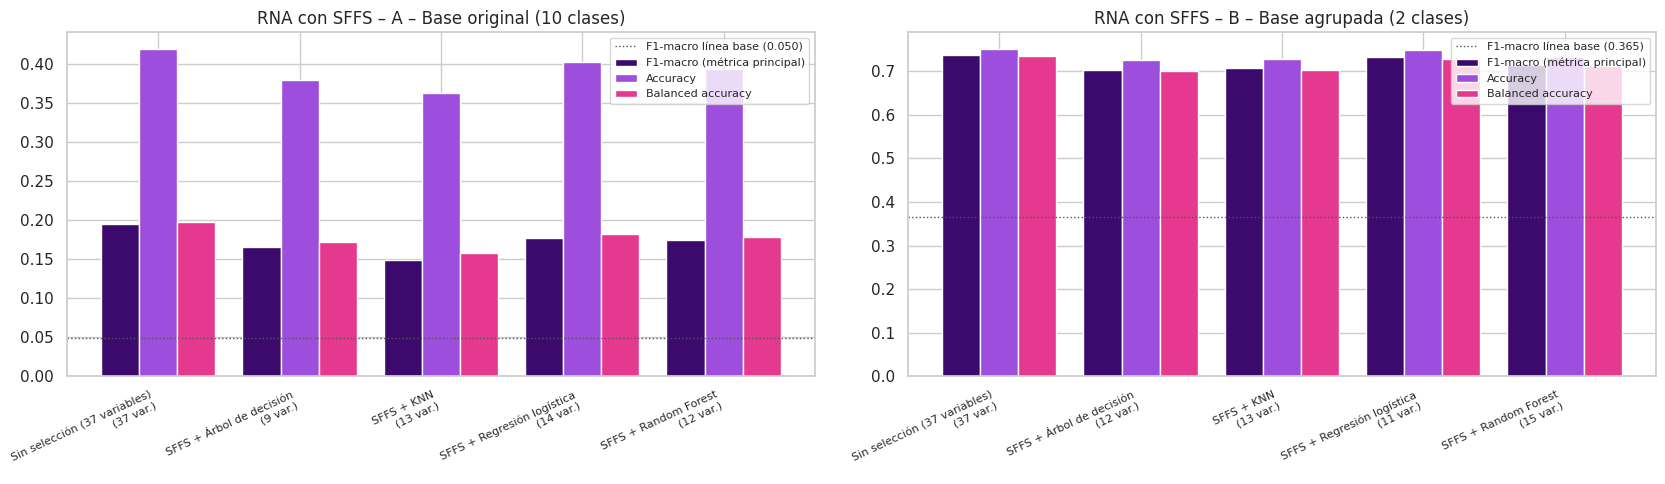

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for a, k in zip(axes, ESCENARIOS):
    d = results_sffs[results_sffs["Escenario"] == k].reset_index(drop=True)
    x = np.arange(len(d)); w = .27
    a.bar(x - w, d["F1-macro"], w, color=MORADO, label="F1-macro (métrica principal)")
    a.bar(x, d["Accuracy"], w, color=LILA, label="Accuracy")
    a.bar(x + w, d["Bal. accuracy"], w, color=ROSADO, label="Balanced accuracy")
    linea = f1_linea_base(ESCENARIOS[k]["y"])
    a.axhline(linea, color="#555555", ls=":", lw=1, label=f"F1-macro línea base ({linea:.3f})")
    a.set_xticks(x); a.set_xticklabels([f"{t}\n({n} var.)" for t, n in zip(d["Alternativa"], d["Nº variables"])],
                                       rotation=25, ha="right", fontsize=8)
    a.set_title(f"RNA con SFFS – {ESCENARIOS[k]['nombre']}"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 11.2 Ajuste de la arquitectura de la RNA con el mejor subconjunto

Con el mejor subconjunto de cada escenario se prueban varias arquitecturas, igual que en la tabla de la práctica (número de capas y neuronas).

In [64]:
ARQUITECTURAS = [(16,), (32,), (32, 16), (64, 32)]
mejor_sffs, filas_arq = {}, []
for k, e in ESCENARIOS.items():
    d = results_sffs[(results_sffs["Escenario"] == k) & (results_sffs["Alternativa"] != "Sin selección (37 variables)")]
    w_best = d.sort_values("F1-macro", ascending=False).iloc[0]["Alternativa"].replace("SFFS + ", "")
    cols = list(sffs_res[(k, w_best)].k_feature_names_)
    for capas in ARQUITECTURAS:
        r = evaluar_rna(X_df[cols].values, e["y"], e["n_clases"], capas=capas)
        filas_arq.append({"Escenario": k, "Wrapper": w_best, "Capas ocultas": str(capas),
                          "Nº variables": len(cols), "F1-macro ± desv": fmt(r), "Accuracy": r["acc"],
                          "Bal. accuracy": r["bacc"], "F1-macro": r["f1"], "Tiempo (s)": r["tiempo_s"], "_r": r})
tabla_arq = pd.DataFrame(filas_arq)
for k, e in ESCENARIOS.items():
    d = tabla_arq[tabla_arq["Escenario"] == k].sort_values("F1-macro", ascending=False)
    fila = d.iloc[0]
    mejor_sffs[k] = {"wrapper": fila["Wrapper"], "capas": fila["Capas ocultas"],
                     "variables": list(sffs_res[(k, fila["Wrapper"])].k_feature_names_), "r": fila["_r"]}
    print(e["nombre"], "– mejor wrapper:", fila["Wrapper"])
    display(d.drop(columns="_r").round(4))
    print(f"==> Mejor configuración SFFS: wrapper {fila['Wrapper']}, capas {fila['Capas ocultas']}, "
          f"{fila['Nº variables']} variables, F1-macro {fila['F1-macro ± desv']}\n")

A – Base original (10 clases) – mejor wrapper: Regresión logística


,Escenario,Wrapper,Capas ocultas,Nº variables,F1-macro ± desv,Accuracy,Bal. accuracy,F1-macro,Tiempo (s)
1,A,Regresión logística,"(32,)",14,0.1962 +/- 0.0260,0.4076,0.1939,0.1962,39.2595
3,A,Regresión logística,"(64, 32)",14,0.1797 +/- 0.0094,0.4032,0.1839,0.1797,27.1219
0,A,Regresión logística,"(16,)",14,0.1784 +/- 0.0185,0.3938,0.1819,0.1784,49.3167
2,A,Regresión logística,"(32, 16)",14,0.1773 +/- 0.0170,0.4022,0.1825,0.1773,36.0477


==> Mejor configuración SFFS: wrapper Regresión logística, capas (32,), 14 variables, F1-macro 0.1962 +/- 0.0260

B – Base agrupada (2 clases) – mejor wrapper: Regresión logística


,Escenario,Wrapper,Capas ocultas,Nº variables,F1-macro ± desv,Accuracy,Bal. accuracy,F1-macro,Tiempo (s)
6,B,Regresión logística,"(32, 16)",11,0.7315 +/- 0.0256,0.7491,0.7277,0.7315,32.9752
7,B,Regresión logística,"(64, 32)",11,0.7226 +/- 0.0184,0.7388,0.7188,0.7226,23.4504
5,B,Regresión logística,"(32,)",11,0.7050 +/- 0.0534,0.7196,0.7065,0.7050,25.1004
4,B,Regresión logística,"(16,)",11,0.6648 +/- 0.0796,0.6811,0.6772,0.6648,26.4680


==> Mejor configuración SFFS: wrapper Regresión logística, capas (32, 16), 11 variables, F1-macro 0.7315 +/- 0.0256



**Análisis del punto 1:**
- La tabla 11.1 compara las cuatro funciones *wrapper*. Cada wrapper "ve" la importancia de las variables de forma distinta, así que eligen subconjuntos diferentes: los árboles y el Random Forest favorecen variables con umbrales claros, la regresión logística las de efecto lineal y KNN las que forman vecindarios compactos. Lo importante es **cómo le va a la RNA** con cada subconjunto, no el puntaje del wrapper.
- La selección es útil si la RNA con pocas variables **iguala o supera** a la RNA con las 37 variables: se obtiene un modelo más simple, rápido e interpretable, con menos ruido y menos riesgo de sobreajuste.
- **Escenario A vs. B:** el F1‑macro debe compararse con el de un clasificador trivial que siempre predice la clase mayoritaria: ≈ 0,05 en el escenario A (solo acierta BBB, que es 1 de 10 clases) y ≈ 0,36 en el B. En el escenario A el F1‑macro siempre queda muy por debajo de la *accuracy*, porque las clases AAA, CC, C y D (≤ 7 muestras) casi nunca se aciertan, y su F1 = 0 cuenta igual que el de las clases grandes.
- **Precaución:** el SFFS se ejecutó con todos los datos (con validación cruzada interna), así que los resultados de la RNA con esas variables pueden ser algo optimistas. Una validación anidada sería más rigurosa, pero multiplicaría el tiempo de cómputo.

## 12. Punto 2 – Variables más importantes (discriminantes)

Para identificar las variables más discriminantes se combinan tres evidencias de los resultados del SFFS:
1. **Frecuencia de selección:** en cuántas de las 8 ejecuciones (4 wrappers × 2 escenarios) fue elegida cada variable. Las que aparecen con casi todos los wrappers son importantes sin importar el modelo.
2. **Orden de entrada:** en qué paso del SFFS entró la variable en el mejor wrapper. Las primeras son las que, por sí solas, más mejoran la clasificación.
3. **Ganancia marginal:** cuánto sube el **F1‑macro** del wrapper cuando entra cada variable.

In [65]:
# 1) Frecuencia de selección
frec_sel = pd.DataFrame(0, index=features_modelo, columns=list(ESCENARIOS))
for (k, w), s in sffs_res.items():
    for v in s.k_feature_names_:
        frec_sel.loc[v, k] += 1
frec_sel["Total (de 8)"] = frec_sel.sum(axis=1)
frec_sel = frec_sel.sort_values(["Total (de 8)", "A"], ascending=False)

def orden_entrada(sfs_obj):
    # Paso del SFFS en que aparece por primera vez cada variable y ganancia de F1-macro en ese paso
    md_ = sfs_obj.get_metric_dict(); prev, prev_score, res = set(), 0.0, {}
    for n in sorted(md_):
        actual = set(md_[n]["feature_names"])
        for v in actual - prev:
            if v not in res:
                res[v] = (n, md_[n]["avg_score"] - prev_score)
        prev, prev_score = actual, md_[n]["avg_score"]
    return res

for k in ESCENARIOS:
    oe = orden_entrada(sffs_res[(k, mejor_sffs[k]["wrapper"])])
    frec_sel[f"Paso de entrada {k} ({mejor_sffs[k]['wrapper']})"] = [oe.get(v, (np.nan, np.nan))[0] for v in frec_sel.index]
    frec_sel[f"Ganancia F1-macro {k}"] = [oe.get(v, (np.nan, np.nan))[1] for v in frec_sel.index]
frec_sel.round(4)

,A,B,Total (de 8),Paso de entrada A (Regresión logística),Ganancia F1-macro A,Paso de entrada B (Regresión logística),Ganancia F1-macro B
operatingCashFlowSalesRatio,3,3,6,10.0000,0.0066,NaN,NaN
operatingCashFlowPerShare,2,4,6,4.0000,0.0332,2.0000,0.0380
cashRatio,2,3,5,12.0000,0.0420,8.0000,0.0038
Sector_Finance,2,3,5,5.0000,0.0072,7.0000,0.0045
Sector_Transportation,2,3,5,NaN,NaN,11.0000,0.0000
returnOnCapitalEmployed,3,1,4,1.0000,0.1220,5.0000,0.0133
Sector_Energy,3,1,4,14.0000,0.0026,NaN,NaN
Sector_Technology,3,1,4,11.0000,0.0025,NaN,NaN
quickRatio,2,2,4,3.0000,0.0177,6.0000,0.0053
daysOfSalesOutstanding,2,2,4,NaN,NaN,NaN,NaN


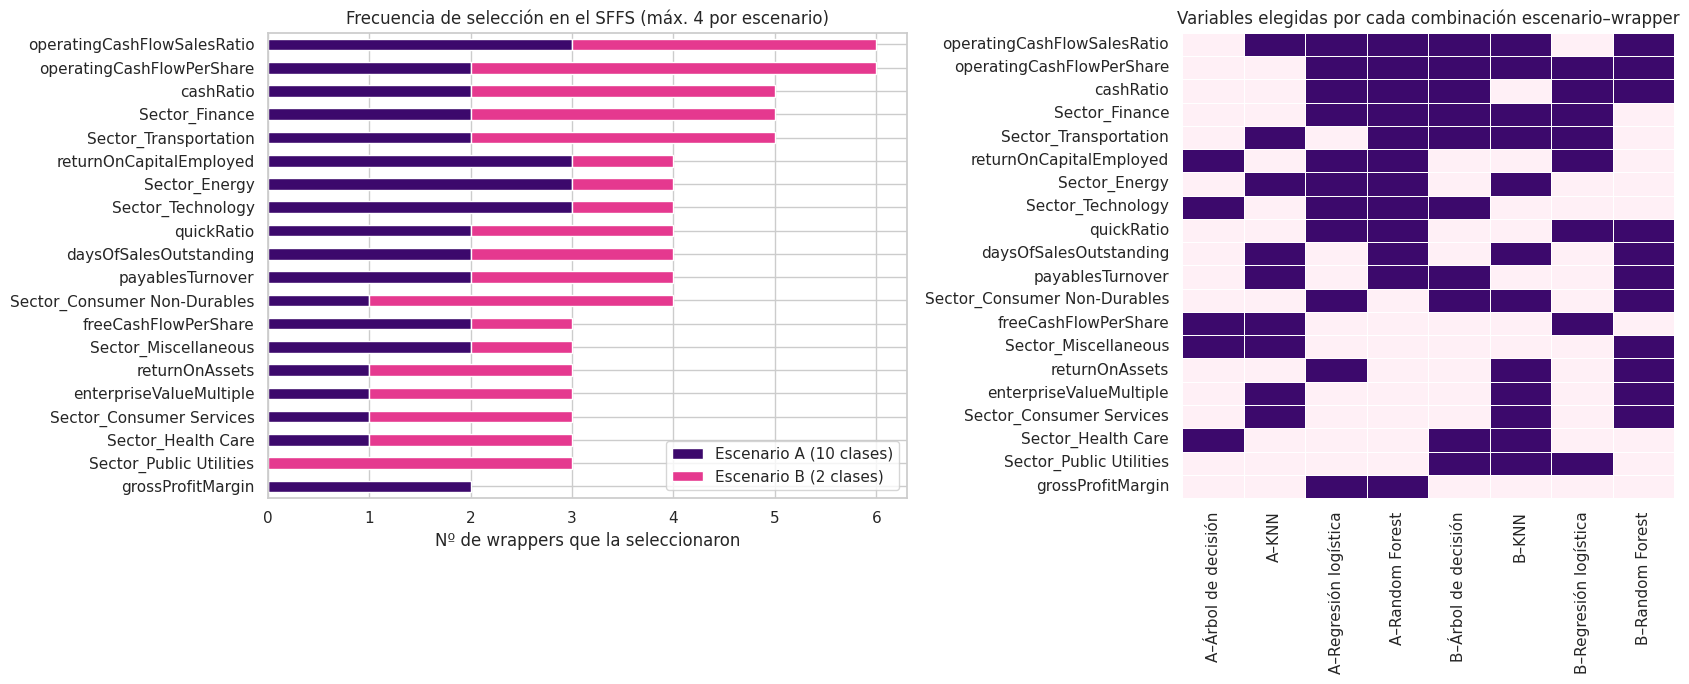

Variables seleccionadas en al menos 5 de las 8 ejecuciones (núcleo discriminante):
['operatingCashFlowSalesRatio', 'operatingCashFlowPerShare', 'cashRatio', 'Sector_Finance', 'Sector_Transportation']


In [66]:
top = frec_sel[frec_sel["Total (de 8)"] > 0].head(20)
fig, ax = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1.3, 1]})
top[["A", "B"]].rename(columns={"A": "Escenario A (10 clases)", "B": "Escenario B (2 clases)"}).plot.barh(
    stacked=True, ax=ax[0], color=[MORADO, ROSADO])
ax[0].invert_yaxis(); ax[0].set_xlabel("Nº de wrappers que la seleccionaron")
ax[0].set_title("Frecuencia de selección en el SFFS (máx. 4 por escenario)")

mat = pd.DataFrame(0, index=top.index, columns=[f"{k}–{w}" for (k, w) in sffs_res])
for (k, w), s in sffs_res.items():
    mat.loc[[v for v in s.k_feature_names_ if v in mat.index], f"{k}–{w}"] = 1
sns.heatmap(mat, cmap=CMAP_MR_CLARO, cbar=False, linewidths=.5, ax=ax[1])
ax[1].set_title("Variables elegidas por cada combinación escenario–wrapper"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

nucleo = frec_sel[frec_sel["Total (de 8)"] >= 5].index.tolist()
print("Variables seleccionadas en al menos 5 de las 8 ejecuciones (núcleo discriminante):")
print(nucleo if nucleo else "(ninguna supera 5; ver el ranking de la tabla)")

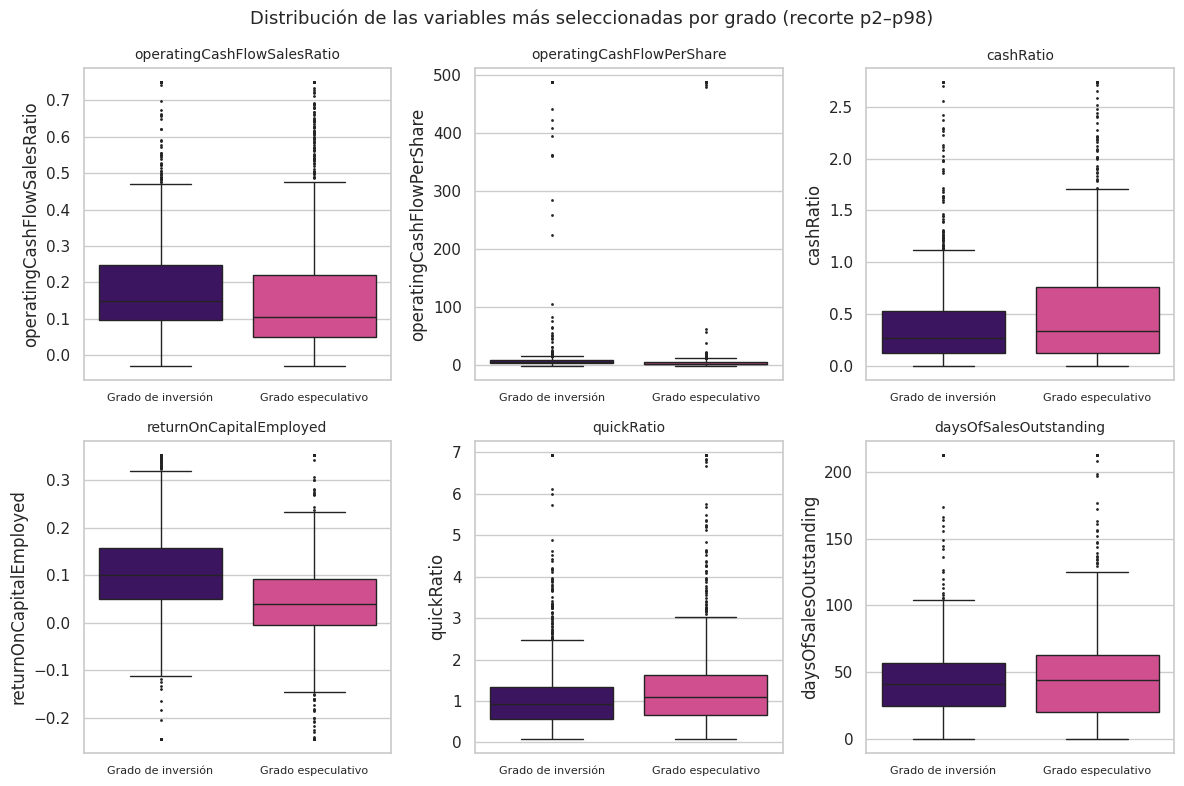

,rho_vs_Rating (A),rho_vs_Grado (B),mediana_inversion,mediana_especulativo
variable,,,,
operatingCashFlowSalesRatio,-0.2094,-0.1792,0.1484,0.1029
operatingCashFlowPerShare,-0.3916,-0.3537,5.3523,2.7186
cashRatio,0.0867,0.1015,0.2739,0.3382
returnOnCapitalEmployed,-0.4431,-0.3801,0.0997,0.0397
quickRatio,0.1176,0.1275,0.9161,1.0947
daysOfSalesOutstanding,0.0343,0.0392,41.2634,43.7469


In [67]:
# Relación de las variables del núcleo con la salida, en escala original (mediana por grado)
top_vars = [v for v in frec_sel.index[:10] if v in features]   # solo indicadores financieros
if top_vars:
    fig, axes = plt.subplots(2, (len(top_vars) + 1) // 2, figsize=(4 * ((len(top_vars) + 1) // 2), 8))
    for a, v in zip(np.ravel(axes), top_vars):
        lo, hi = df_modelo[v].quantile([0.02, 0.98])
        sns.boxplot(x=df_modelo["Grado"], y=df_modelo[v].clip(lo, hi), palette=[MORADO, ROSADO],
                    ax=a, fliersize=1)
        a.set_title(v, fontsize=10); a.set_xlabel(""); a.tick_params(axis="x", labelsize=8)
    for a in np.ravel(axes)[len(top_vars):]:
        a.axis("off")
    plt.suptitle("Distribución de las variables más seleccionadas por grado (recorte p2–p98)", fontsize=13)
    plt.tight_layout(); plt.show()
    display(discrim.loc[top_vars, ["rho_vs_Rating (A)", "rho_vs_Grado (B)",
                                   "mediana_inversion", "mediana_especulativo"]].round(4))

**Interpretación de las variables más discriminantes:**

Revise el ranking de la tabla anterior. Lo esperable, de acuerdo con el EDA (sección 3.7) y la teoría de riesgo de crédito, es que el núcleo esté formado por variables de estos grupos:

- **Rentabilidad** (`returnOnCapitalEmployed`, `returnOnAssets`, `netProfitMargin`, `pretaxProfitMargin`, `returnOnEquity`). Fueron las más correlacionadas con el rating en el EDA (ρ ≈ −0,44 para ROCE y ROA). Una empresa que genera más utilidad por cada peso de activos o de capital tiene más capacidad de pagar su deuda, y por eso recibe mejor calificación.
- **Flujo de caja** (`operatingCashFlowPerShare`, `freeCashFlowPerShare`, `operatingCashFlowSalesRatio`). La deuda se paga con caja, no con utilidades contables. Un flujo operativo alto y estable es una de las variables que más miran las agencias.
- **Endeudamiento** (`debtRatio`, `debtEquityRatio`). Más apalancamiento implica más obligaciones fijas y mayor probabilidad de *default*; es la principal variable con relación **positiva** con un peor rating.
- **Sector** (*dummies* como `Sector_Public Utilities`, `Sector_Energy` o `Sector_Technology`). El sector cambia el nivel de riesgo "de partida": las *utilities* son reguladas y estables (más deuda tolerada con buena calificación), mientras que *Energy* es volátil por los precios del petróleo.
- **Variables redundantes:** cuando un par está muy correlacionado (p. ej. `debtEquityRatio` y `companyEquityMultiplier`, ρ = 0,99, o `pretaxProfitMargin` y `ebitPerRevenue`, ρ = 0,98), el SFFS normalmente **elige solo una de las dos**, porque la segunda no aporta información nueva. Esta es la forma correcta de manejar la multicolinealidad que se dejó pendiente en la Parte 1.
- **Variables poco útiles:** las de liquidez (`currentRatio`, `quickRatio`) y eficiencia (`assetTurnover`, `payablesTurnover`) tuvieron correlaciones casi nulas con el rating en el EDA, por lo que se espera que el SFFS las seleccione poco.

> Ajuste este párrafo a sus resultados: confirme cuáles de estas variables aparecen en el **núcleo discriminante** que imprime la celda anterior y en qué orden entraron.

## 13. Punto 3 – Reducción de dimensión con PCA + RNA

**PCA (Análisis de Componentes Principales)** es un método de **extracción** de características **no supervisado**: construye nuevas variables (componentes) que son combinaciones lineales de las originales, no correlacionadas entre sí y ordenadas por la varianza que explican. **No usa la variable de salida**, así que maximiza la varianza retenida, no la separación entre clases.

Se usa la implementación de **mlxtend** (`PrincipalComponentAnalysis`) y se prueban distintas dimensiones *d*. En cada *fold* el PCA se ajusta solo con los datos de entrenamiento.

Componentes necesarias para explicar: {'80 %': 11, '90 %': 15, '95 %': 19}


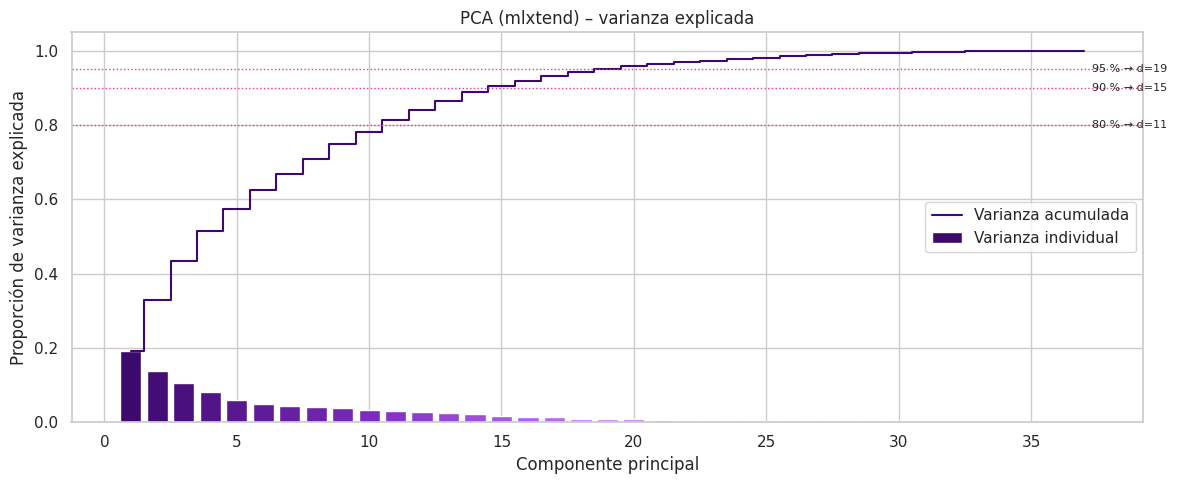

In [68]:
# Varianza explicada (PCA ajustado con todos los datos, solo para describir)
pca_full = PrincipalComponentAnalysis(n_components=X_all.shape[1], solver="svd")
pca_full.fit(X_all)
var_exp = np.real(pca_full.e_vals_normalized_)
var_acum = np.cumsum(var_exp)
umbrales = {p: int(np.argmax(var_acum >= p) + 1) for p in (0.80, 0.90, 0.95)}
print("Componentes necesarias para explicar:", {f"{int(p*100)} %": n for p, n in umbrales.items()})

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(1, len(var_exp) + 1), var_exp, color=paleta(len(var_exp)), label="Varianza individual")
ax.step(range(1, len(var_acum) + 1), var_acum, where="mid", color=MORADO, label="Varianza acumulada")
for p, n in umbrales.items():
    ax.axhline(p, color=ROSADO, ls=":", lw=1); ax.text(len(var_exp) + .3, p, f"{int(p*100)} % → d={n}", va="center", fontsize=8)
ax.set_xlabel("Componente principal"); ax.set_ylabel("Proporción de varianza explicada")
ax.set_title("PCA (mlxtend) – varianza explicada"); ax.legend(loc="center right"); plt.tight_layout(); plt.show()

In [69]:
D_PCA = sorted(set([2, 5, 10, 15, 20, 25, 30, X_all.shape[1]] + list(umbrales.values())))

def reductor_pca(d):
    def _f(Xtr, ytr):
        return PrincipalComponentAnalysis(n_components=d, solver="svd").fit(Xtr)
    return _f

filas, rna_pca = [], {}
for k, e in ESCENARIOS.items():
    for d in D_PCA:
        r = evaluar_rna(X_all, e["y"], e["n_clases"], reductor=reductor_pca(d))
        rna_pca[(k, d)] = r
        filas.append({"Escenario": k, "d": d, "% varianza (aprox.)": round(var_acum[d - 1] * 100, 1),
                      "F1-macro ± desv": fmt(r), "F1-macro": r["f1"], "f1_std": r["f1_std"],
                      "Accuracy": r["acc"], "Bal. accuracy": r["bacc"], "Tiempo (s)": r["tiempo_s"]})
    print(f"Escenario {k} terminado")
results_pca = pd.DataFrame(filas)
results_pca.round(4)

Escenario A terminado
Escenario B terminado


,Escenario,d,% varianza (aprox.),F1-macro ± desv,F1-macro,f1_std,Accuracy,Bal. accuracy,Tiempo (s)
0,A,2,32.8000,0.1255 +/- 0.0133,0.1255,0.0133,0.3598,0.1458,37.1191
1,A,5,57.6000,0.1572 +/- 0.0209,0.1572,0.0209,0.3751,0.1648,47.8907
2,A,10,78.2000,0.1718 +/- 0.0236,0.1718,0.0236,0.3903,0.1768,44.3499
3,A,11,81.3000,0.1835 +/- 0.0154,0.1835,0.0154,0.4046,0.1867,46.7676
4,A,15,90.5000,0.1819 +/- 0.0183,0.1819,0.0183,0.4105,0.1873,44.3434
5,A,19,95.2000,0.2003 +/- 0.0206,0.2003,0.0206,0.4278,0.2027,51.2734
6,A,20,95.9000,0.1986 +/- 0.0181,0.1986,0.0181,0.4273,0.2001,40.7506
7,A,25,98.2000,0.1976 +/- 0.0213,0.1976,0.0213,0.4308,0.2005,41.9054
8,A,30,99.5000,0.2067 +/- 0.0155,0.2067,0.0155,0.4372,0.2087,39.0007
9,A,37,100.0000,0.1993 +/- 0.0223,0.1993,0.0223,0.4347,0.2031,42.1562


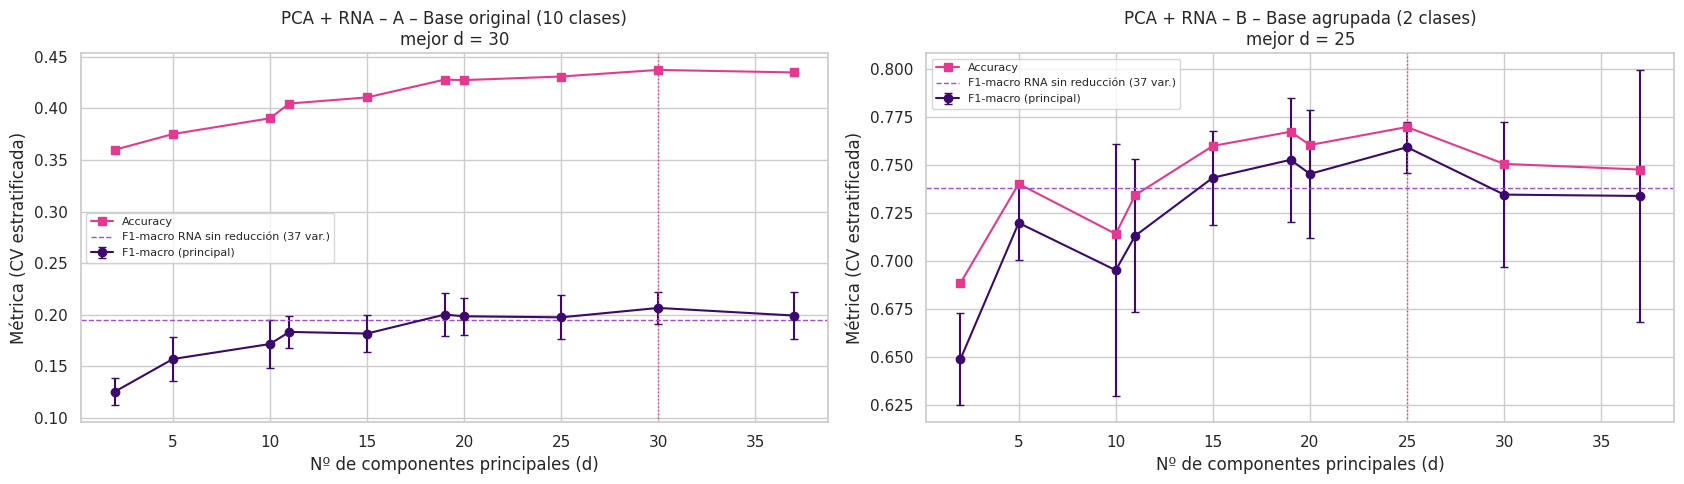

A – Base original (10 clases): mejor dimensión PCA d = 30 -> F1-macro 0.2067 +/- 0.0155 (sin reducción: 0.1953 +/- 0.0217)
B – Base agrupada (2 clases): mejor dimensión PCA d = 25 -> F1-macro 0.7593 +/- 0.0132 (sin reducción: 0.7379 +/- 0.0246)


In [70]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
mejor_pca = {}
for a, k in zip(axes, ESCENARIOS):
    d = results_pca[results_pca["Escenario"] == k]
    a.errorbar(d["d"], d["F1-macro"], yerr=d["f1_std"], marker="o", color=MORADO, capsize=3, label="F1-macro (principal)")
    a.plot(d["d"], d["Accuracy"], marker="s", color=ROSADO, label="Accuracy")
    a.axhline(base[k]["f1"], color=LILA, ls="--", lw=1, label="F1-macro RNA sin reducción (37 var.)")
    best = d.sort_values("F1-macro", ascending=False).iloc[0]
    mejor_pca[k] = {"d": int(best["d"]), "r": rna_pca[(k, int(best["d"]))]}
    a.axvline(best["d"], color=ROSADO, ls=":", lw=1)
    a.set_title(f"PCA + RNA – {ESCENARIOS[k]['nombre']}\nmejor d = {int(best['d'])}")
    a.set_xlabel("Nº de componentes principales (d)"); a.set_ylabel("Métrica (CV estratificada)"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

for k, e in ESCENARIOS.items():
    print(f"{e['nombre']}: mejor dimensión PCA d = {mejor_pca[k]['d']} "
          f"-> F1-macro {fmt(mejor_pca[k]['r'])} (sin reducción: {fmt(base[k])})")

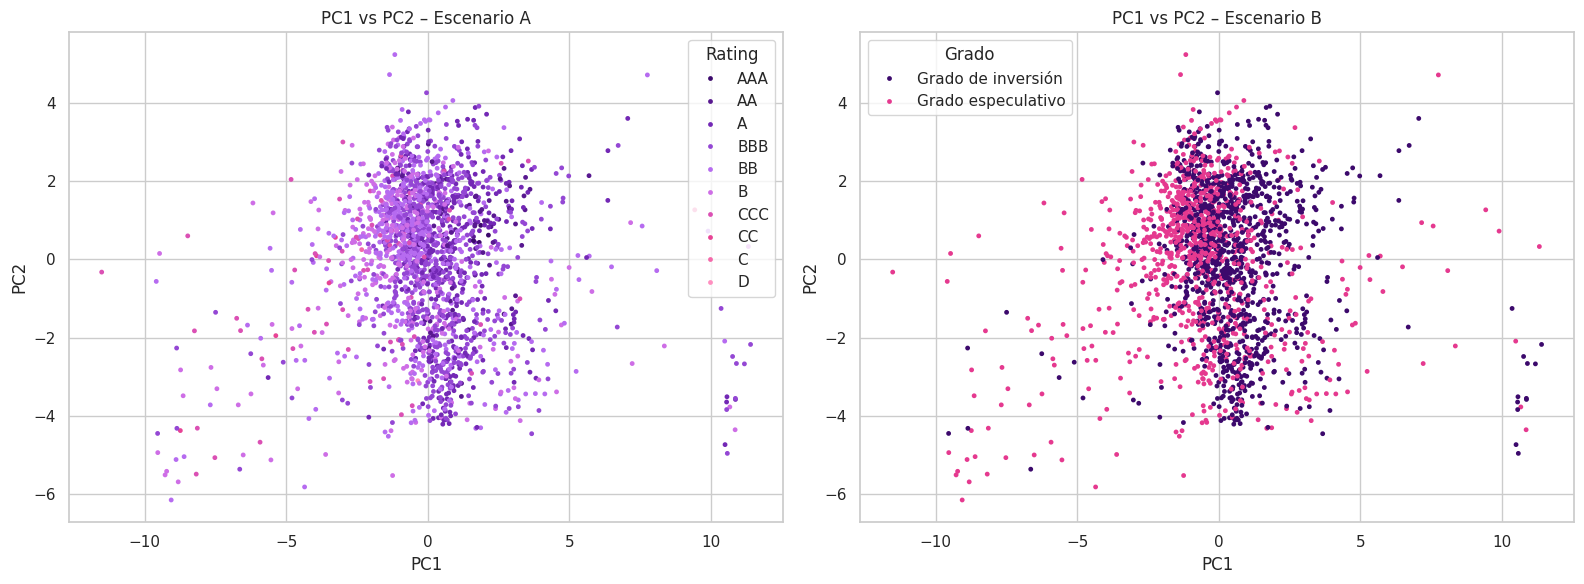

In [71]:
# Visualización: primeras 2 componentes principales coloreadas por clase
Z = PrincipalComponentAnalysis(n_components=2, solver="svd").fit(X_all).transform(X_all)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df_modelo["Rating"], palette=paleta(10), s=12, linewidth=0, ax=ax[0])
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df_modelo["Grado"], palette=[MORADO, ROSADO], s=12, linewidth=0, ax=ax[1])
ax[0].set_title("PC1 vs PC2 – Escenario A"); ax[1].set_title("PC1 vs PC2 – Escenario B")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Análisis del punto 3 – ¿con qué dimensión se obtienen los mejores resultados?**
- La celda anterior imprime la **dimensión óptima *d*** de cada escenario (la de mayor **F1‑macro** promedio en la validación cruzada estratificada).
- Con muy pocas componentes (*d* = 1–3) la RNA pierde información: aunque PC1 y PC2 concentran la mayor varianza, las clases se ven **solapadas** en el gráfico, porque la dirección de mayor varianza no es la que mejor separa las calificaciones.
- El desempeño mejora al aumentar *d* y luego se **estabiliza** alrededor de la dimensión que explica el 90–95 % de la varianza. Por encima de ese punto las componentes extra casi no aportan (o aportan ruido).
- Si la mejor *d* es cercana a 37, PCA no reduce mucho la dimensión sin perder desempeño. Esto pasa porque las variables, después de Yeo‑Johnson, están poco correlacionadas en promedio (ver la curva de varianza: no hay pocas componentes que dominen).
- Compare la mejor *d* con la línea punteada (RNA con las 37 variables). Si quedan cerca, PCA permite usar una red con menos entradas sin perder eficiencia.

## 14. Punto 4 – Reducción de dimensión con LDA (mlxtend) + RNA

**LDA (Análisis Discriminante Lineal)** también es un método de **extracción**, pero **supervisado**: busca las proyecciones que **maximizan la separación entre clases** respecto a la dispersión dentro de cada clase (criterio de Fisher).

- **Escenario A (10 clases):** *d* = 1 … **9**.
- **Escenario B (2 clases):** **solo *d* = 1** (un único eje discriminante).

Se usa `LinearDiscriminantAnalysis` de **mlxtend** (`mlxtend.feature_extraction`) con el parámetro `n_discriminants = d`, ajustado **dentro de cada *fold*** de la validación cruzada estratificada. Para que funcione correctamente con esta base se hacen cuatro ajustes:

1. **Se quita una *dummy* de `Sector` (categoría de referencia).** mlxtend calcula $S_W^{-1}$ con una inversa directa (`np.linalg.inv`). Con las 12 *dummies* la matriz $S_W$ es **singular**, porque las *dummies* suman siempre 1. Quitando una (equivale a `drop_first`) no se pierde información: el sector omitido queda representado cuando todas las demás valen 0. La entrada al LDA queda de **36 variables**.
2. **Las etiquetas se re‑codifican como 0, 1, …, C−1 dentro de cada *fold*.** mlxtend calcula la media de las clases 0 … máx(y). En el escenario A, la clase **D tiene una sola muestra**: en el *fold* donde queda en prueba, el entrenamiento solo tiene 9 clases. Allí *d* se limita a 8.
3. **Se corrige el cálculo de $S_B$.** En la versión de mlxtend, el peso de cada clase en $S_B$ se cuenta con `y == i + 1`, es decir, supone que las etiquetas empiezan en 1. Con etiquetas que empiezan en 0, cada media quedaría ponderada con el tamaño de la clase siguiente. Se crea una subclase que solo reemplaza ese método por la fórmula correcta: $S_B=\sum_i n_i(\mu_i-\mu)(\mu_i-\mu)^T$.
4. **Se toma la parte real de los vectores propios.** $S_W^{-1}S_B$ no es simétrica, y `np.linalg.eig` puede devolver números complejos con parte imaginaria ≈ 0.

Categoría de referencia eliminada: Sector_Transportation  ->  entrada LDA: 36 variables
Rango de S_W con las 37 variables vs. 36: 36 / 37   |   36 / 36


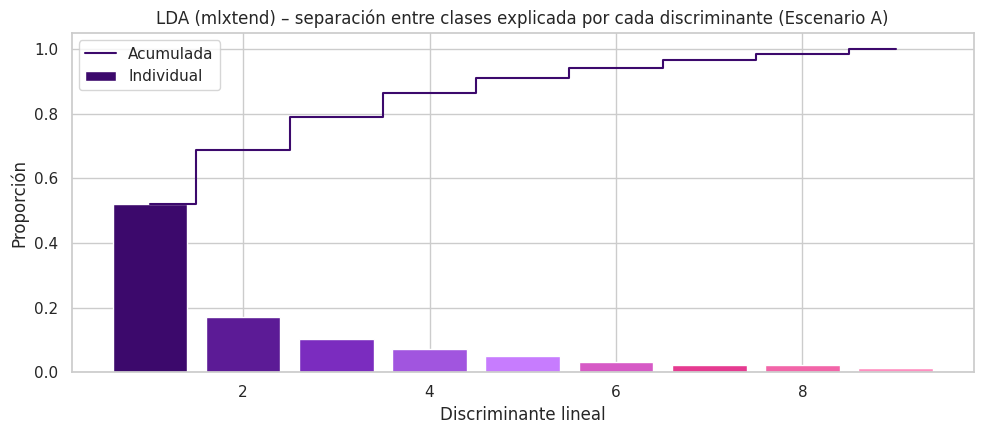

Escenario A – discriminabilidad explicada: [0.519  0.1697 0.102  0.0718 0.0488 0.0303 0.0235 0.0209 0.014 ]
Escenario B – discriminabilidad explicada: [1.] (un solo eje)


In [72]:
from mlxtend.feature_extraction import LinearDiscriminantAnalysis as LDA_mlxtend
from sklearn.preprocessing import LabelEncoder

class LDA_mlx(LDA_mlxtend):
    # LDA de mlxtend con dos correcciones: S_B con etiquetas 0..C-1 y parte real de los vectores propios

    def _between_scatter(self, X, y, mean_vectors):
        # S_B = sum_i n_i (mu_i - mu)(mu_i - mu)^T   (mlxtend original usaba y == i + 1)
        mu = np.mean(X, axis=0).reshape(-1, 1)
        S_B = np.zeros((X.shape[1], X.shape[1]))
        for i, mv in enumerate(mean_vectors):
            n_i = np.sum(y == i)
            diff = mv.reshape(-1, 1) - mu
            S_B += n_i * diff.dot(diff.T)
        return S_B

    def fit(self, X, y, n_classes=None):
        y = LabelEncoder().fit_transform(y)          # clases consecutivas 0..C'-1 en este fold
        super().fit(np.asarray(X, dtype=float), y)
        self.e_vals_ = np.real(self.e_vals_)
        self.w_ = np.real(self.w_)
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float).dot(self.w_)

# Entrada del LDA: 25 indicadores + 11 dummies (se quita la categoría de referencia de Sector)
dummy_ref = [c for c in X_df.columns if c.startswith("Sector_")][-1]
X_lda = X_df.drop(columns=[dummy_ref]).values.astype(float)
print(f"Categoría de referencia eliminada: {dummy_ref}  ->  entrada LDA: {X_lda.shape[1]} variables")
print("Rango de S_W con las 37 variables vs. 36:",
      np.linalg.matrix_rank(np.cov(X_all.T)), "/", X_all.shape[1], "  |  ",
      np.linalg.matrix_rank(np.cov(X_lda.T)), "/", X_lda.shape[1])

def reductor_lda(d):
    def _f(Xtr, ytr):
        d_eff = min(d, len(np.unique(ytr)) - 1, Xtr.shape[1])   # máximo C-1 discriminantes útiles
        return LDA_mlx(n_discriminants=d_eff).fit(Xtr, ytr)
    return _f

# Proporción de la separación entre clases explicada por cada discriminante (LDA con todos los datos)
lda_full = {k: LDA_mlx(n_discriminants=e["n_clases"] - 1).fit(X_lda, e["y"]) for k, e in ESCENARIOS.items()}
def discriminabilidad(lda, n):
    ev = np.clip(lda.e_vals_[:n], 0, None)
    return ev / ev.sum()

r_ = discriminabilidad(lda_full["A"], N_CLASES_ORIGINAL - 1)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(1, len(r_) + 1), r_, color=paleta(len(r_)), label="Individual")
ax.step(range(1, len(r_) + 1), np.cumsum(r_), where="mid", color=MORADO, label="Acumulada")
ax.set_title("LDA (mlxtend) – separación entre clases explicada por cada discriminante (Escenario A)")
ax.set_xlabel("Discriminante lineal"); ax.set_ylabel("Proporción"); ax.legend(); plt.tight_layout(); plt.show()
print("Escenario A – discriminabilidad explicada:", np.round(r_, 4))
print("Escenario B – discriminabilidad explicada:", np.round(discriminabilidad(lda_full["B"], 1), 4), "(un solo eje)")

In [73]:
filas, rna_lda = [], {}
for k, e in ESCENARIOS.items():
    for d in range(1, e["n_clases"]):            # A: 1..9   |   B: 1
        r = evaluar_rna(X_lda, e["y"], e["n_clases"], reductor=reductor_lda(d))
        rna_lda[(k, d)] = r
        filas.append({"Escenario": k, "d": d, "F1-macro ± desv": fmt(r), "F1-macro": r["f1"],
                      "f1_std": r["f1_std"], "Accuracy": r["acc"], "Bal. accuracy": r["bacc"],
                      "Tiempo (s)": r["tiempo_s"]})
results_lda = pd.DataFrame(filas)
results_lda.round(4)

,Escenario,d,F1-macro ± desv,F1-macro,f1_std,Accuracy,Bal. accuracy,Tiempo (s)
0,A,1,0.1923 +/- 0.0146,0.1923,0.0146,0.4160,0.2014,51.0587
1,A,2,0.1900 +/- 0.0168,0.1900,0.0168,0.4120,0.1983,57.6767
2,A,3,0.2321 +/- 0.0369,0.2321,0.0369,0.4283,0.2337,56.0509
3,A,4,0.2054 +/- 0.0278,0.2054,0.0278,0.4224,0.2075,55.7960
4,A,5,0.2102 +/- 0.0226,0.2102,0.0226,0.4229,0.2102,54.8928
5,A,6,0.2100 +/- 0.0219,0.2100,0.0219,0.4268,0.2110,47.8388
6,A,7,0.2175 +/- 0.0218,0.2175,0.0218,0.4204,0.2128,48.6166
7,A,8,0.2271 +/- 0.0197,0.2271,0.0197,0.4342,0.2233,52.0333
8,A,9,0.2193 +/- 0.0192,0.2193,0.0192,0.4278,0.2166,52.4518
9,B,1,0.7208 +/- 0.0301,0.7208,0.0301,0.7314,0.7186,29.6661


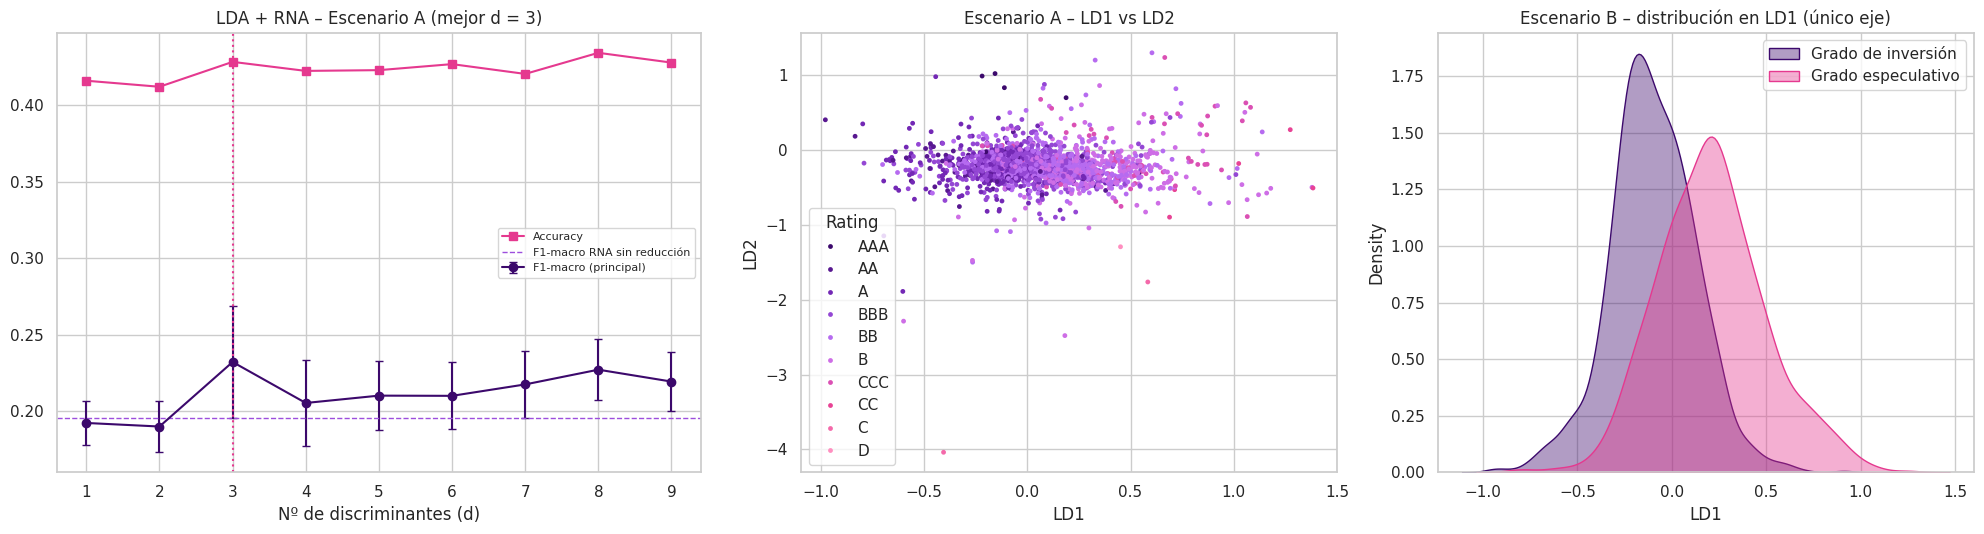

A – Base original (10 clases): mejor dimensión LDA d = 3 -> F1-macro 0.2321 +/- 0.0369 (sin reducción: 0.1953 +/- 0.0217)
B – Base agrupada (2 clases): mejor dimensión LDA d = 1 -> F1-macro 0.7208 +/- 0.0301 (sin reducción: 0.7379 +/- 0.0246)


In [74]:
mejor_lda = {}
for k in ESCENARIOS:
    d_ = results_lda[results_lda["Escenario"] == k].sort_values("F1-macro", ascending=False).iloc[0]
    mejor_lda[k] = {"d": int(d_["d"]), "r": rna_lda[(k, int(d_["d"]))]}

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1.2, 1, 1]})
dA = results_lda[results_lda["Escenario"] == "A"]
axes[0].errorbar(dA["d"], dA["F1-macro"], yerr=dA["f1_std"], marker="o", color=MORADO, capsize=3, label="F1-macro (principal)")
axes[0].plot(dA["d"], dA["Accuracy"], marker="s", color=ROSADO, label="Accuracy")
axes[0].axhline(base["A"]["f1"], color=LILA, ls="--", lw=1, label="F1-macro RNA sin reducción")
axes[0].axvline(mejor_lda["A"]["d"], color=ROSADO, ls=":")
axes[0].set_title(f"LDA + RNA – Escenario A (mejor d = {mejor_lda['A']['d']})")
axes[0].set_xlabel("Nº de discriminantes (d)"); axes[0].legend(fontsize=8)

ZA = lda_full["A"].transform(X_lda)
sns.scatterplot(x=ZA[:, 0], y=ZA[:, 1], hue=df_modelo["Rating"], palette=paleta(10), s=12, linewidth=0, ax=axes[1])
axes[1].set_title("Escenario A – LD1 vs LD2"); axes[1].set_xlabel("LD1"); axes[1].set_ylabel("LD2")

ZB = lda_full["B"].transform(X_lda)[:, 0]
for g, colr in zip(nombres_binaria, [MORADO, ROSADO]):
    sns.kdeplot(ZB[df_modelo["Grado"] == g], fill=True, color=colr, alpha=.4, label=g, ax=axes[2])
axes[2].set_title("Escenario B – distribución en LD1 (único eje)"); axes[2].set_xlabel("LD1"); axes[2].legend()
plt.tight_layout(); plt.show()

for k, e in ESCENARIOS.items():
    print(f"{e['nombre']}: mejor dimensión LDA d = {mejor_lda[k]['d']} "
          f"-> F1-macro {fmt(mejor_lda[k]['r'])} (sin reducción: {fmt(base[k])})")

**Análisis del punto 4 – ¿con qué dimensión se obtienen los mejores resultados?**
- **Escenario B (2 clases):** LDA solo puede producir **1 discriminante**, así que *d* = 1 es la única (y por tanto la mejor) opción. Toda la información útil para separar grado de inversión de especulativo se resume en **una sola variable**. Las curvas de densidad muestran cuánto se solapan los dos grados sobre ese eje: si el solapamiento es grande, la RNA no puede superar mucho la línea base.
- **Escenario A (10 clases):** el gráfico de barras muestra que los **primeros 1–3 discriminantes** concentran la mayor parte de la separación entre clases, porque las calificaciones siguen un **orden** (AAA → D) que se refleja sobre todo en LD1. Lo esperable es que el desempeño crezca rápido hasta *d* ≈ 2–4 y luego se estabilice; la mejor *d* exacta la imprime la celda anterior.
- **LDA vs. PCA:** con muchas menos dimensiones, LDA suele igualar o superar a PCA, porque **usa la variable de salida** para construir los ejes, mientras que PCA solo busca varianza. Su limitación es que solo capta separaciones **lineales** y depende de estimar bien las medias de cada clase; para AAA, CC, C y D (≤ 7 muestras) esas medias son muy poco confiables.

## 15. Comparación final de las estrategias de reducción de dimensión (ambos escenarios)

,Escenario,Estrategia,Dimensión,F1-macro ± desv,Accuracy,Bal. accuracy,F1-macro,Tiempo RNA (s)
0,A – Base original (10 clases),Sin reducción (37 variables),37,0.1953 +/- 0.0217,0.4194,0.1971,0.1953,37.8274
1,A – Base original (10 clases),"SFFS (Regresión logística, capas (32,))",14,0.1962 +/- 0.0260,0.4076,0.1939,0.1962,39.2595
2,A – Base original (10 clases),PCA,30,0.2067 +/- 0.0155,0.4372,0.2087,0.2067,39.0007
3,A – Base original (10 clases),LDA,3,0.2321 +/- 0.0369,0.4283,0.2337,0.2321,56.0509
4,B – Base agrupada (2 clases),Sin reducción (37 variables),37,0.7379 +/- 0.0246,0.7516,0.7340,0.7379,28.0135
5,B – Base agrupada (2 clases),"SFFS (Regresión logística, capas (32, 16))",11,0.7315 +/- 0.0256,0.7491,0.7277,0.7315,32.9752
6,B – Base agrupada (2 clases),PCA,25,0.7593 +/- 0.0132,0.7698,0.7557,0.7593,40.2442
7,B – Base agrupada (2 clases),LDA,1,0.7208 +/- 0.0301,0.7314,0.7186,0.7208,29.6661


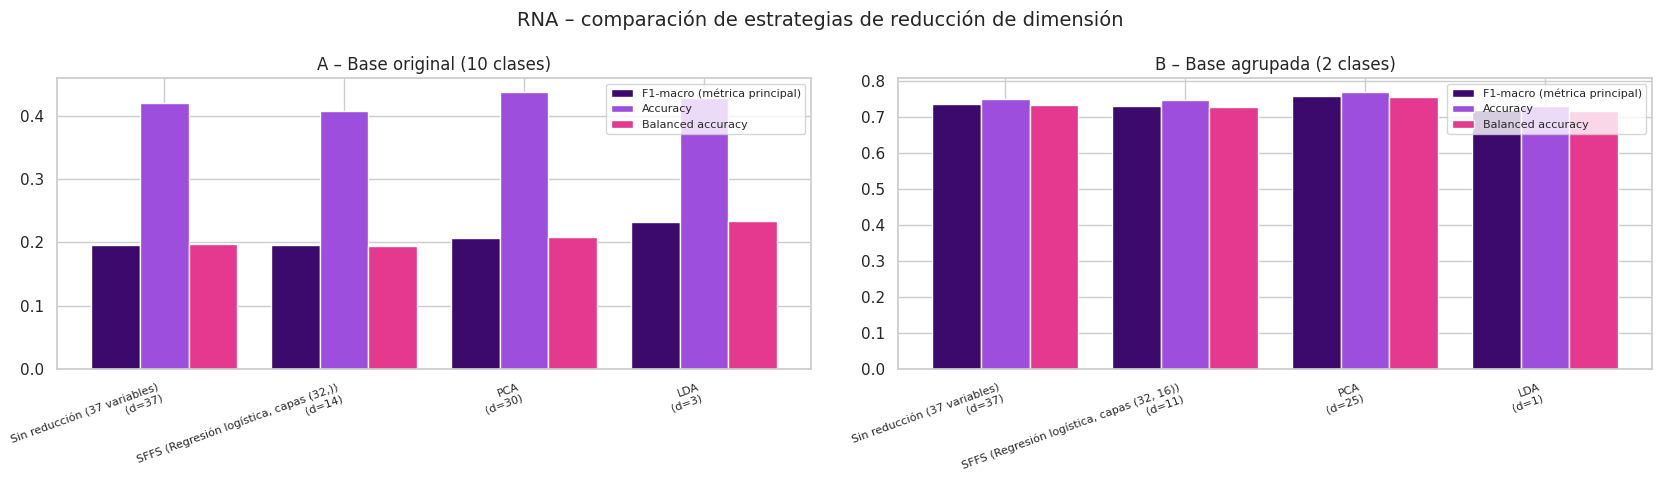

In [75]:
filas = []
for k, e in ESCENARIOS.items():
    m = mejor_sffs[k]
    for nombre, dim, r in [
        ("Sin reducción (37 variables)", 37, base[k]),
        (f"SFFS ({m['wrapper']}, capas {m['capas']})", len(m["variables"]), m["r"]),
        ("PCA", mejor_pca[k]["d"], mejor_pca[k]["r"]),
        ("LDA", mejor_lda[k]["d"], mejor_lda[k]["r"]),
    ]:
        filas.append({"Escenario": e["nombre"], "Estrategia": nombre, "Dimensión": dim,
                      "F1-macro ± desv": fmt(r), "Accuracy": r["acc"], "Bal. accuracy": r["bacc"],
                      "F1-macro": r["f1"], "Tiempo RNA (s)": r["tiempo_s"], "_r": r})
results_final = pd.DataFrame(filas)
display(results_final.drop(columns="_r").round(4))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for a, (esc, d) in zip(axes, results_final.groupby("Escenario", sort=False)):
    x = np.arange(len(d)); w = .27
    a.bar(x - w, d["F1-macro"], w, color=MORADO, label="F1-macro (métrica principal)")
    a.bar(x, d["Accuracy"], w, color=LILA, label="Accuracy")
    a.bar(x + w, d["Bal. accuracy"], w, color=ROSADO, label="Balanced accuracy")
    a.set_xticks(x); a.set_xticklabels([f"{s}\n(d={n})" for s, n in zip(d["Estrategia"], d["Dimensión"])],
                                       rotation=20, ha="right", fontsize=8)
    a.set_title(esc); a.legend(fontsize=8)
plt.suptitle("RNA – comparación de estrategias de reducción de dimensión", fontsize=14)
plt.tight_layout(); plt.show()

Mejor método – A – Base original (10 clases): LDA (dimensión 3) | F1-macro 0.2321 +/- 0.0369 | accuracy 0.4283
              precision    recall  f1-score   support

         AAA       1.00      0.14      0.25         7
          AA       0.00      0.00      0.00        89
           A       0.42      0.45      0.43       398
         BBB       0.43      0.65      0.52       671
          BB       0.41      0.28      0.33       490
           B       0.48      0.37      0.42       302
         CCC       0.21      0.06      0.10        64
          CC       0.00      0.00      0.00         5
           C       0.00      0.00      0.00         2
           D       0.00      0.00      0.00         1

    accuracy                           0.43      2029
   macro avg       0.29      0.20      0.20      2029
weighted avg       0.40      0.43      0.40      2029

Mejor método – B – Base agrupada (2 clases): PCA (dimensión 25) | F1-macro 0.7593 +/- 0.0132 | accuracy 0.7698
                   

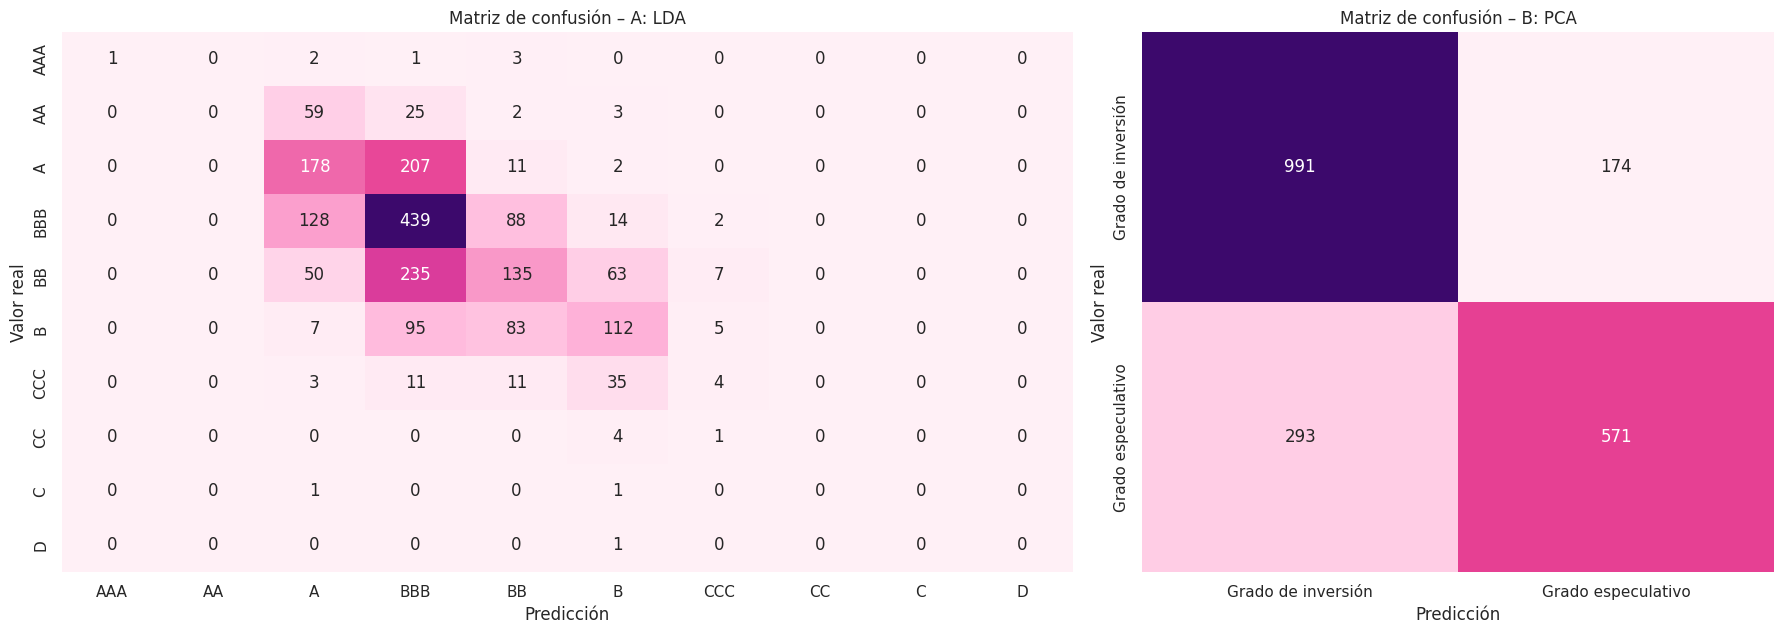

In [76]:
# Mejor estrategia por escenario y su matriz de confusión (predicciones fuera de fold)
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.6, 1]})
for a, (k, e) in zip(axes, ESCENARIOS.items()):
    d = results_final[results_final["Escenario"] == e["nombre"]].sort_values("F1-macro", ascending=False)
    best = d.iloc[0]
    print(f"Mejor método – {e['nombre']}: {best['Estrategia']} (dimensión {best['Dimensión']}) | "
          f"F1-macro {best['F1-macro ± desv']} | accuracy {best['Accuracy']:.4f}")
    y_pred = best["_r"]["y_oof"]
    cm = confusion_matrix(e["y"], y_pred, labels=range(e["n_clases"]))
    sns.heatmap(cm, annot=True, fmt="d", cmap=CMAP_MR_CLARO, ax=a, cbar=False,
                xticklabels=e["etiquetas"], yticklabels=e["etiquetas"])
    a.set_xlabel("Predicción"); a.set_ylabel("Valor real")
    a.set_title(f"Matriz de confusión – {k}: {best['Estrategia']}")
    print(classification_report(e["y"], y_pred, labels=range(e["n_clases"]),
                                target_names=e["etiquetas"], zero_division=0))
plt.tight_layout(); plt.show()

## 16. Conclusiones de la Parte 2

### Lo realizado
- Se resolvió el problema de clasificación con **Redes Neuronales Artificiales** (MLP en Keras), validando con **`StratifiedKFold` de 5 *folds*** y **F1‑macro** como métrica en los **dos escenarios**: base original (10 clases) y base agrupada (2 clases).
- **Punto 1 – SFFS (mlxtend):** se probaron 4 funciones *wrapper* (árbol de decisión, KNN, regresión logística y Random Forest) y 4 arquitecturas de RNA. Se eligió la mejor combinación por escenario.
- **Punto 2:** se identificaron las variables más discriminantes por su frecuencia de selección, el paso en que entraron al SFFS y la ganancia de F1‑macro que aportaron.
- **Punto 3 – PCA (mlxtend):** se evaluaron distintas dimensiones *d* y se reportó la mejor para cada escenario.
- **Punto 4 – LDA (mlxtend):** se evaluó *d* = 1…9 en el escenario A y *d* = 1 (único posible) en el B.

### Interpretación general
- **El escenario B (2 clases) es mucho más fácil de resolver** que el A: sus clases están balanceadas y la diferencia entre grado de inversión y especulativo se refleja con claridad en la rentabilidad, el flujo de caja y el endeudamiento. En el escenario A la RNA acierta sobre todo las clases grandes (A, BBB, BB, B) y casi nunca las extremas.
- **SFFS** produce el modelo más **interpretable**: trabaja con variables originales con sentido financiero y elimina las redundantes. **LDA** logra la mayor compresión (1 a pocos ejes) porque usa la etiqueta. **PCA** necesita más componentes, porque no busca separar clases sino retener varianza.
- La mejor estrategia de cada escenario es la que se imprime en la celda anterior. Si la diferencia con "sin reducción" es pequeña (dentro de la desviación entre *folds*), conviene la estrategia de **menor dimensión**: es más simple, más rápida y generaliza mejor.